# Formula 1 podium prediction

The question is whether one driver finishes on the podium in one race. The label is `positionOrder <= 3`. The cutoff is after qualifying and before the race starts, so the race result, laps, pit stops, status, points, and the standings published for that same race are not features.

The notebook is in the order the brief asks for. Sections 1–11 audit and clean the 14 raw tables and build one row per `(raceId, driverId)`. Section 12 builds the leakage-safe feature table and shows why those features were kept. Sections 13–15 answer the three data-engineering questions. Sections 16–19 fit the models, the ablation, the two preprocessing orders, and the global and local explanations. Section 20 scores one complete row and the same row with two fields removed.

Raw CSVs are read and never written. Run All from the top. On Kaggle, add the Vopani Formula 1 dataset under Input first.


## 1. Setup

Raw CSVs are read and never written. Every cleaned table is a new file. The rules themselves live in `src/f1_clean.py`, and `scripts/test_cleaning.py` checks them.

The 14 tables named in the brief are `circuits`, `constructors`, `constructor_results`, `constructor_standings`, `drivers`, `driver_standings`, `races`, `results`, `qualifying`, `lap_times`, `pit_stops`, `sprint_results`, `seasons`, and `status`. They are the Ergast extracts distributed as the Kaggle dataset *Formula 1 World Championship (1950–2024)*. This copy was downloaded on 6 October 2026 from the TracingInsights RaceData mirror of that dataset (CC0):

`https://github.com/TracingInsights/RaceData/releases/latest/download/data.zip`

The zip also contains safety-car and red-flag files. Those are outside the brief, so they were moved to `data/not_in_brief` and are not loaded. The extract on disk includes completed races after 2024. Those races are kept and flagged. They are not deleted.

In [1]:
CLEAN_SOURCE = '"""Cleaning rules for the Formula 1 podium-prediction milestone.\n\nRaw CSVs are read and never written. Sentinels are replaced on copies, types are\napplied, the broken lap-time key is repaired, and a separate driver-race table\nis built with one row per (raceId, driverId).\n\nThis module does not build model features. Columns that are only known after\nthe race are labeled as such in DRIVER_RACE_DICTIONARY.\n"""\n\nfrom __future__ import annotations\n\nimport hashlib\nfrom dataclasses import dataclass\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\nSENTINEL = r"\\N"\nASSIGNMENT_LAST_YEAR = 2024\n\nTABLES = (\n    "circuits",\n    "constructors",\n    "constructor_results",\n    "constructor_standings",\n    "drivers",\n    "driver_standings",\n    "races",\n    "results",\n    "qualifying",\n    "lap_times",\n    "pit_stops",\n    "sprint_results",\n    "seasons",\n    "status",\n)\n\n# Primary keys of the Ergast extracts. lap_times is the only one that fails\n# on the raw files; cleaning makes it unique.\nPRIMARY_KEYS: dict[str, list[str]] = {\n    "circuits": ["circuitId"],\n    "constructors": ["constructorId"],\n    "constructor_results": ["constructorResultsId"],\n    "constructor_standings": ["constructorStandingsId"],\n    "drivers": ["driverId"],\n    "driver_standings": ["driverStandingsId"],\n    "races": ["raceId"],\n    "results": ["resultId"],\n    "qualifying": ["qualifyId"],\n    "lap_times": ["raceId", "driverId", "lap"],\n    "pit_stops": ["raceId", "driverId", "stop"],\n    "sprint_results": ["resultId"],\n    "seasons": ["year"],\n    "status": ["statusId"],\n}\n\n# Grain checks that are not the single-column primary key.\nGRAIN_KEYS: dict[str, list[str]] = {\n    "results_driver_race": ["raceId", "driverId"],\n    "qualifying_driver_race": ["raceId", "driverId"],\n    "sprint_driver_race": ["raceId", "driverId"],\n    "driver_standings_driver_race": ["raceId", "driverId"],\n    "constructor_standings_race": ["raceId", "constructorId"],\n    "constructor_results_race": ["raceId", "constructorId"],\n}\n\nGRAIN_TABLE = {\n    "results_driver_race": "results",\n    "qualifying_driver_race": "qualifying",\n    "sprint_driver_race": "sprint_results",\n    "driver_standings_driver_race": "driver_standings",\n    "constructor_standings_race": "constructor_standings",\n    "constructor_results_race": "constructor_results",\n}\n\n# child table, child column, parent table, parent column\nFOREIGN_KEYS = (\n    ("races", "circuitId", "circuits", "circuitId"),\n    ("results", "raceId", "races", "raceId"),\n    ("results", "driverId", "drivers", "driverId"),\n    ("results", "constructorId", "constructors", "constructorId"),\n    ("results", "statusId", "status", "statusId"),\n    ("qualifying", "raceId", "races", "raceId"),\n    ("qualifying", "driverId", "drivers", "driverId"),\n    ("qualifying", "constructorId", "constructors", "constructorId"),\n    ("driver_standings", "raceId", "races", "raceId"),\n    ("driver_standings", "driverId", "drivers", "driverId"),\n    ("constructor_standings", "raceId", "races", "raceId"),\n    ("constructor_standings", "constructorId", "constructors", "constructorId"),\n    ("constructor_results", "raceId", "races", "raceId"),\n    ("constructor_results", "constructorId", "constructors", "constructorId"),\n    ("lap_times", "raceId", "races", "raceId"),\n    ("lap_times", "driverId", "drivers", "driverId"),\n    ("pit_stops", "raceId", "races", "raceId"),\n    ("pit_stops", "driverId", "drivers", "driverId"),\n    ("sprint_results", "raceId", "races", "raceId"),\n    ("sprint_results", "driverId", "drivers", "driverId"),\n    ("sprint_results", "constructorId", "constructors", "constructorId"),\n    ("sprint_results", "statusId", "status", "statusId"),\n)\n\nINTEGER_COLUMNS: dict[str, list[str]] = {\n    "circuits": ["circuitId"],\n    "constructors": ["constructorId"],\n    "constructor_results": ["constructorResultsId", "raceId", "constructorId"],\n    "constructor_standings": ["constructorStandingsId", "raceId", "constructorId", "position", "wins"],\n    "drivers": ["driverId", "number"],\n    "driver_standings": ["driverStandingsId", "raceId", "driverId", "position", "wins"],\n    "races": ["raceId", "year", "round", "circuitId"],\n    "results": [\n        "resultId", "raceId", "driverId", "constructorId", "number", "grid",\n        "position", "positionOrder", "laps", "milliseconds", "fastestLap", "rank", "statusId",\n    ],\n    "qualifying": ["qualifyId", "raceId", "driverId", "constructorId", "number", "position"],\n    "lap_times": ["raceId", "driverId", "lap", "position", "milliseconds"],\n    "pit_stops": ["raceId", "driverId", "stop", "lap", "milliseconds"],\n    "sprint_results": [\n        "resultId", "raceId", "driverId", "constructorId", "number", "grid",\n        "position", "positionOrder", "laps", "milliseconds", "fastestLap", "statusId", "rank",\n    ],\n    "seasons": ["year"],\n    "status": ["statusId"],\n}\n\nFLOAT_COLUMNS: dict[str, list[str]] = {\n    "circuits": ["lat", "lng", "alt"],\n    "constructor_results": ["points"],\n    "constructor_standings": ["points"],\n    "driver_standings": ["points"],\n    "results": ["points", "fastestLapSpeed"],\n    "sprint_results": ["points"],\n}\n\nDATE_COLUMNS: dict[str, list[str]] = {\n    "drivers": ["dob"],\n    "races": [\n        "date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date",\n    ],\n}\n\n# Clock strings such as 06:00:00. Kept as text and also combined with the date.\nCLOCK_COLUMNS: dict[str, list[str]] = {\n    "races": ["time", "fp1_time", "fp2_time", "fp3_time", "quali_time", "sprint_time"],\n}\n\nDURATION_COLUMNS: dict[str, list[str]] = {\n    "qualifying": ["q1", "q2", "q3"],\n    "lap_times": ["time"],\n    "pit_stops": ["duration"],\n    "results": ["fastestLapTime"],\n    "sprint_results": ["fastestLapTime"],\n}\n\nDRIVER_RACE_DICTIONARY = (\n    ("raceId", "identifier", "Race key. Already known when the race is scheduled."),\n    ("driverId", "identifier", "Driver key."),\n    ("resultId", "identifier", "resultId of the row kept by the collapse rule."),\n    ("year", "pre_race_context", "Season. Known before the race."),\n    ("round", "pre_race_context", "Round number. Known before the race."),\n    ("race_date", "pre_race_context", "Scheduled race date."),\n    ("circuitId", "pre_race_context", "Circuit. Known before the race."),\n    ("race_name", "pre_race_context", "Grand Prix name."),\n    ("constructorId", "pre_race_context", "Constructor on the kept row. When n_constructors > 1 the driver drove more than one car, so this is the car of the better classified stint, not necessarily the car they qualified."),\n    ("car_number", "pre_race_context", "Car number on the kept row."),\n    ("grid", "pre_race_context", "Starting grid. 0 means no grid slot (pit lane or did not start). Null means the source file omitted the grid for that row."),\n    ("n_result_rows", "audit", "How many results rows this driver had in this race before the collapse."),\n    ("n_constructors", "audit", "How many constructors those rows used."),\n    ("shared_entry", "audit", "True when n_result_rows > 1. These are shared drives or double entries, almost all from 1950-1964, plus one 1978 case."),\n    ("position", "post_race_label", "Official classified position. Null means not classified. Not a legal model feature: it is known only after the race."),\n    ("positionText", "post_race_label", "Official position text, including R, D, W, F, N. Not a legal model feature."),\n    ("positionOrder", "post_race_label", "Dense rank of every starter, including retirements. The brief defines the label from this column. Not a legal model feature."),\n    ("points", "post_race_label", "Points scored in this race. Not a legal model feature."),\n    ("laps", "post_race_label", "Laps completed. Not a legal model feature."),\n    ("statusId", "post_race_label", "Finishing status. Not a legal model feature."),\n    ("podium", "post_race_label", "Brief\'s label: positionOrder <= 3."),\n    ("official_podium", "post_race_label", "positionText is 1, 2, or 3. Kept so the one known disagreement with podium can be audited."),\n    ("podium_definition_conflict", "audit", "True when podium and official_podium disagree."),\n    ("in_assignment_window", "audit", "True when year <= 2024, the window named in the brief. Later completed races are retained and flagged, not deleted."),\n    ("collapse_rule", "audit", "Rule that chose resultId. The same rule is used on every row."),\n)\n\nCOLLAPSE_RULE = "best_classification"\n\n\n@dataclass\nclass CleaningResult:\n    cleaned: dict[str, pd.DataFrame]\n    sentinel_summary: pd.DataFrame\n    keys_before: pd.DataFrame\n    keys_after: pd.DataFrame\n    coercion_failures: pd.DataFrame\n    lap_conflict_summary: pd.DataFrame\n    lap_conflicts: pd.DataFrame\n    duplicate_rows: pd.DataFrame\n    rule_comparison: pd.DataFrame\n    driver_race: pd.DataFrame\n    races_without_results: pd.DataFrame\n    time_checks: pd.DataFrame\n    missing_policy: pd.DataFrame\n\n\ndef project_paths(root: Path | None = None) -> dict[str, Path]:\n    root = Path(root) if root is not None else Path(__file__).resolve().parents[1]\n    return {\n        "root": root,\n        "raw": root / "data" / "raw",\n        "cleaned": root / "data" / "cleaned",\n        "processed": root / "data" / "processed",\n        "audit": root / "data" / "audit",\n        "figures": root / "figures",\n    }\n\n\ndef file_sha256(path: Path) -> str:\n    digest = hashlib.sha256()\n    with path.open("rb") as handle:\n        for block in iter(lambda: handle.read(1 << 20), b""):\n            digest.update(block)\n    return digest.hexdigest()\n\n\ndef raw_hashes(raw_dir: Path) -> dict[str, str]:\n    return {name: file_sha256(raw_dir / f"{name}.csv") for name in TABLES}\n\n\ndef load_raw(raw_dir: Path) -> dict[str, pd.DataFrame]:\n    """Read the 14 assignment tables as strings, with no sentinel conversion."""\n    frames = {}\n    for name in TABLES:\n        path = raw_dir / f"{name}.csv"\n        frames[name] = pd.read_csv(path, dtype=str, keep_default_na=False)\n    return frames\n\n\ndef summarize_sentinels(raw: dict[str, pd.DataFrame]) -> pd.DataFrame:\n    rows = []\n    for name, frame in raw.items():\n        for column in frame.columns:\n            sentinel_n = int((frame[column] == SENTINEL).sum())\n            if sentinel_n == 0:\n                continue\n            rows.append({\n                "table": name,\n                "column": column,\n                "sentinel_n": sentinel_n,\n                "rows": len(frame),\n                "sentinel_share": sentinel_n / len(frame),\n            })\n    summary = pd.DataFrame(rows)\n    return summary.sort_values(["sentinel_share", "table", "column"], ascending=[False, True, True]).reset_index(drop=True)\n\n\n# What to do with each column that contains the \\N marker.\n# mean, median, and mode are not used: a blank here means "not recorded" or "did not happen".\nMISSING_POLICY: dict[tuple[str, str], tuple[str, str]] = {\n    ("constructor_results", "status"): (\n        "code as not disqualified",\n        "\\\\N means the constructor was not disqualified. Stored as disqualified=False. D stays True.",\n    ),\n    ("constructor_standings", "position"): (\n        "leave missing",\n        "One standings row is unranked. A median rank would invent a place.",\n    ),\n    ("drivers", "number"): (\n        "leave missing",\n        "Permanent numbers did not exist for most of the history. The mode would copy one modern number onto old drivers.",\n    ),\n    ("drivers", "code"): (\n        "leave missing",\n        "Three-letter codes did not exist for most of the history. The mode would copy one code onto old drivers.",\n    ),\n    ("driver_standings", "position"): (\n        "leave missing",\n        "The text is already \'-\': unranked. The mode would assign a championship place.",\n    ),\n    ("races", "time"): (\n        "leave missing",\n        "The start clock was not stored. An average of clock times is not a start time.",\n    ),\n    ("races", "fp1_date"): ("leave missing", "This session was not stored for that race."),\n    ("races", "fp1_time"): ("leave missing", "This session was not stored for that race."),\n    ("races", "fp2_date"): ("leave missing", "This session was not stored for that race."),\n    ("races", "fp2_time"): ("leave missing", "This session was not stored for that race."),\n    ("races", "fp3_date"): ("leave missing", "This session was not stored for that race."),\n    ("races", "fp3_time"): ("leave missing", "This session was not stored for that race."),\n    ("races", "quali_date"): ("leave missing", "This session was not stored for that race."),\n    ("races", "quali_time"): ("leave missing", "This session was not stored for that race."),\n    ("races", "sprint_date"): ("leave missing", "This race had no sprint, or the sprint date was not stored."),\n    ("races", "sprint_time"): ("leave missing", "This race had no sprint, or the sprint time was not stored."),\n    ("results", "number"): (\n        "leave missing",\n        "A few cars have no number. The mode would give them a number that already belongs to another car.",\n    ),\n    ("results", "grid"): (\n        "leave missing",\n        "The file omitted the grid for two whole races. The median grid would pretend those drivers started from midfield. Grid 0 is a real value and is not filled.",\n    ),\n    ("results", "position"): (\n        "leave missing",\n        "Empty means not classified. positionOrder is already filled. A median position would create a finish.",\n    ),\n    ("results", "time"): (\n        "leave missing",\n        "No finish clock was stored. A median time would give a retired car a finish time. Known only after the race.",\n    ),\n    ("results", "milliseconds"): (\n        "leave missing",\n        "No elapsed time was stored. Same column as the finish clock, in milliseconds.",\n    ),\n    ("results", "fastestLap"): (\n        "leave missing",\n        "No fastest lap was stored. Known only after the race.",\n    ),\n    ("results", "rank"): (\n        "leave missing",\n        "No fastest-lap rank was stored. Known only after the race.",\n    ),\n    ("results", "fastestLapTime"): (\n        "leave missing",\n        "No fastest-lap time was stored. A median lap time would invent one.",\n    ),\n    ("results", "fastestLapSpeed"): (\n        "leave missing",\n        "No fastest-lap speed was stored. The distribution is skewed, and a median would still invent a speed.",\n    ),\n    ("qualifying", "q1"): (\n        "leave missing",\n        "The driver set no Q1 time. A median lap time would invent one.",\n    ),\n    ("qualifying", "q2"): (\n        "leave missing",\n        "The driver did not reach Q2. A median would say they set a Q2 time.",\n    ),\n    ("qualifying", "q3"): (\n        "leave missing",\n        "The driver did not reach Q3. A median would say they set a Q3 time.",\n    ),\n    ("pit_stops", "duration"): (\n        "leave missing",\n        "Three stops have no duration. A median would hide a broken measurement. Pit stops happen during the race.",\n    ),\n    ("pit_stops", "milliseconds"): (\n        "leave missing",\n        "The same three stops have no duration in milliseconds.",\n    ),\n    ("sprint_results", "position"): (\n        "leave missing",\n        "The driver was not classified in the sprint.",\n    ),\n    ("sprint_results", "time"): (\n        "leave missing",\n        "No sprint finish clock was stored.",\n    ),\n    ("sprint_results", "milliseconds"): (\n        "leave missing",\n        "No sprint elapsed time was stored.",\n    ),\n    ("sprint_results", "fastestLap"): (\n        "leave missing",\n        "No sprint fastest lap was stored.",\n    ),\n    ("sprint_results", "fastestLapTime"): (\n        "leave missing",\n        "No sprint fastest-lap time was stored.",\n    ),\n    ("sprint_results", "statusId"): (\n        "leave missing",\n        "Two sprint rows have no status. The mode would mark them as the most common status.",\n    ),\n    ("sprint_results", "rank"): (\n        "leave missing",\n        "No sprint fastest-lap rank was stored.",\n    ),\n}\n\nDEFAULT_MISSING_POLICY = (\n    "leave missing",\n    "The marker is an absent value. Mean, median, and mode would invent one.",\n)\n\n\ndef missing_value_report(raw: dict[str, pd.DataFrame], cleaned: dict[str, pd.DataFrame]) -> pd.DataFrame:\n    """Record the method applied to every column that contained \\\\N. Nothing is imputed."""\n    rows = []\n    for name, frame in raw.items():\n        for column in frame.columns:\n            sentinel_n = int((frame[column] == SENTINEL).sum())\n            if sentinel_n == 0:\n                continue\n            method, reason = MISSING_POLICY.get((name, column), DEFAULT_MISSING_POLICY)\n            missing_after = int(cleaned[name][column].isna().sum())\n            rows.append({\n                "table": name,\n                "column": column,\n                "blank_markers": sentinel_n,\n                "method": method,\n                "values_filled": sentinel_n - missing_after,\n                "still_missing": missing_after,\n                "reason": reason,\n            })\n    status = raw["constructor_results"]["status"]\n    disqualified = cleaned["constructor_results"]["disqualified"]\n    rows.append({\n        "table": "constructor_results",\n        "column": "disqualified",\n        "blank_markers": int((status == SENTINEL).sum()),\n        "method": "filled with False",\n        "values_filled": int((~disqualified).sum()),\n        "still_missing": int(disqualified.isna().sum()),\n        "reason": "Each \\\\N in status was written here as False. Every row now has True or False.",\n    })\n    report = pd.DataFrame(rows)\n    if report.empty:\n        return report\n    return report.sort_values(["table", "column"]).reset_index(drop=True)\n\n\ndef replace_sentinels(frame: pd.DataFrame) -> pd.DataFrame:\n    """Turn the Ergast null marker into missing values. Does not change row count."""\n    cleaned = frame.copy()\n    return cleaned.mask(cleaned == SENTINEL, pd.NA)\n\n\ndef parse_duration_to_seconds(series: pd.Series) -> tuple[pd.Series, int]:\n    """Parse ss.sss, m:ss.sss, or h:mm:ss.sss. A leading + is removed by the caller when needed.\n\n    Returns the seconds and the number of non-missing values that did not parse.\n    """\n    text = series.astype("string").str.strip()\n    missing = text.isna() | (text == "")\n    n_colons = text.str.count(":").fillna(0)\n    parts = text.str.split(":", n=2, expand=True)\n    while parts.shape[1] < 3:\n        parts[parts.shape[1]] = pd.NA\n    numbers = [pd.to_numeric(parts[i], errors="coerce") for i in range(3)]\n    seconds = pd.Series(np.nan, index=series.index, dtype="float64")\n    one = (~missing) & (n_colons == 0)\n    two = (~missing) & (n_colons == 1)\n    three = (~missing) & (n_colons == 2)\n    seconds.loc[one] = numbers[0].loc[one]\n    seconds.loc[two] = numbers[0].loc[two] * 60 + numbers[1].loc[two]\n    seconds.loc[three] = numbers[0].loc[three] * 3600 + numbers[1].loc[three] * 60 + numbers[2].loc[three]\n    failed = int((~missing & seconds.isna()).sum())\n    return seconds, failed\n\n\ndef _cast_numeric(series: pd.Series, dtype: str) -> tuple[pd.Series, int]:\n    missing = series.isna()\n    numeric = pd.to_numeric(series, errors="coerce")\n    failed = ~missing & numeric.isna()\n    if dtype == "Int64":\n        fractional = numeric.notna() & ((numeric % 1) != 0)\n        failed = failed | fractional\n        numeric = numeric.mask(fractional)\n        numeric = numeric.astype("Int64")\n    else:\n        numeric = numeric.astype("float64")\n    return numeric, int(failed.sum())\n\n\ndef _cast_dates(series: pd.Series) -> tuple[pd.Series, int]:\n    missing = series.isna()\n    parsed = pd.to_datetime(series, format="%Y-%m-%d", errors="coerce")\n    failed = int((~missing & parsed.isna()).sum())\n    return parsed, failed\n\n\ndef _record_failure(rows: list[dict], table: str, column: str, failed: int) -> None:\n    if failed:\n        rows.append({"table": table, "column": column, "failed_n": failed})\n\n\ndef _apply_declared_types(name: str, frame: pd.DataFrame, failures: list[dict]) -> pd.DataFrame:\n    """Cast the columns this file actually has. A missing optional column is skipped.\n\n    The Kaggle extract does not always include `rank` (fastest-lap rank). That\n    field is only known after the race, so its absence does not block cleaning.\n    """\n    cleaned = frame.copy()\n    for column in INTEGER_COLUMNS.get(name, []):\n        if column not in cleaned.columns:\n            continue\n        cleaned[column], failed = _cast_numeric(cleaned[column], "Int64")\n        _record_failure(failures, name, column, failed)\n    for column in FLOAT_COLUMNS.get(name, []):\n        if column not in cleaned.columns:\n            continue\n        cleaned[column], failed = _cast_numeric(cleaned[column], "float64")\n        _record_failure(failures, name, column, failed)\n    for column in DATE_COLUMNS.get(name, []):\n        if column not in cleaned.columns:\n            continue\n        cleaned[column], failed = _cast_dates(cleaned[column])\n        _record_failure(failures, name, column, failed)\n    for column in DURATION_COLUMNS.get(name, []):\n        if column not in cleaned.columns:\n            continue\n        seconds, failed = parse_duration_to_seconds(cleaned[column])\n        cleaned[f"{column}_seconds"] = seconds\n        _record_failure(failures, name, f"{column}_seconds", failed)\n    return cleaned\n\n\ndef _parse_results_time(frame: pd.DataFrame, table: str, failures: list[dict]) -> pd.DataFrame:\n    """`time` mixes two different measurements. Keep them in separate columns.\n\n    A value with no leading + is the winner\'s elapsed race time.\n    A value with a leading + is the gap to the winner.\n    `milliseconds`, when present, is elapsed time for that car, including cars\n    whose `time` string is only a gap. It is not the gap itself.\n    """\n    cleaned = frame.copy()\n    if "time" not in cleaned.columns:\n        return cleaned\n    text = cleaned["time"].astype("string")\n    is_gap = text.str.startswith("+", na=False)\n    gap_seconds, gap_failed = parse_duration_to_seconds(text.where(is_gap).str.replace(r"^\\+", "", regex=True))\n    winner_seconds, winner_failed = parse_duration_to_seconds(text.where(~is_gap))\n    cleaned["gap_seconds"] = gap_seconds\n    cleaned["winner_time_seconds"] = winner_seconds\n    _record_failure(failures, table, "gap_seconds", gap_failed)\n    _record_failure(failures, table, "winner_time_seconds", winner_failed)\n    if "milliseconds" in cleaned.columns:\n        cleaned["elapsed_seconds"] = cleaned["milliseconds"].astype("Float64") / 1000\n    return cleaned\n\n\ndef _add_race_start(frame: pd.DataFrame, failures: list[dict]) -> pd.DataFrame:\n    cleaned = frame.copy()\n    date_text = cleaned["date"].dt.strftime("%Y-%m-%d")\n    clock = cleaned["time"].astype("string")\n    both = date_text.notna() & clock.notna()\n    stamp = pd.to_datetime(date_text.where(both) + " " + clock.where(both), errors="coerce")\n    failed = int((both & stamp.isna()).sum())\n    _record_failure(failures, "races", "race_start", failed)\n    cleaned["race_start"] = stamp\n    return cleaned\n\n\ndef _key_rows_for(name: str, frame: pd.DataFrame, keys: list[str], check: str) -> dict:\n    missing = frame[keys].isna().any(axis=1)\n    problem_rows = int(frame.duplicated(keys).sum())\n    return {\n        "table": name,\n        "check": check,\n        "columns": ", ".join(keys),\n        "rows": len(frame),\n        "null_key_rows": int(missing.sum()),\n        "problem_rows": problem_rows,\n        "passed": bool(missing.sum() == 0 and problem_rows == 0),\n    }\n\n\ndef audit_keys(frames: dict[str, pd.DataFrame]) -> pd.DataFrame:\n    rows = []\n    for name, keys in PRIMARY_KEYS.items():\n        rows.append(_key_rows_for(name, frames[name], keys, "primary_key"))\n    for grain_name, keys in GRAIN_KEYS.items():\n        table = GRAIN_TABLE[grain_name]\n        rows.append(_key_rows_for(grain_name, frames[table], keys, "grain"))\n    parent_ids = {name: set(frame[PRIMARY_KEYS[name][0]].dropna()) for name, frame in frames.items() if len(PRIMARY_KEYS[name]) == 1}\n    for child, column, parent, parent_column in FOREIGN_KEYS:\n        values = frames[child][column]\n        missing = values.isna()\n        orphans = ~missing & ~values.isin(parent_ids[parent])\n        rows.append({\n            "table": child,\n            "check": "foreign_key",\n            "columns": f"{column} -> {parent}.{parent_column}",\n            "rows": len(frames[child]),\n            "null_key_rows": int(missing.sum()),\n            "problem_rows": int(orphans.sum()),\n            "passed": bool(orphans.sum() == 0),\n        })\n    return pd.DataFrame(rows)\n\n\ndef deduplicate_lap_times(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:\n    """Make (raceId, driverId, lap) unique.\n\n    Exact copies are dropped. When two copies disagree, the faster time is kept\n    and both measurements are written to the conflict audit. Lap times happen\n    during the race, so this repair is for key integrity, not for model features.\n    """\n    keys = ["raceId", "driverId", "lap"]\n    ordered = frame.sort_values(keys + ["milliseconds"], kind="mergesort")\n    grouped = ordered.groupby(keys, dropna=False)["milliseconds"]\n    spread = grouped.agg(n="size", min_ms="min", max_ms="max").reset_index()\n    summary = pd.DataFrame([\n        {"kind": "unique_already", "groups": int((spread["n"] == 1).sum())},\n        {"kind": "exact_duplicate", "groups": int(((spread["n"] > 1) & (spread["min_ms"] == spread["max_ms"])).sum())},\n        {"kind": "one_millisecond", "groups": int(((spread["n"] > 1) & ((spread["max_ms"] - spread["min_ms"]) == 1)).sum())},\n        {"kind": "larger_conflict", "groups": int(((spread["n"] > 1) & ((spread["max_ms"] - spread["min_ms"]) > 1)).sum())},\n    ])\n    conflict_keys = spread.loc[spread["n"] > 1, keys]\n    conflict_rows = ordered.merge(conflict_keys, on=keys, how="inner")\n    conflict_rows = conflict_rows.copy()\n    conflict_rows["delta_ms"] = conflict_rows.groupby(keys)["milliseconds"].transform(lambda s: s.max() - s.min())\n    kept = ordered.drop_duplicates(keys, keep="first").reset_index(drop=True)\n    return kept, summary, conflict_rows.reset_index(drop=True)\n\n\ndef collapse_entries(results: pd.DataFrame, rule: str) -> pd.DataFrame:\n    """Keep one results row per driver per race.\n\n    best_classification: lowest positionOrder, then most laps, then smallest resultId.\n    most_laps: most laps, then lowest positionOrder, then smallest resultId.\n    """\n    if rule == "best_classification":\n        sort_cols = ["raceId", "driverId", "positionOrder", "laps", "resultId"]\n        ascending = [True, True, True, False, True]\n    elif rule == "most_laps":\n        sort_cols = ["raceId", "driverId", "laps", "positionOrder", "resultId"]\n        ascending = [True, True, False, True, True]\n    else:\n        raise ValueError(f"Unknown collapse rule: {rule}")\n    ordered = results.sort_values(sort_cols, ascending=ascending, kind="mergesort")\n    return ordered.drop_duplicates(["raceId", "driverId"], keep="first")\n\n\ndef compare_collapse_rules(results: pd.DataFrame) -> pd.DataFrame:\n    """Run both candidate rules on duplicate pairs only."""\n    duplicate = results["n_result_rows"] > 1 if "n_result_rows" in results.columns else results.duplicated(["raceId", "driverId"], keep=False)\n    subset = results.loc[duplicate].copy()\n    if "n_result_rows" not in subset.columns:\n        subset["n_result_rows"] = subset.groupby(["raceId", "driverId"])["resultId"].transform("size")\n    best = collapse_entries(subset, "best_classification")\n    laps = collapse_entries(subset, "most_laps")\n    compared = best[["raceId", "driverId", "resultId", "positionOrder", "laps", "constructorId", "grid"]].merge(\n        laps[["raceId", "driverId", "resultId", "positionOrder", "laps", "constructorId", "grid"]],\n        on=["raceId", "driverId"],\n        suffixes=("_best", "_laps"),\n    )\n    compared["same_row"] = compared["resultId_best"] == compared["resultId_laps"]\n    compared["same_position"] = compared["positionOrder_best"] == compared["positionOrder_laps"]\n    compared["same_podium"] = (compared["positionOrder_best"] <= 3) == (compared["positionOrder_laps"] <= 3)\n    return compared\n\n\ndef build_driver_race(results: pd.DataFrame, races: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:\n    """One row per driver per race.\n\n    Rule, in order: better classified result (lower positionOrder), then more\n    laps, then the smaller resultId. positionOrder is first because the label\n    is the driver\'s finishing result. The most-laps rule is computed as a check,\n    not as the rule that is stored.\n    """\n    working = results.copy()\n    working["n_result_rows"] = working.groupby(["raceId", "driverId"])["resultId"].transform("size")\n    working["n_constructors"] = working.groupby(["raceId", "driverId"])["constructorId"].transform("nunique")\n    comparison = compare_collapse_rules(working)\n    kept = collapse_entries(working, COLLAPSE_RULE).copy()\n    kept["shared_entry"] = kept["n_result_rows"] > 1\n    kept["podium"] = kept["positionOrder"] <= 3\n    kept["official_podium"] = kept["positionText"].isin(["1", "2", "3"])\n    kept["podium_definition_conflict"] = kept["podium"] != kept["official_podium"]\n    kept["collapse_rule"] = COLLAPSE_RULE\n\n    context = races[["raceId", "year", "round", "date", "circuitId", "name"]].rename(\n        columns={"date": "race_date", "name": "race_name"}\n    )\n    driver_race = kept.merge(context, on="raceId", how="left", validate="many_to_one")\n    driver_race["in_assignment_window"] = driver_race["year"] <= ASSIGNMENT_LAST_YEAR\n    driver_race = driver_race.rename(columns={"number": "car_number"})\n    columns = [name for name, _, _ in DRIVER_RACE_DICTIONARY]\n    driver_race = driver_race[columns].sort_values(["year", "round", "positionOrder", "driverId"]).reset_index(drop=True)\n\n    duplicate_rows = working.loc[working["n_result_rows"] > 1].copy()\n    duplicate_rows["kept"] = duplicate_rows["resultId"].isin(set(driver_race["resultId"]))\n    return driver_race, duplicate_rows, comparison\n\n\ndef time_consistency(cleaned: dict[str, pd.DataFrame]) -> pd.DataFrame:\n    """Parsed strings should match the millisecond columns already in the file."""\n    rows = []\n\n    results = cleaned["results"]\n    absolute = results["winner_time_seconds"].notna() & results["elapsed_seconds"].notna()\n    if absolute.any():\n        delta = (results.loc[absolute, "winner_time_seconds"] - results.loc[absolute, "elapsed_seconds"]).abs()\n        rows.append({"check": "results winner time vs milliseconds", "rows": int(absolute.sum()), "max_abs_seconds": float(delta.max())})\n\n    laps = cleaned["lap_times"]\n    lap_delta = (laps["time_seconds"] - laps["milliseconds"].astype("float64") / 1000).abs()\n    rows.append({"check": "lap time string vs milliseconds", "rows": int(lap_delta.notna().sum()), "max_abs_seconds": float(lap_delta.max())})\n\n    pits = cleaned["pit_stops"]\n    known = pits["duration_seconds"].notna() & pits["milliseconds"].notna()\n    pit_delta = (pits.loc[known, "duration_seconds"] - pits.loc[known, "milliseconds"].astype("float64") / 1000).abs()\n    rows.append({\n        "check": "pit duration string vs milliseconds",\n        "rows": int(known.sum()),\n        "max_abs_seconds": float(pit_delta.max()) if known.any() else 0.0,\n    })\n    return pd.DataFrame(rows)\n\n\ndef clean_tables(raw: dict[str, pd.DataFrame]) -> CleaningResult:\n    keys_before = audit_keys(raw)\n    sentinel_summary = summarize_sentinels(raw)\n    failures: list[dict] = []\n    cleaned: dict[str, pd.DataFrame] = {}\n    for name, frame in raw.items():\n        typed = _apply_declared_types(name, replace_sentinels(frame), failures)\n        if name in {"results", "sprint_results"}:\n            typed = _parse_results_time(typed, name, failures)\n        if name == "races":\n            typed = _add_race_start(typed, failures)\n        if name == "constructor_results":\n            # In this column \\N means "not disqualified", not "status unknown".\n            typed["disqualified"] = typed["status"].eq("D")\n        if name == "results":\n            typed["classified"] = typed["position"].notna()\n        cleaned[name] = typed\n\n    cleaned["lap_times"], lap_summary, lap_conflicts = deduplicate_lap_times(cleaned["lap_times"])\n    driver_race, duplicate_rows, comparison = build_driver_race(cleaned["results"], cleaned["races"])\n    keys_after = audit_keys(cleaned)\n    # The modeling grain is a new table, so add its key check beside the source-table audit.\n    grain = _key_rows_for("driver_race", driver_race, ["raceId", "driverId"], "grain")\n    keys_after = pd.concat([keys_after, pd.DataFrame([grain])], ignore_index=True)\n\n    result_races = set(cleaned["results"]["raceId"])\n    missing_results = cleaned["races"].loc[~cleaned["races"]["raceId"].isin(result_races), ["raceId", "year", "round", "name", "date"]].copy()\n    missing_results = missing_results.sort_values(["year", "round"]).reset_index(drop=True)\n\n    return CleaningResult(\n        cleaned=cleaned,\n        sentinel_summary=sentinel_summary,\n        keys_before=keys_before,\n        keys_after=keys_after,\n        coercion_failures=pd.DataFrame(failures, columns=["table", "column", "failed_n"]),\n        lap_conflict_summary=lap_summary,\n        lap_conflicts=lap_conflicts,\n        duplicate_rows=duplicate_rows,\n        rule_comparison=comparison,\n        driver_race=driver_race,\n        races_without_results=missing_results,\n        time_checks=time_consistency(cleaned),\n        missing_policy=missing_value_report(raw, cleaned),\n    )\n\n\ndef save_outputs(result: CleaningResult, paths: dict[str, Path]) -> None:\n    for folder in ("cleaned", "processed", "audit"):\n        paths[folder].mkdir(parents=True, exist_ok=True)\n    for name, frame in result.cleaned.items():\n        frame.to_csv(paths["cleaned"] / f"{name}.csv", index=False)\n    result.driver_race.to_csv(paths["processed"] / "driver_race.csv", index=False)\n    dictionary = pd.DataFrame(DRIVER_RACE_DICTIONARY, columns=["column", "role", "meaning"])\n    dictionary.to_csv(paths["processed"] / "driver_race_dictionary.csv", index=False)\n    result.sentinel_summary.to_csv(paths["audit"] / "sentinel_summary.csv", index=False)\n    result.keys_before.to_csv(paths["audit"] / "keys_before.csv", index=False)\n    result.keys_after.to_csv(paths["audit"] / "keys_after.csv", index=False)\n    result.coercion_failures.to_csv(paths["audit"] / "coercion_failures.csv", index=False)\n    result.lap_conflict_summary.to_csv(paths["audit"] / "lap_time_conflict_summary.csv", index=False)\n    result.lap_conflicts.to_csv(paths["audit"] / "lap_time_conflicts.csv", index=False)\n    result.duplicate_rows.to_csv(paths["audit"] / "duplicate_result_rows.csv", index=False)\n    result.rule_comparison.to_csv(paths["audit"] / "collapse_rule_comparison.csv", index=False)\n    result.races_without_results.to_csv(paths["audit"] / "races_without_results.csv", index=False)\n    result.time_checks.to_csv(paths["audit"] / "time_checks.csv", index=False)\n    result.missing_policy.to_csv(paths["audit"] / "missing_value_policy.csv", index=False)\n'
FEATURES_SOURCE = '"""Leakage-safe features for one driver in one race.\n\nThe prediction cutoff is after qualifying and before the race starts.\nCurrent-race results, points, laps, status, pit stops, and the standings\npublished for this race are not features. Rolling form and entering\nstandings use only earlier races.\n"""\n\nfrom __future__ import annotations\n\nimport numpy as np\nimport pandas as pd\n\n# First season in which every completed race in this extract has qualifying.\nQUALIFYING_COMPLETE_FROM = 2003\nTRAIN_LAST_YEAR = 2018\nVALIDATION_LAST_YEAR = 2021\nTEST_LAST_YEAR = 2024\n\nFEATURE_DICTIONARY = (\n    ("grid", "grid", "Starting grid after penalties. Known before the race. A recorded 0 means no grid slot, so it is stored as missing: a numeric 0 would look better than pole. The blank is not filled with a mean."),\n    ("no_grid_slot", "grid", "1 when the source grid is 0. Those starts are not the front of the grid. In 2003-2024 none of them finish on the podium."),\n    ("front_row", "grid", "1 when the recorded grid is 1 or 2, otherwise 0. Missing only when the grid number itself is missing. A grid of 0 is front_row 0."),\n    ("quali_position", "qualifying", "Official qualifying position for this race. Known after qualifying. Missing when that session is not in the file."),\n    ("reached_q3", "qualifying", "1 when the driver set a Q3 time. Missing for a whole race that did not use Q3, so a blank is not treated as an elimination."),\n    ("quali_position_missing", "qualifying", "1 when quali_position is missing, so an imputed position is not mistaken for a real one."),\n    ("driver_podium_rate_last5", "form", "Share of this driver\'s previous 5 starts that were podiums. This race is excluded."),\n    ("driver_points_last5", "form", "Points from this driver\'s previous 5 starts. This race\'s points are excluded."),\n    ("constructor_podium_rate_last5", "form", "Mean podium share of this constructor\'s cars over its previous 5 races. This race is excluded."),\n    ("career_starts", "form", "Number of race starts this driver had before this one."),\n    ("form_missing", "form", "1 on a driver\'s first start in the file, when the previous-5 rates do not exist."),\n    ("driver_standing_entering", "standings", "Driver championship position after the previous round. The standings row for this race is not used."),\n    ("constructor_standing_entering", "standings", "Constructor championship position after the previous round."),\n    ("standing_missing", "standings", "1 when there is no driver standings row for the previous round. That includes every round 1."),\n    ("season_round", "standings", "Round number in the season. It is known when the calendar is published."),\n    ("home_race", "home", "1 when the circuit\'s country matches the driver\'s nationality. A dual national matches either country."),\n)\n\nFEATURE_COLUMNS = [name for name, _, _ in FEATURE_DICTIONARY]\nFEATURE_GROUPS: dict[str, list[str]] = {}\nfor _name, _group, _meaning in FEATURE_DICTIONARY:\n    FEATURE_GROUPS.setdefault(_group, []).append(_name)\n\n# Post-race fields. They may be used to build a shifted feature, and they must\n# not appear as columns the model is allowed to see.\nLEAKAGE_COLUMNS = (\n    "position",\n    "positionText",\n    "positionOrder",\n    "points",\n    "laps",\n    "statusId",\n    "fastestLap",\n    "rank",\n    "milliseconds",\n    "official_podium",\n)\n\n# Nationality strings in drivers.csv, after stripping whitespace.\n# Circuit countries keep the file\'s own names, including both "USA" and "United States".\nNATIONALITY_COUNTRIES = {\n    "American": ("USA", "United States"),\n    "American-Italian": ("USA", "United States", "Italy"),\n    "Argentine": ("Argentina",),\n    "Argentine-Italian": ("Argentina", "Italy"),\n    "Argentinian": ("Argentina",),\n    "Australian": ("Australia",),\n    "Austrian": ("Austria",),\n    "Belgian": ("Belgium",),\n    "Brazilian": ("Brazil",),\n    "British": ("UK",),\n    "Canadian": ("Canada",),\n    "Chilean": ("Chile",),\n    "Chinese": ("China",),\n    "Colombian": ("Colombia",),\n    "Czech": ("Czech Republic",),\n    "Danish": ("Denmark",),\n    "Dutch": ("Netherlands",),\n    "East German": ("Germany",),\n    "Finnish": ("Finland",),\n    "French": ("France",),\n    "German": ("Germany",),\n    "Hungarian": ("Hungary",),\n    "Indian": ("India",),\n    "Indonesian": ("Indonesia",),\n    "Irish": ("Ireland",),\n    "Italian": ("Italy",),\n    "Japanese": ("Japan",),\n    "Liechtensteiner": ("Liechtenstein",),\n    "Malaysian": ("Malaysia",),\n    "Mexican": ("Mexico",),\n    "Monegasque": ("Monaco",),\n    "New Zealander": ("New Zealand",),\n    "Polish": ("Poland",),\n    "Portuguese": ("Portugal",),\n    "Rhodesian": ("Rhodesia",),\n    "Russian": ("Russia",),\n    "South African": ("South Africa",),\n    "Spanish": ("Spain",),\n    "Swedish": ("Sweden",),\n    "Swiss": ("Switzerland",),\n    "Thai": ("Thailand",),\n    "Uruguayan": ("Uruguay",),\n    "Venezuelan": ("Venezuela",),\n}\n\n\ndef feature_dictionary_frame() -> pd.DataFrame:\n    return pd.DataFrame(FEATURE_DICTIONARY, columns=["column", "group", "meaning"])\n\n\ndef assign_split(year: pd.Series) -> pd.Series:\n    """Chronological split. The test years are never used to choose a model."""\n    split = pd.Series("excluded", index=year.index, dtype="object")\n    split.loc[year.between(QUALIFYING_COMPLETE_FROM, TRAIN_LAST_YEAR)] = "train"\n    split.loc[year.between(TRAIN_LAST_YEAR + 1, VALIDATION_LAST_YEAR)] = "validation"\n    split.loc[year.between(VALIDATION_LAST_YEAR + 1, TEST_LAST_YEAR)] = "test"\n    return split\n\n\ndef _countries_for(nationality: str) -> set[str]:\n    return set(NATIONALITY_COUNTRIES.get(str(nationality).strip(), ()))\n\n\ndef add_home_race(frame: pd.DataFrame, drivers: pd.DataFrame, circuits: pd.DataFrame) -> pd.DataFrame:\n    """Mark a home race from driver nationality and circuit country."""\n    out = frame.copy()\n    driver_nation = drivers[["driverId", "nationality"]].copy()\n    driver_nation["nationality"] = driver_nation["nationality"].astype("string").str.strip()\n    circuit_country = circuits[["circuitId", "country"]].copy()\n    circuit_country["country"] = circuit_country["country"].astype("string").str.strip()\n    out = out.merge(driver_nation, on="driverId", how="left", validate="many_to_one")\n    out = out.merge(circuit_country, on="circuitId", how="left", validate="many_to_one")\n    out["home_race"] = [\n        int(country in _countries_for(nation))\n        for nation, country in zip(out["nationality"], out["country"])\n    ]\n    return out\n\n\ndef _prior_driver_form(frame: pd.DataFrame) -> pd.DataFrame:\n    ordered = frame.sort_values(["driverId", "race_date", "season_round", "raceId"]).copy()\n    podium = ordered["podium"].astype(float)\n    points = ordered["points"].astype(float)\n    ordered["prior_points"] = points.groupby(ordered["driverId"], sort=False).shift(1)\n    ordered["prior_podium"] = podium.groupby(ordered["driverId"], sort=False).shift(1)\n    by_driver = ordered.groupby("driverId", sort=False)\n    ordered["driver_podium_rate_last5"] = by_driver["prior_podium"].transform(\n        lambda s: s.rolling(5, min_periods=1).mean()\n    )\n    ordered["driver_points_last5"] = by_driver["prior_points"].transform(\n        lambda s: s.rolling(5, min_periods=1).sum()\n    )\n    ordered["career_starts"] = by_driver.cumcount()\n    ordered["form_missing"] = ordered["driver_podium_rate_last5"].isna().astype(int)\n    return ordered\n\n\ndef _prior_constructor_form(frame: pd.DataFrame) -> pd.DataFrame:\n    constructor_race = (\n        frame.groupby(["constructorId", "raceId"], as_index=False)\n        .agg(\n            podium_mean=("podium", "mean"),\n            race_date=("race_date", "min"),\n            season_round=("season_round", "min"),\n        )\n        .sort_values(["constructorId", "race_date", "season_round", "raceId"])\n    )\n    prior = constructor_race.groupby("constructorId", sort=False)["podium_mean"].shift(1)\n    constructor_race["constructor_podium_rate_last5"] = prior.groupby(\n        constructor_race["constructorId"], sort=False\n    ).transform(lambda s: s.rolling(5, min_periods=1).mean())\n    return frame.merge(\n        constructor_race[["constructorId", "raceId", "constructor_podium_rate_last5"]],\n        on=["constructorId", "raceId"],\n        how="left",\n        validate="many_to_one",\n    )\n\n\ndef _entering_standings(frame: pd.DataFrame, standings: pd.DataFrame, races: pd.DataFrame, column: str, key: str) -> pd.Series:\n    """Championship position after the previous round, aligned to `frame`."""\n    context = races[["raceId", "year", "round"]].rename(columns={"round": "standings_round"})\n    table = standings[["raceId", key, "position"]].merge(context, on="raceId", how="left")\n    table = table.rename(columns={"position": column, "standings_round": "previous_round"})\n    table["year"] = table["year"].astype("Int64")\n    table["previous_round"] = table["previous_round"].astype("Int64")\n    lookup = table[["year", "previous_round", key, column]].drop_duplicates(["year", "previous_round", key])\n    merged = frame[["year", "season_round", key]].copy()\n    merged["year"] = merged["year"].astype("Int64")\n    merged["previous_round"] = (merged["season_round"] - 1).astype("Int64")\n    merged = merged.merge(lookup, on=["year", "previous_round", key], how="left")\n    return pd.Series(merged[column].to_numpy(), index=frame.index)\n\n\ndef _add_qualifying(frame: pd.DataFrame, qualifying: pd.DataFrame) -> pd.DataFrame:\n    quali = qualifying[["raceId", "driverId", "position", "q3"]].rename(columns={"position": "quali_position"})\n    out = frame.merge(quali, on=["raceId", "driverId"], how="left", validate="one_to_one")\n    race_has_q3 = out.groupby("raceId")["q3"].transform(lambda s: bool(s.notna().any()))\n    reached = pd.Series(np.nan, index=out.index, dtype="float64")\n    reached.loc[race_has_q3] = out.loc[race_has_q3, "q3"].notna().astype(float)\n    out["reached_q3"] = reached\n    out["quali_position_missing"] = out["quali_position"].isna().astype(int)\n    return out.drop(columns=["q3"])\n\n\ndef build_model_frame(driver_race: pd.DataFrame, cleaned: dict[str, pd.DataFrame]) -> pd.DataFrame:\n    """One row per driver per race, with pre-race features and the podium label."""\n    frame = driver_race.copy()\n    frame["season_round"] = frame["round"].astype("Int64")\n    frame = _prior_driver_form(frame)\n    frame = _prior_constructor_form(frame)\n    frame["driver_standing_entering"] = _entering_standings(\n        frame, cleaned["driver_standings"], cleaned["races"], "driver_standing_entering", "driverId"\n    )\n    frame["constructor_standing_entering"] = _entering_standings(\n        frame, cleaned["constructor_standings"], cleaned["races"], "constructor_standing_entering", "constructorId"\n    )\n    frame["standing_missing"] = frame["driver_standing_entering"].isna().astype(int)\n    frame = _add_qualifying(frame, cleaned["qualifying"])\n    recorded_grid = frame["grid"]\n    frame["no_grid_slot"] = (recorded_grid == 0).astype(float)\n    frame["front_row"] = pd.Series(np.nan, index=frame.index, dtype="float64")\n    known_grid = recorded_grid.notna()\n    frame.loc[known_grid, "front_row"] = recorded_grid.loc[known_grid].isin([1, 2]).astype(float)\n    # Grid 0 is "no slot", not a better start than pole. Leave it blank for the numeric feature.\n    frame.loc[recorded_grid == 0, "grid"] = np.nan\n    frame = add_home_race(frame, cleaned["drivers"], cleaned["circuits"])\n    frame["split"] = assign_split(frame["year"])\n    keep = [\n        "raceId", "driverId", "year", "race_date", "race_name",\n        "circuitId", "constructorId", "podium", "split", "nationality", "country",\n        *FEATURE_COLUMNS,\n    ]\n    model = frame[keep].sort_values(["year", "season_round", "raceId", "driverId"]).reset_index(drop=True)\n    leaked = [column for column in LEAKAGE_COLUMNS if column in model.columns]\n    if leaked:\n        raise RuntimeError(f"Model frame still has post-race columns: {leaked}")\n    return model\n\n\ndef modeling_sample(frame: pd.DataFrame) -> pd.DataFrame:\n    """Rows where the cutoff is observable: qualifying exists and the year is in the brief."""\n    return frame.loc[frame["split"].isin(["train", "validation", "test"])].copy()\n\n\ndef feature_evidence(frame: pd.DataFrame) -> dict[str, pd.DataFrame]:\n    """Podium rates that motivate the feature groups. Computed on the training years only."""\n    sample = frame.loc[frame["split"] == "train"].copy()\n    sample["podium"] = sample["podium"].astype(int)\n\n    def _rate(table: pd.DataFrame, key: str) -> pd.DataFrame:\n        grouped = table.groupby(key, dropna=False, observed=True)["podium"].agg(starts="size", podium_rate="mean")\n        return grouped.reset_index()\n\n    grid = sample.loc[sample["grid"].notna() & (sample["grid"] > 0)].copy()\n    grid["grid"] = grid["grid"].astype(int)\n    grid_rate = _rate(grid, "grid")\n    grid_rate = grid_rate.loc[grid_rate["starts"] >= 30]\n\n    quali = sample.loc[sample["quali_position"].notna()].copy()\n    quali["quali_position"] = quali["quali_position"].astype(int)\n    quali_rate = _rate(quali, "quali_position")\n    quali_rate = quali_rate.loc[quali_rate["starts"] >= 30]\n\n    standing = sample.loc[sample["driver_standing_entering"].notna()].copy()\n    standing["standing_bin"] = pd.cut(\n        standing["driver_standing_entering"].astype(float),\n        bins=[0, 1, 3, 10, 40],\n        labels=["1", "2-3", "4-10", "11+"],\n    )\n    standing_rate = _rate(standing, "standing_bin")\n\n    form = sample.loc[sample["driver_podium_rate_last5"].notna()].copy()\n    form["form_bin"] = pd.cut(\n        form["driver_podium_rate_last5"],\n        bins=[-0.01, 0, 0.2, 0.4, 1],\n        labels=["0", "0-20%", "20-40%", "40%+"],\n    )\n    form_rate = _rate(form, "form_bin")\n    return {\n        "grid": grid_rate,\n        "qualifying": quali_rate,\n        "standings": standing_rate,\n        "form": form_rate,\n    }\n'
QUESTIONS_SOURCE = '"""The three data-engineering questions in the brief.\n\nEach answer joins more than one table. The grain, the missing rows, and the\npre-race cutoff are part of the result, not only the chart.\n"""\n\nfrom __future__ import annotations\n\nimport numpy as np\nimport pandas as pd\n\nfrom src.f1_features import TEST_LAST_YEAR, add_home_race\n\nNAVY = "#1f4e79"\nCLAY = "#c46b2c"\nTEAL = "#2f6f6a"\nMIN_FRONT_ROW_STARTS = 20\nMIN_CONSTRUCTOR_STARTS = 30\n\n# A start that did not happen. These rows are not in the retirement denominator.\nDID_NOT_START = {\n    "Did not qualify",\n    "Did not prequalify",\n    "Withdrew",\n    "107% Rule",\n}\n\n# The file attributed the end of the race to a crash or to contact.\nCRASH = {\n    "Accident",\n    "Collision",\n    "Collision damage",\n    "Spun off",\n    "Fatal accident",\n    "Debris",\n    "Damage",\n}\n\n# The file attributed the end of the race to the driver, not to a part.\nDRIVER_CAUSE = {\n    "Injured",\n    "Injury",\n    "Physical",\n    "Driver unwell",\n    "Eye injury",\n    "Illness",\n    "Stalled",\n}\n\n# A regulation decision, not a broken component.\nREGULATION = {\n    "Disqualified",\n    "Excluded",\n    "Underweight",\n}\n\n# Not a classified finish, and not evidence of a specific failed component.\nNOT_ATTRIBUTED = {\n    "Retired",\n    "Not classified",\n    "Not restarted",\n    "Handling",\n    "Out of fuel",\n    "Fuel",\n    "Safety",\n    "Safety concerns",\n    "Refuelling",\n    "Fuel rig",\n}\n\n\ndef status_category(name: str) -> str:\n    """Put every finishing status into one bucket used by question 3."""\n    if name == "Finished" or str(name).startswith("+"):\n        return "classified"\n    if name in DID_NOT_START:\n        return "did_not_start"\n    if name in CRASH:\n        return "crash"\n    if name in DRIVER_CAUSE:\n        return "driver"\n    if name in REGULATION:\n        return "regulation"\n    if name in NOT_ATTRIBUTED:\n        return "not_attributed"\n    return "mechanical"\n\n\ndef status_audit(status: pd.DataFrame) -> pd.DataFrame:\n    table = status[["statusId", "status"]].copy()\n    table["category"] = table["status"].map(status_category)\n    return table.sort_values("statusId").reset_index(drop=True)\n\n\ndef _style(ax, title: str, xlabel: str, ylabel: str) -> None:\n    ax.set_title(title, loc="left", fontsize=12, pad=8)\n    ax.set_xlabel(xlabel)\n    ax.set_ylabel(ylabel)\n    ax.spines["top"].set_visible(False)\n    ax.spines["right"].set_visible(False)\n    ax.grid(axis="x", color="#e6e6e6")\n    ax.set_axisbelow(True)\n\n\ndef front_row_conversion(\n    driver_race: pd.DataFrame,\n    circuits: pd.DataFrame,\n    qualifying: pd.DataFrame,\n) -> dict[str, pd.DataFrame]:\n    """Question 1. Front row means grid 1 or 2. Qualifying position is kept separate."""\n    entries = driver_race.loc[driver_race["year"] <= TEST_LAST_YEAR, [\n        "raceId", "driverId", "year", "circuitId", "grid", "podium", "race_name",\n    ]].copy()\n    entries = entries.merge(\n        circuits[["circuitId", "name", "country"]].rename(columns={"name": "circuit_name"}),\n        on="circuitId",\n        how="left",\n        validate="many_to_one",\n    )\n    quali = qualifying[["raceId", "driverId", "position"]].rename(columns={"position": "quali_position"})\n    entries = entries.merge(quali, on=["raceId", "driverId"], how="left", validate="one_to_one")\n    entries["podium"] = entries["podium"].astype(int)\n    entries["era"] = np.where(entries["year"] >= 2014, "2014-2024", "1950-2013")\n    entries["grid_front"] = entries["grid"].isin([1, 2])\n    entries["quali_front"] = entries["quali_position"].isin([1, 2])\n\n    def _rank(front_rows: pd.DataFrame, era_name: str) -> pd.DataFrame:\n        grouped = (\n            front_rows.groupby(["circuit_name", "country"], as_index=False)\n            .agg(front_row_starts=("podium", "size"), podiums=("podium", "sum"))\n        )\n        grouped = grouped.loc[grouped["front_row_starts"] >= MIN_FRONT_ROW_STARTS].copy()\n        grouped["podium_rate"] = grouped["podiums"] / grouped["front_row_starts"]\n        grouped["era"] = era_name\n        grouped["rank"] = grouped["podium_rate"].rank(ascending=False, method="min").astype(int)\n        return grouped.sort_values(["rank", "circuit_name"]).reset_index(drop=True)\n\n    grid_known = entries.loc[entries["grid"].notna()]\n    pre = _rank(grid_known.loc[(grid_known["era"] == "1950-2013") & grid_known["grid_front"]], "1950-2013")\n    post = _rank(grid_known.loc[(grid_known["era"] == "2014-2024") & grid_known["grid_front"]], "2014-2024")\n    both = pre[["circuit_name", "country", "podium_rate", "rank", "front_row_starts"]].merge(\n        post[["circuit_name", "podium_rate", "rank", "front_row_starts"]],\n        on="circuit_name",\n        suffixes=("_pre", "_post"),\n    )\n    both["ranks_gained"] = both["rank_pre"] - both["rank_post"]\n    both = both.sort_values("ranks_gained", ascending=False).reset_index(drop=True)\n\n    both_known = entries.loc[\n        entries["year"].between(2003, TEST_LAST_YEAR)\n        & entries["grid"].notna()\n        & entries["quali_position"].notna()\n    ].copy()\n    quali_front = both_known.loc[both_known["quali_front"]]\n    moved_back = quali_front.loc[~quali_front["grid_front"]]\n    stayed = quali_front.loc[quali_front["grid_front"]]\n    disagreement = pd.DataFrame([\n        {\n            "group": "Qualified front row and started there",\n            "starts": int(len(stayed)),\n            "podium_rate": float(stayed["podium"].mean()) if len(stayed) else np.nan,\n        },\n        {\n            "group": "Qualified front row but started further back",\n            "starts": int(len(moved_back)),\n            "podium_rate": float(moved_back["podium"].mean()) if len(moved_back) else np.nan,\n        },\n    ])\n    return {"pre_2014": pre, "from_2014": post, "rank_change": both, "qualifying_versus_grid": disagreement}\n\n\ndef plot_front_row(ranked: dict[str, pd.DataFrame]):\n    import matplotlib.pyplot as plt\n\n    fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.2))\n    panels = (("pre_2014", "1950-2013"), ("from_2014", "2014-2024"))\n    for ax, (key, title) in zip(axes, panels):\n        table = ranked[key].nsmallest(12, "rank").sort_values("podium_rate")\n        ax.barh(table["circuit_name"], table["podium_rate"] * 100, color=NAVY)\n        _style(ax, f"Front-row podium rate, {title}", "Percent of front-row starts", "")\n    fig.tight_layout()\n    return fig\n\n\ndef narrate_front_row(ranked: dict[str, pd.DataFrame]) -> str:\n    pre = ranked["pre_2014"].iloc[0]\n    post = ranked["from_2014"].iloc[0]\n    change = ranked["rank_change"]\n    gained = change.iloc[0]\n    lost = change.sort_values("ranks_gained").iloc[0]\n    gap = ranked["qualifying_versus_grid"].set_index("group")\n    stayed = gap.loc["Qualified front row and started there"]\n    moved = gap.loc["Qualified front row but started further back"]\n    return (\n        f"Using the starting grid, the highest front-row conversion before 2014 is "\n        f"{pre[\'circuit_name\']} at {pre[\'podium_rate\'] * 100:.1f}% "\n        f"({int(pre[\'podiums\'])} podiums from {int(pre[\'front_row_starts\'])} front-row starts). "\n        f"From 2014 onward it is {post[\'circuit_name\']} at {post[\'podium_rate\'] * 100:.1f}% "\n        f"({int(post[\'podiums\'])} from {int(post[\'front_row_starts\'])}). "\n        f"Circuits need at least {MIN_FRONT_ROW_STARTS} front-row starts in an era, so a handful of races cannot top the list. "\n        f"Among circuits that clear that bar in both eras, {gained[\'circuit_name\']} gains the most ranks "\n        f"({int(gained[\'rank_pre\'])} to {int(gained[\'rank_post\'])}), and {lost[\'circuit_name\']} loses the most "\n        f"({int(lost[\'rank_pre\'])} to {int(lost[\'rank_post\'])}). "\n        f"Qualifying position is not the same list. In 2003-2024, {int(moved[\'starts\'])} drivers qualified on the front row "\n        f"and started further back. They podium {moved[\'podium_rate\'] * 100:.1f}% of the time, against "\n        f"{stayed[\'podium_rate\'] * 100:.1f}% for the {int(stayed[\'starts\'])} who qualified on the front row and started there. "\n        f"A penalty is why those two columns come apart, so the ranking above uses the grid."\n    )\n\n\ndef home_advantage(driver_race: pd.DataFrame, drivers: pd.DataFrame, circuits: pd.DataFrame) -> pd.DataFrame:\n    """Question 2. Home versus away inside the same starting-grid band."""\n    entries = driver_race.loc[\n        (driver_race["year"] <= TEST_LAST_YEAR) & driver_race["grid"].notna() & (driver_race["grid"] >= 1),\n        ["raceId", "driverId", "circuitId", "grid", "podium", "year"],\n    ].copy()\n    entries = add_home_race(entries, drivers, circuits)\n    bins = [0, 1, 3, 10, 100]\n    labels = ["1", "2-3", "4-10", "11+"]\n    entries["grid_band"] = pd.cut(entries["grid"].astype(float), bins=bins, labels=labels)\n    entries["podium"] = entries["podium"].astype(int)\n    entries["where"] = np.where(entries["home_race"] == 1, "home", "away")\n    table = (\n        entries.groupby(["grid_band", "where"], observed=True)["podium"]\n        .agg(starts="size", podium_rate="mean")\n        .reset_index()\n    )\n    return table\n\n\ndef plot_home(table: pd.DataFrame):\n    import matplotlib.pyplot as plt\n\n    fig, ax = plt.subplots(figsize=(8.5, 4.6))\n    bands = ["1", "2-3", "4-10", "11+"]\n    x = np.arange(len(bands))\n    width = 0.36\n    for offset, where, color in ((-width / 2, "home", CLAY), (width / 2, "away", NAVY)):\n        rates = []\n        for band in bands:\n            row = table.loc[(table["grid_band"].astype(str) == band) & (table["where"] == where)]\n            rates.append(float(row["podium_rate"].iloc[0]) * 100 if len(row) else 0)\n        ax.bar(x + offset, rates, width=width, color=color, label=where)\n    ax.set_xticks(x, bands)\n    _style(ax, "Podium rate at home and away, by starting grid", "Starting grid", "Percent of starts")\n    ax.legend(frameon=False)\n    ax.grid(axis="y", color="#e6e6e6")\n    fig.tight_layout()\n    return fig\n\n\ndef narrate_home(table: pd.DataFrame) -> str:\n    lines = []\n    for band in ["1", "2-3", "4-10", "11+"]:\n        home = table.loc[(table["grid_band"].astype(str) == band) & (table["where"] == "home")].iloc[0]\n        away = table.loc[(table["grid_band"].astype(str) == band) & (table["where"] == "away")].iloc[0]\n        gap = (home["podium_rate"] - away["podium_rate"]) * 100\n        lines.append(\n            f"grid {band}: home {home[\'podium_rate\'] * 100:.1f}% ({int(home[\'starts\'])} starts), "\n            f"away {away[\'podium_rate\'] * 100:.1f}% ({int(away[\'starts\'])} starts), gap {gap:+.1f} points"\n        )\n    return (\n        "The comparison holds the starting position roughly fixed, so a home driver who also qualified at the front is not the whole result. "\n        + " | ".join(lines)\n        + ". Blank grids and grid 0 are left out, because those rows have no starting slot to control for. "\n        "East German nationality is matched to German circuits, and a dual national is at home in either country. "\n        "This is a difference inside a grid band, not a claim that the crowd causes the result."\n    )\n\n\ndef mechanical_retirements(\n    driver_race: pd.DataFrame,\n    status: pd.DataFrame,\n    constructors: pd.DataFrame,\n) -> pd.DataFrame:\n    """Question 3. Mechanical retirements divided by race starts, in two eras."""\n    audit = status_audit(status)\n    entries = driver_race.loc[\n        driver_race["year"].between(2014, TEST_LAST_YEAR),\n        ["raceId", "driverId", "year", "constructorId", "statusId"],\n    ].copy()\n    entries = entries.merge(audit, on="statusId", how="left", validate="many_to_one")\n    entries = entries.merge(\n        constructors[["constructorId", "name"]].rename(columns={"name": "constructor"}),\n        on="constructorId",\n        how="left",\n        validate="many_to_one",\n    )\n    entries = entries.loc[entries["category"] != "did_not_start"].copy()\n    entries["mechanical"] = (entries["category"] == "mechanical").astype(int)\n    entries["era"] = np.where(entries["year"] <= 2021, "2014-2021", "2022-2024")\n    grouped = (\n        entries.groupby(["constructor", "era"], as_index=False)\n        .agg(starts=("mechanical", "size"), mechanical_retirements=("mechanical", "sum"))\n    )\n    grouped["rate"] = grouped["mechanical_retirements"] / grouped["starts"]\n    grouped = grouped.loc[grouped["starts"] >= MIN_CONSTRUCTOR_STARTS].copy()\n    wide = grouped.pivot(index="constructor", columns="era", values=["starts", "mechanical_retirements", "rate"])\n    wide.columns = [f"{value}_{era}" for value, era in wide.columns]\n    wide = wide.reset_index()\n    for column in ("rate_2014-2021", "rate_2022-2024"):\n        if column not in wide.columns:\n            wide[column] = np.nan\n    wide = wide.dropna(subset=["rate_2014-2021", "rate_2022-2024"])\n    wide["rate_change"] = wide["rate_2022-2024"] - wide["rate_2014-2021"]\n    return wide.sort_values("rate_2022-2024", ascending=False).reset_index(drop=True)\n\n\ndef plot_mechanical(table: pd.DataFrame):\n    import matplotlib.pyplot as plt\n\n    ordered = table.sort_values("rate_2022-2024")\n    fig, ax = plt.subplots(figsize=(9, 6))\n    y = np.arange(len(ordered))\n    ax.barh(y - 0.18, ordered["rate_2014-2021"] * 100, height=0.36, color="#9bb4c8", label="2014-2021")\n    ax.barh(y + 0.18, ordered["rate_2022-2024"] * 100, height=0.36, color=CLAY, label="2022-2024")\n    ax.set_yticks(y, ordered["constructor"])\n    _style(ax, "Mechanical retirements per start", "Percent of starts", "")\n    ax.legend(frameon=False)\n    fig.tight_layout()\n    return fig\n\n\ndef plot_feature_evidence(evidence: dict):\n    import matplotlib.pyplot as plt\n\n    fig, axes = plt.subplots(2, 2, figsize=(12, 8))\n    panels = (\n        (axes[0, 0], evidence["grid"], "grid", "Podium rate by grid, training years"),\n        (axes[0, 1], evidence["qualifying"], "quali_position", "Podium rate by qualifying position"),\n        (axes[1, 0], evidence["standings"], "standing_bin", "Podium rate by standings entering the race"),\n        (axes[1, 1], evidence["form"], "form_bin", "Podium rate by previous-5 podium rate"),\n    )\n    for ax, table, key, title in panels:\n        labels = table[key].astype(str)\n        ax.bar(labels, table["podium_rate"] * 100, color=NAVY)\n        ax.set_title(title, loc="left", fontsize=11)\n        ax.tick_params(axis="x", labelrotation=45)\n        ax.spines["top"].set_visible(False)\n        ax.spines["right"].set_visible(False)\n    fig.tight_layout()\n    return fig\n\n\ndef narrate_mechanical(table: pd.DataFrame) -> str:\n    early = table.sort_values("rate_2014-2021", ascending=False).iloc[0]\n    late = table.sort_values("rate_2022-2024", ascending=False).iloc[0]\n    rose = table.sort_values("rate_change", ascending=False).iloc[0]\n    fell = table.sort_values("rate_change").iloc[0]\n    return (\n        f"A mechanical retirement is a start whose status names a failed component. "\n        f"Crashes, driver causes, regulation decisions, and unclassified \'Retired\' rows are not counted. "\n        f"Cars that did not start are out of the denominator. Constructors with fewer than {MIN_CONSTRUCTOR_STARTS} starts in an era are left out of that era, "\n        f"and the comparison below keeps constructors that clear the bar in both. "\n        f"Highest rate in 2014-2021: {early[\'constructor\']} at {early[\'rate_2014-2021\'] * 100:.1f}%. "\n        f"Highest rate in 2022-2024: {late[\'constructor\']} at {late[\'rate_2022-2024\'] * 100:.1f}%. "\n        f"Largest rise: {rose[\'constructor\']} ({rose[\'rate_change\'] * 100:+.1f} points). "\n        f"Largest fall: {fell[\'constructor\']} ({fell[\'rate_change\'] * 100:+.1f} points)."\n    )\n'
MODELS_SOURCE = '"""Models, ablation, preprocessing order, explanations, and inference.\n\nHyperparameters and the decision threshold are chosen on the validation years only.\nThe test years are scored after those choices are frozen.\n"""\n\nfrom __future__ import annotations\n\nimport inspect\n\nimport numpy as np\nimport pandas as pd\nfrom sklearn.base import BaseEstimator, TransformerMixin, clone\nfrom sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.inspection import permutation_importance\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import (\n    average_precision_score,\n    f1_score,\n    precision_recall_curve,\n    precision_score,\n    recall_score,\n    roc_auc_score,\n)\nfrom sklearn.neural_network import MLPClassifier\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import StandardScaler\n\nfrom src.f1_features import FEATURE_COLUMNS, FEATURE_GROUPS\n\nPRIMARY_METRIC = "pr_auc"\nSECONDARY_METRIC = "f1"\nMETRIC_NAMES = ("precision", "recall", "f1", "roc_auc", "pr_auc")\n\n\nclass ScaleObservedThenImpute(BaseEstimator, TransformerMixin):\n    """Standardize the observed values, then fill the remaining blanks with the median."""\n\n    @staticmethod\n    def _matrix(X) -> np.ndarray:\n        if isinstance(X, pd.DataFrame):\n            return X.astype(float).to_numpy()\n        return np.asarray(X, dtype=float)\n\n    def fit(self, X, y=None):\n        matrix = self._matrix(X)\n        self.mean_ = np.nanmean(matrix, axis=0)\n        self.scale_ = np.nanstd(matrix, axis=0)\n        self.scale_[~np.isfinite(self.scale_) | (self.scale_ == 0)] = 1.0\n        self.mean_[~np.isfinite(self.mean_)] = 0.0\n        scaled = (matrix - self.mean_) / self.scale_\n        self.median_ = np.nanmedian(scaled, axis=0)\n        self.median_[~np.isfinite(self.median_)] = 0.0\n        return self\n\n    def transform(self, X):\n        matrix = self._matrix(X)\n        scaled = (matrix - self.mean_) / self.scale_\n        missing = np.isnan(scaled)\n        scaled[missing] = np.take(self.median_, np.where(missing)[1])\n        return scaled\n\n\ndef _weights(y: np.ndarray) -> np.ndarray:\n    y = np.asarray(y)\n    count = np.bincount(y.astype(int))\n    return np.where(y == 1, len(y) / (2 * count[1]), len(y) / (2 * count[0])).astype(float)\n\n\ndef _linear(model) -> Pipeline:\n    return Pipeline([\n        ("impute", SimpleImputer(strategy="median")),\n        ("scale", StandardScaler()),\n        ("model", model),\n    ])\n\n\ndef _tree(model) -> Pipeline:\n    return Pipeline([\n        ("impute", SimpleImputer(strategy="median")),\n        ("model", model),\n    ])\n\n\ndef _candidates() -> list[tuple[str, Pipeline, dict, bool]]:\n    """Family name, pipeline, parameter label, and whether fit needs sample weights."""\n    rows = []\n    for c_value in (0.2, 1.0, 5.0):\n        model = LogisticRegression(C=c_value, max_iter=400, class_weight="balanced", random_state=42)\n        rows.append(("logistic_regression", _linear(model), {"C": c_value}, False))\n    for depth in (6, 12):\n        model = RandomForestClassifier(\n            n_estimators=200,\n            max_depth=depth,\n            min_samples_leaf=5,\n            class_weight="balanced_subsample",\n            random_state=42,\n            n_jobs=-1,\n        )\n        rows.append(("random_forest", _tree(model), {"max_depth": depth}, False))\n    for depth in (2, 3):\n        model = GradientBoostingClassifier(\n            n_estimators=80, max_depth=depth, learning_rate=0.1, random_state=42,\n        )\n        rows.append(("gradient_boosting", _tree(model), {"max_depth": depth}, True))\n    for layers in ((32,), (64, 32)):\n        model = MLPClassifier(\n            hidden_layer_sizes=layers,\n            alpha=1e-4,\n            max_iter=40,\n            early_stopping=True,\n            validation_fraction=0.15,\n            random_state=42,\n        )\n        rows.append(("neural_network", _linear(model), {"hidden_layers": layers}, True))\n    return rows\n\n\ndef _fit_accepts_sample_weight(estimator) -> bool:\n    """True when this scikit-learn build accepts sample_weight on the estimator."""\n    try:\n        parameters = inspect.signature(estimator.fit).parameters\n    except (TypeError, ValueError):\n        return False\n    return "sample_weight" in parameters\n\n\ndef _balanced_rows(X: pd.DataFrame, y: np.ndarray):\n    """Repeat minority rows so both classes have the same count. Used when sample_weight is unavailable."""\n    y = np.asarray(y)\n    rng = np.random.default_rng(42)\n    classes, counts = np.unique(y, return_counts=True)\n    target = int(counts.max())\n    pieces = []\n    for label, count in zip(classes, counts):\n        pool = np.flatnonzero(y == label)\n        if count == target:\n            pieces.append(pool)\n        else:\n            extra = rng.choice(pool, size=target - count, replace=True)\n            pieces.append(np.concatenate([pool, extra]))\n    chosen = np.concatenate(pieces)\n    rng.shuffle(chosen)\n    return X.iloc[chosen], y[chosen]\n\n\ndef _fit(pipeline: Pipeline, X: pd.DataFrame, y: np.ndarray, weighted: bool) -> Pipeline:\n    model = pipeline.named_steps["model"]\n    if weighted and _fit_accepts_sample_weight(model):\n        pipeline.fit(X, y, model__sample_weight=_weights(y))\n    elif weighted:\n        x_balanced, y_balanced = _balanced_rows(X, y)\n        pipeline.fit(x_balanced, y_balanced)\n    else:\n        pipeline.fit(X, y)\n    return pipeline\n\n\ndef best_f1_threshold(y_true: np.ndarray, probability: np.ndarray) -> float:\n    best_threshold, best_score = 0.5, -1.0\n    for threshold in np.linspace(0.05, 0.95, 37):\n        score = f1_score(y_true, probability >= threshold, zero_division=0)\n        if score > best_score:\n            best_threshold, best_score = float(threshold), float(score)\n    return best_threshold\n\n\ndef score_split(model: str, split: str, y_true: np.ndarray, probability: np.ndarray, threshold: float) -> dict:\n    predicted = probability >= threshold\n    return {\n        "model": model,\n        "split": split,\n        "precision": float(precision_score(y_true, predicted, zero_division=0)),\n        "recall": float(recall_score(y_true, predicted, zero_division=0)),\n        "f1": float(f1_score(y_true, predicted, zero_division=0)),\n        "roc_auc": float(roc_auc_score(y_true, probability)),\n        "pr_auc": float(average_precision_score(y_true, probability)),\n        "threshold": threshold,\n    }\n\n\ndef _matrices(frame: pd.DataFrame, columns: list[str]):\n    parts = {}\n    for split in ("train", "validation", "test"):\n        rows = frame.loc[frame["split"] == split]\n        parts[split] = (rows[columns], rows["podium"].astype(int).to_numpy(), rows)\n    return parts\n\n\ndef run_models(frame: pd.DataFrame) -> dict:\n    """Fit the candidates, choose on validation, and score the frozen test years."""\n    data = _matrices(frame, FEATURE_COLUMNS)\n    x_train, y_train, _ = data["train"]\n    x_val, y_val, _ = data["validation"]\n    x_test, y_test, test_rows = data["test"]\n\n    search_rows = []\n    fitted = {}\n    for name, pipeline, params, weighted in _candidates():\n        _fit(pipeline, x_train, y_train, weighted)\n        val_probability = pipeline.predict_proba(x_val)[:, 1]\n        val_pr = float(average_precision_score(y_val, val_probability))\n        search_rows.append({\n            "model": name,\n            "params": str(params),\n            "validation_pr_auc": val_pr,\n            "weighted": weighted,\n        })\n        previous = fitted.get(name)\n        if previous is None or val_pr > previous["validation_pr_auc"]:\n            fitted[name] = {\n                "pipeline": pipeline,\n                "params": params,\n                "weighted": weighted,\n                "validation_pr_auc": val_pr,\n            }\n\n    chosen_name = max(fitted, key=lambda name: fitted[name]["validation_pr_auc"])\n    metric_rows = []\n    curves = {}\n    for name, item in fitted.items():\n        pipeline = item["pipeline"]\n        val_probability = pipeline.predict_proba(x_val)[:, 1]\n        threshold = best_f1_threshold(y_val, val_probability)\n        item["threshold"] = threshold\n        for split, (features, target, _) in data.items():\n            probability = pipeline.predict_proba(features)[:, 1]\n            metric_rows.append(score_split(name, split, target, probability, threshold))\n            if split == "test":\n                precision, recall, _ = precision_recall_curve(target, probability)\n                curves[name] = (recall, precision)\n\n    ablation = _ablation(fitted[chosen_name], data, chosen_name)\n    preprocessing = _preprocessing_orders(x_train, y_train, x_val, y_val, x_test, y_test)\n    explanations = _explanations(fitted, chosen_name, x_train, y_train, x_val, y_val, x_test, y_test, test_rows)\n    return {\n        "search": pd.DataFrame(search_rows).sort_values("validation_pr_auc", ascending=False),\n        "metrics": pd.DataFrame(metric_rows),\n        "chosen_model": chosen_name,\n        "chosen_params": fitted[chosen_name]["params"],\n        "threshold": fitted[chosen_name]["threshold"],\n        "fitted": fitted,\n        "ablation": ablation,\n        "preprocessing": preprocessing,\n        "curves": curves,\n        **explanations,\n    }\n\n\ndef _ablation(chosen: dict, data: dict, chosen_name: str) -> pd.DataFrame:\n    x_train, y_train, _ = data["train"]\n    x_val, y_val, _ = data["validation"]\n    x_test, y_test, _ = data["test"]\n    full_val = float(average_precision_score(y_val, chosen["pipeline"].predict_proba(x_val)[:, 1]))\n    rows = [{\n        "removed_group": "(none)",\n        "validation_pr_auc": full_val,\n        "drop": 0.0,\n        "test_pr_auc": float(average_precision_score(y_test, chosen["pipeline"].predict_proba(x_test)[:, 1])),\n    }]\n    for group, columns in FEATURE_GROUPS.items():\n        kept = [column for column in FEATURE_COLUMNS if column not in columns]\n        pipeline = clone(chosen["pipeline"])\n        _fit(pipeline, x_train[kept], y_train, chosen["weighted"])\n        val_pr = float(average_precision_score(y_val, pipeline.predict_proba(x_val[kept])[:, 1]))\n        test_pr = float(average_precision_score(y_test, pipeline.predict_proba(x_test[kept])[:, 1]))\n        rows.append({\n            "removed_group": group,\n            "validation_pr_auc": val_pr,\n            "drop": full_val - val_pr,\n            "test_pr_auc": test_pr,\n        })\n    table = pd.DataFrame(rows)\n    table.insert(0, "model", chosen_name)\n    return table\n\n\ndef _preprocessing_orders(x_train, y_train, x_val, y_val, x_test, y_test) -> dict:\n    """Two orders of scaling and imputation, with the rest of the model held fixed."""\n    orders = {\n        "impute then scale": Pipeline([\n            ("prepare", Pipeline([\n                ("impute", SimpleImputer(strategy="median")),\n                ("scale", StandardScaler()),\n            ])),\n            ("model", LogisticRegression(C=1.0, max_iter=400, class_weight="balanced", random_state=42)),\n        ]),\n        "scale observed values then impute": Pipeline([\n            ("prepare", ScaleObservedThenImpute()),\n            ("model", LogisticRegression(C=1.0, max_iter=400, class_weight="balanced", random_state=42)),\n        ]),\n    }\n    rows = []\n    transformed = {}\n    standing_index = FEATURE_COLUMNS.index("driver_standing_entering")\n    for name, pipeline in orders.items():\n        pipeline.fit(x_train, y_train)\n        val_probability = pipeline.predict_proba(x_val)[:, 1]\n        threshold = best_f1_threshold(y_val, val_probability)\n        for split, features, target in (\n            ("validation", x_val, y_val),\n            ("test", x_test, y_test),\n        ):\n            probability = pipeline.predict_proba(features)[:, 1]\n            scored = score_split(name, split, target, probability, threshold)\n            rows.append({\n                "order": name,\n                "split": split,\n                "precision": scored["precision"],\n                "recall": scored["recall"],\n                "f1": scored["f1"],\n                "roc_auc": scored["roc_auc"],\n                "pr_auc": scored["pr_auc"],\n            })\n        prepared = pipeline.named_steps["prepare"].transform(x_train)\n        transformed[name] = prepared[:, standing_index]\n    before = x_train["driver_standing_entering"].astype(float)\n    summary = pd.DataFrame([\n        {\n            "version": "raw, blanks left empty",\n            "missing": int(before.isna().sum()),\n            "median": float(before.median()),\n            "min": float(before.min()),\n            "max": float(before.max()),\n        },\n        {\n            "version": "impute then scale",\n            "missing": int(np.isnan(transformed["impute then scale"]).sum()),\n            "median": float(np.median(transformed["impute then scale"])),\n            "min": float(np.min(transformed["impute then scale"])),\n            "max": float(np.max(transformed["impute then scale"])),\n        },\n        {\n            "version": "scale observed values then impute",\n            "missing": int(np.isnan(transformed["scale observed values then impute"]).sum()),\n            "median": float(np.median(transformed["scale observed values then impute"])),\n            "min": float(np.min(transformed["scale observed values then impute"])),\n            "max": float(np.max(transformed["scale observed values then impute"])),\n        },\n    ])\n    return {"metrics": pd.DataFrame(rows), "distribution": summary, "transformed": transformed}\n\n\ndef predict_podium(record: dict, pipeline: Pipeline, threshold: float) -> dict:\n    """Score one driver-race. Missing fields stay missing and the pipeline fills them."""\n    row = {column: record.get(column, np.nan) for column in FEATURE_COLUMNS}\n    features = pd.DataFrame([row], columns=FEATURE_COLUMNS)\n    probability = float(pipeline.predict_proba(features)[0, 1])\n    return {\n        "podium_probability": probability,\n        "predicted_podium": probability >= threshold,\n        "threshold": threshold,\n    }\n\n\ndef _inference_demo(pipeline: Pipeline, threshold: float, test_rows: pd.DataFrame) -> pd.DataFrame:\n    complete_mask = test_rows[FEATURE_COLUMNS].notna().all(axis=1)\n    candidates = test_rows.loc[complete_mask]\n    scores = pipeline.predict_proba(candidates[FEATURE_COLUMNS])[:, 1]\n    source = candidates.iloc[int(np.argmax(scores))]\n    complete = predict_podium(source.to_dict(), pipeline, threshold)\n    partial_record = source.to_dict()\n    partial_record["quali_position"] = np.nan\n    partial_record["driver_standing_entering"] = np.nan\n    partial_record["quali_position_missing"] = 1\n    partial_record["standing_missing"] = 1\n    partial = predict_podium(partial_record, pipeline, threshold)\n    return pd.DataFrame([\n        {\n            "record": "complete test row",\n            "driverId": int(source["driverId"]),\n            "raceId": int(source["raceId"]),\n            "actual_podium": bool(source["podium"]),\n            **complete,\n        },\n        {\n            "record": "same row with qualifying and standings removed",\n            "driverId": int(source["driverId"]),\n            "raceId": int(source["raceId"]),\n            "actual_podium": bool(source["podium"]),\n            **partial,\n        },\n    ])\n\n\ndef _explanations(fitted, chosen_name, x_train, y_train, x_val, y_val, x_test, y_test, test_rows) -> dict:\n    import shap\n    from lime.lime_tabular import LimeTabularExplainer\n\n    chosen = fitted[chosen_name]\n    permutation = permutation_importance(\n        chosen["pipeline"],\n        x_val,\n        y_val,\n        scoring="average_precision",\n        n_repeats=5,\n        random_state=42,\n        n_jobs=1,\n    )\n    importance = pd.DataFrame({\n        "feature": FEATURE_COLUMNS,\n        "importance": permutation.importances_mean,\n    }).sort_values("importance", ascending=False)\n\n    tree_name = chosen_name if chosen_name in {"random_forest", "gradient_boosting"} else "gradient_boosting"\n    tree_pipeline = fitted[tree_name]["pipeline"]\n    sample = x_val.sample(n=min(400, len(x_val)), random_state=42)\n    imputed = tree_pipeline.named_steps["impute"].transform(sample)\n    explainer = shap.TreeExplainer(tree_pipeline.named_steps["model"])\n    shap_values = explainer.shap_values(imputed)\n    if isinstance(shap_values, list):\n        shap_values = np.asarray(shap_values[1])\n    else:\n        shap_values = np.asarray(shap_values)\n        if shap_values.ndim == 3:\n            shap_values = shap_values[:, :, 1]\n    grid_index = FEATURE_COLUMNS.index("grid")\n    # TreeSHAP sometimes returns the non-podium class. A larger grid number is a\n    # worse start, so it has to push the podium score down. Flip only in that case.\n    shap_sign_flipped = bool(np.corrcoef(imputed[:, grid_index], shap_values[:, grid_index])[0, 1] > 0)\n    if shap_sign_flipped:\n        shap_values = -shap_values\n    expected = explainer.expected_value\n    if isinstance(expected, (list, tuple, np.ndarray)):\n        expected_values = np.asarray(expected, dtype=float).reshape(-1)\n    else:\n        expected_values = np.asarray([float(expected)])\n    if shap_sign_flipped and len(expected_values) > 1:\n        base_value = float(expected_values[0])\n    elif shap_sign_flipped:\n        base_value = -float(expected_values[0])\n    else:\n        base_value = float(expected_values[1] if len(expected_values) > 1 else expected_values[0])\n    mean_abs = np.abs(shap_values).mean(axis=0)\n    shap_table = pd.DataFrame({"feature": FEATURE_COLUMNS, "mean_abs_shap": mean_abs})\n    shap_table = shap_table.sort_values("mean_abs_shap", ascending=False)\n\n    background = x_train.copy()\n    background = background.fillna(background.median(numeric_only=True))\n    lime_explainer = LimeTabularExplainer(\n        background.to_numpy(dtype=float),\n        feature_names=FEATURE_COLUMNS,\n        class_names=["not_podium", "podium"],\n        mode="classification",\n        discretize_continuous=True,\n        random_state=42,\n    )\n    probability = chosen["pipeline"].predict_proba(x_test)[:, 1]\n    complete = x_test.notna().all(axis=1).to_numpy()\n    if complete.any():\n        local_index = int(np.argmax(np.where(complete, probability, -1)))\n    else:\n        local_index = int(np.argmax(probability))\n    local_row = x_test.iloc[local_index].fillna(background.median(numeric_only=True))\n    local_matrix = tree_pipeline.named_steps["impute"].transform(local_row.to_frame().T)\n    local_values = explainer.shap_values(local_matrix)\n    if isinstance(local_values, list):\n        local_values = np.asarray(local_values[1])\n    else:\n        local_values = np.asarray(local_values)\n        if local_values.ndim == 3:\n            local_values = local_values[:, :, 1]\n    local_values = local_values.reshape(-1)\n    if shap_sign_flipped:\n        local_values = -local_values\n\n    def _lime_predict(rows):\n        features = pd.DataFrame(rows, columns=FEATURE_COLUMNS)\n        return chosen["pipeline"].predict_proba(features)\n\n    explanation = lime_explainer.explain_instance(\n        local_row.to_numpy(dtype=float),\n        _lime_predict,\n        num_features=8,\n    )\n    lime_table = pd.DataFrame(explanation.as_list(), columns=["condition", "weight"])\n    local_meta = test_rows.iloc[local_index]\n    demo = _inference_demo(chosen["pipeline"], chosen["threshold"], test_rows)\n    return {\n        "permutation": importance,\n        "shap_model": tree_name,\n        "shap_values": shap_values,\n        "shap_sample": imputed,\n        "shap_table": shap_table,\n        "shap_base": base_value,\n        "shap_sign_flipped": shap_sign_flipped,\n        "local_shap": local_values,\n        "local_shap_data": np.asarray(local_matrix).reshape(-1),\n        "lime": lime_table,\n        "lime_case": {\n            "raceId": int(local_meta["raceId"]),\n            "driverId": int(local_meta["driverId"]),\n            "year": int(local_meta["year"]),\n            "actual_podium": int(y_test[local_index]),\n            "probability": float(probability[local_index]),\n        },\n        "inference_demo": demo,\n    }\n\n\ndef plot_model_comparison(metrics: pd.DataFrame):\n    import matplotlib.pyplot as plt\n\n    order = ["logistic_regression", "random_forest", "gradient_boosting", "neural_network"]\n    names = [name for name in order if name in set(metrics["model"])]\n    fig, ax = plt.subplots(figsize=(9.2, 4.6))\n    x = np.arange(len(names))\n    width = 0.36\n\n    def _score(split: str) -> list[float]:\n        rows = metrics.loc[metrics["split"] == split].set_index("model")\n        return [float(rows.loc[name, "pr_auc"]) for name in names]\n\n    ax.bar(x - width / 2, _score("validation"), width=width, color="#9bb4c8", label="Validation PR-AUC")\n    ax.bar(x + width / 2, _score("test"), width=width, color="#1f4e79", label="Test PR-AUC")\n    ax.set_xticks(x, names, rotation=15)\n    ax.set_ylim(0, 1)\n    ax.set_title("Primary metric. The model is chosen on validation, then scored on test.", loc="left")\n    ax.spines["top"].set_visible(False)\n    ax.spines["right"].set_visible(False)\n    ax.legend(frameon=False)\n    fig.tight_layout()\n    return fig\n\n\ndef plot_pr_curves(curves: dict):\n    import matplotlib.pyplot as plt\n\n    fig, ax = plt.subplots(figsize=(7.2, 5))\n    for name, (recall, precision) in curves.items():\n        ax.plot(recall, precision, label=name, linewidth=2)\n    ax.set_xlabel("Recall")\n    ax.set_ylabel("Precision")\n    ax.set_title("Precision-recall on the test years", loc="left")\n    ax.spines["top"].set_visible(False)\n    ax.spines["right"].set_visible(False)\n    ax.legend(frameon=False)\n    fig.tight_layout()\n    return fig\n\n\ndef plot_ablation(table: pd.DataFrame):\n    import matplotlib.pyplot as plt\n\n    plotted = table.loc[table["removed_group"] != "(none)"].sort_values("drop")\n    fig, ax = plt.subplots(figsize=(8, 4.4))\n    ax.barh(plotted["removed_group"], plotted["drop"], color="#1f4e79")\n    ax.set_xlabel("Drop in validation PR-AUC when the group is removed")\n    ax.set_title("Feature-group ablation", loc="left")\n    ax.spines["top"].set_visible(False)\n    ax.spines["right"].set_visible(False)\n    fig.tight_layout()\n    return fig\n\n\ndef plot_importance(table: pd.DataFrame):\n    import matplotlib.pyplot as plt\n\n    ordered = table.sort_values("importance")\n    fig, ax = plt.subplots(figsize=(8, 5.2))\n    ax.barh(ordered["feature"], ordered["importance"], color="#2f6f6a")\n    ax.set_xlabel("Drop in validation PR-AUC when the feature is shuffled")\n    ax.set_title("Permutation importance of the selected model", loc="left")\n    ax.spines["top"].set_visible(False)\n    ax.spines["right"].set_visible(False)\n    fig.tight_layout()\n    return fig\n\n\ndef plot_shap(shap_values: np.ndarray, sample: np.ndarray):\n    import matplotlib.pyplot as plt\n    import shap\n\n    plt.figure(figsize=(8, 5.2))\n    shap.summary_plot(shap_values, sample, feature_names=FEATURE_COLUMNS, show=False, max_display=15)\n    fig = plt.gcf()\n    fig.tight_layout()\n    return fig\n\n\ndef plot_local_shap(values: np.ndarray, data: np.ndarray, base: float, title: str):\n    import matplotlib.pyplot as plt\n    import shap\n\n    explanation = shap.Explanation(\n        values=np.asarray(values, dtype=float),\n        base_values=float(base),\n        data=np.asarray(data, dtype=float),\n        feature_names=list(FEATURE_COLUMNS),\n    )\n    shap.plots.waterfall(explanation, max_display=10, show=False)\n    fig = plt.gcf()\n    fig.suptitle(title, x=0.01, ha="left", fontsize=11)\n    fig.tight_layout()\n    return fig\n\n\ndef narrate_models(outcome: dict) -> str:\n    metrics = outcome["metrics"]\n    chosen = outcome["chosen_model"]\n    chosen_val = metrics.loc[(metrics["model"] == chosen) & (metrics["split"] == "validation")].iloc[0]\n    chosen_test = metrics.loc[(metrics["model"] == chosen) & (metrics["split"] == "test")].iloc[0]\n    baseline = metrics.loc[\n        (metrics["model"] == "logistic_regression") & (metrics["split"] == "validation")\n    ].iloc[0]\n    test_leader = metrics.loc[metrics["split"] == "test"].sort_values("pr_auc", ascending=False).iloc[0]\n    note = ""\n    if test_leader["model"] != chosen:\n        note = (\n            f" On the test years {test_leader[\'model\']} has a higher PR-AUC "\n            f"({float(test_leader[\'pr_auc\']):.3f}). That number is reported and does not change the choice."\n        )\n    return (\n        f"Primary metric is PR-AUC because a podium is about 14% of starts. Secondary metric is F1. "\n        f"Precision, recall, F1, ROC-AUC, and PR-AUC are all in the table, for train, validation, and test. "\n        f"Logistic regression is the baseline. Its validation PR-AUC is {float(baseline[\'pr_auc\']):.3f}. "\n        f"The selected model is {chosen} {outcome[\'chosen_params\']}, "\n        f"with validation PR-AUC {float(chosen_val[\'pr_auc\']):.3f}. "\n        f"The F1 threshold {float(outcome[\'threshold\']):.2f} was chosen on validation only. "\n        f"On the unseen test years its PR-AUC is {float(chosen_test[\'pr_auc\']):.3f}, "\n        f"its F1 is {float(chosen_test[\'f1\']):.3f}, its ROC-AUC is {float(chosen_test[\'roc_auc\']):.3f}, "\n        f"its precision is {float(chosen_test[\'precision\']):.3f}, and its recall is {float(chosen_test[\'recall\']):.3f}."\n        + note\n    )\n\n\ndef narrate_ablation(table: pd.DataFrame) -> str:\n    ranked = table.loc[table["removed_group"] != "(none)"].sort_values("drop", ascending=False)\n    top = ranked.iloc[0]\n    unused = ranked.loc[ranked["drop"] < 0, "removed_group"].tolist()\n    unused_note = ""\n    if unused:\n        unused_note = (\n            " Removing " + ", ".join(unused)\n            + " raises validation PR-AUC, so that group is not adding information once the others are present."\n        )\n    return (\n        f"The largest drop in validation PR-AUC is {top[\'removed_group\']} "\n        f"({float(top[\'drop\']):.3f}). The test column is a check. It is not used to keep or drop a group."\n        + unused_note\n        + " A drop means the model was using that group. It does not mean the group causes podiums."\n    )\n\n\ndef narrate_preprocessing(table: pd.DataFrame) -> str:\n    validation = table.loc[table["split"] == "validation"].sort_values("pr_auc", ascending=False)\n    winner = validation.iloc[0]\n    return (\n        f"Both orders use the same logistic regression. Only imputation and scaling change. "\n        f"The higher validation PR-AUC is \'{winner[\'order\']}\' at {float(winner[\'pr_auc\']):.3f}. "\n        f"The distribution table is the entering championship position on the training years: "\n        f"one order fills blanks before scaling, the other scales the observed values and then fills the blanks."\n    )\n\n\ndef narrate_explanations(outcome: dict) -> str:\n    case = outcome["lime_case"]\n    top_perm = outcome["permutation"].iloc[0]\n    top_shap = outcome["shap_table"].iloc[0]\n    sign = (\n        " TreeSHAP returned the non-podium class, so the sign was flipped to the podium class. The check is that a worse grid pushes the podium score down."\n        if outcome.get("shap_sign_flipped")\n        else " The SHAP sign already matches the podium class: a worse grid pushes the score down."\n    )\n    return (\n        f"Permutation importance is for the selected model, {outcome[\'chosen_model\']}. "\n        f"The largest validation drop when a feature is shuffled is {top_perm[\'feature\']} "\n        f"({float(top_perm[\'importance\']):.3f}). "\n        f"SHAP is for {outcome[\'shap_model\']}, because TreeSHAP needs a tree."\n        + sign\n        + f" The largest mean absolute SHAP value is {top_shap[\'feature\']} "\n        f"({float(top_shap[\'mean_abs_shap\']):.3f}). "\n        f"The local plots are one test row: race {case[\'raceId\']}, driver {case[\'driverId\']}, year {case[\'year\']}, "\n        f"predicted probability {case[\'probability\']:.3f}, actual podium {case[\'actual_podium\']}. "\n        f"These weights are what the model used. They are not causes of the finish."\n    )\n\n\ndef plot_lime(table: pd.DataFrame):\n    import matplotlib.pyplot as plt\n\n    ordered = table.iloc[::-1]\n    colors = ["#c46b2c" if weight > 0 else "#1f4e79" for weight in ordered["weight"]]\n    fig, ax = plt.subplots(figsize=(8, 4.6))\n    ax.barh(ordered["condition"], ordered["weight"], color=colors)\n    ax.set_xlabel("LIME weight for the podium class")\n    ax.set_title("One local explanation", loc="left")\n    ax.spines["top"].set_visible(False)\n    ax.spines["right"].set_visible(False)\n    fig.tight_layout()\n    return fig\n\n\ndef plot_preprocessing(transformed: dict):\n    import matplotlib.pyplot as plt\n\n    fig, axes = plt.subplots(1, 2, figsize=(11, 4))\n    for ax, (name, values) in zip(axes, transformed.items()):\n        ax.hist(values, bins=30, color="#1f4e79")\n        ax.set_title(name, loc="left", fontsize=11)\n        ax.set_xlabel("Transformed entering championship position")\n        ax.spines["top"].set_visible(False)\n        ax.spines["right"].set_visible(False)\n    fig.tight_layout()\n    return fig\n\n\ndef plot_feature_evidence(evidence: dict):\n    import matplotlib.pyplot as plt\n\n    fig, axes = plt.subplots(2, 2, figsize=(12, 8))\n    panels = (\n        (axes[0, 0], evidence["grid"], "grid", "Podium rate by grid, training years"),\n        (axes[0, 1], evidence["qualifying"], "quali_position", "Podium rate by qualifying position"),\n        (axes[1, 0], evidence["standings"], "standing_bin", "Podium rate by standings entering the race"),\n        (axes[1, 1], evidence["form"], "form_bin", "Podium rate by previous-5 podium rate"),\n    )\n    for ax, table, key, title in panels:\n        labels = table[key].astype(str)\n        ax.bar(labels, table["podium_rate"] * 100, color="#1f4e79")\n        ax.set_title(title, loc="left", fontsize=11)\n        ax.tick_params(axis="x", labelrotation=45)\n        ax.spines["top"].set_visible(False)\n        ax.spines["right"].set_visible(False)\n    fig.tight_layout()\n    return fig\n'

import os
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt

import numpy as np
import pandas as pd


def _install(alias, source):
    module = types.ModuleType(alias)
    module.__dict__["__name__"] = alias
    sys.modules[alias] = module
    sys.modules["src." + alias] = module
    setattr(src_pkg, alias, module)
    exec(compile(source, alias + ".py", "exec"), module.__dict__)


src_pkg = types.ModuleType("src")
src_pkg.__path__ = []
sys.modules["src"] = src_pkg
_install("f1_clean", CLEAN_SOURCE)
_install("f1_features", FEATURES_SOURCE)
_install("f1_questions", QUESTIONS_SOURCE)
_install("f1_models", MODELS_SOURCE)

from src.f1_clean import (
    ASSIGNMENT_LAST_YEAR,
    SENTINEL,
    TABLES,
    clean_tables,
    collapse_entries,
    load_raw,
    raw_hashes,
    replace_sentinels,
)


def find_raw_dir() -> Path:
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        search_roots = [kaggle_input, kaggle_input / "formula-1-world-championship-1950-2020"]
    else:
        cwd = Path.cwd().resolve()
        search_roots = [cwd]
        if (cwd.parent / "data" / "raw" / "results.csv").exists():
            search_roots.append(cwd.parent)

    folders = []
    seen = set()

    def add_folder(folder: Path) -> None:
        try:
            resolved = folder.resolve()
        except OSError:
            return
        if not resolved.is_dir():
            return
        key = str(resolved).lower()
        if key in seen or resolved.name.lower() in {"cleaned", "processed", "audit", "not_in_brief", "working"}:
            return
        seen.add(key)
        folders.append(resolved)

    for root in search_roots:
        if not root.exists():
            continue
        add_folder(root)
        try:
            children = list(root.iterdir())
        except OSError as error:
            print("Could not list", root, error)
            children = []
        for child in children:
            add_folder(child)
            try:
                for grandchild in child.resolve().iterdir():
                    add_folder(grandchild)
            except OSError:
                continue
        for dirpath, _, _ in os.walk(root, followlinks=True):
            add_folder(Path(dirpath))

    required = ("results.csv", "races.csv", "drivers.csv", "status.csv")
    found = []
    for folder in folders:
        names = {path.name.lower(): path for path in folder.glob("*.csv")}
        if all(name in names for name in required):
            found.append(folder)
    if not found:
        listing = []
        for root in search_roots:
            if not root.exists():
                listing.append(f"{root} does not exist")
                continue
            try:
                entries = list(root.iterdir())
            except OSError as error:
                listing.append(f"{root} could not be listed: {error}")
                continue
            if not entries:
                listing.append(f"{root} is empty")
            for entry in entries:
                listing.append(f"{entry} -> {entry.resolve()}")
        detail = " | ".join(listing) if listing else "no input folder was visible"
        raise FileNotFoundError(
            "No Formula 1 CSVs were found in the notebook input. "
            "On the right, open Input, click Add Data, and add "
            "Formula 1 World Championship (1950 - 2024) by Vopani. "
            "Wait until that name appears under Input, then Run All again. "
            "What was visible: " + detail
        )

    def score(folder: Path) -> tuple:
        present = sum((folder / f"{name}.csv").exists() for name in TABLES)
        return (present, -len(folder.parts))

    chosen = max(found, key=score)
    print("Dataset folder:", chosen)
    for path in sorted(chosen.glob("*.csv")):
        print(" ", path.name)
    return chosen


RAW_DIR = find_raw_dir()
missing = [name for name in TABLES if not (RAW_DIR / f"{name}.csv").exists()]
if missing:
    raise FileNotFoundError(f"Missing tables in {RAW_DIR}: {missing}")

if Path("/kaggle/working").exists():
    WORK_DIR = Path("/kaggle/working")
else:
    WORK_DIR = Path.cwd().resolve()
    if not (WORK_DIR / "data").exists() and (WORK_DIR.parent / "data").exists():
        WORK_DIR = WORK_DIR.parent
    WORK_DIR = WORK_DIR / "kaggle_output"

PATHS = {
    "root": WORK_DIR,
    "raw": RAW_DIR,
    "cleaned": WORK_DIR / "cleaned",
    "processed": WORK_DIR / "processed",
    "audit": WORK_DIR / "audit",
    "figures": WORK_DIR / "figures",
}
for folder in ("cleaned", "processed", "audit", "figures"):
    PATHS[folder].mkdir(parents=True, exist_ok=True)
HASHES_AT_START = raw_hashes(PATHS["raw"])

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 40)
pd.set_option("display.width", 120)

NAVY = "#1f4e79"
CLAY = "#c46b2c"
TEAL = "#2f6f6a"


def styled(ax, title, xlabel, ylabel, grid="y"):
    ax.set_title(title, loc="left", fontsize=13, pad=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis=grid, color="#e6e6e6")
    ax.set_axisbelow(True)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(PATHS["figures"] / name, dpi=140, bbox_inches="tight", facecolor="white")
    plt.show()


raw = load_raw(PATHS["raw"])
print(f"Loaded {len(raw)} tables from {PATHS['raw']}")
print(f"Writing outputs to {WORK_DIR}")


Dataset folder: C:\Users\Hamdy\f1-podium-prediction\data\raw
  circuits.csv
  constructor_results.csv
  constructor_standings.csv
  constructors.csv
  driver_standings.csv
  drivers.csv
  lap_times.csv
  pit_stops.csv
  qualifying.csv
  races.csv
  results.csv
  seasons.csv
  sprint_results.csv
  status.csv


Loaded 14 tables from C:\Users\Hamdy\f1-podium-prediction\data\raw
Writing outputs to C:\Users\Hamdy\f1-podium-prediction\kaggle_output


## 2. What is in the files

The unit the model will eventually score is a driver entering a race. `results` is that spine: one recorded result per car a driver drove. `races`, `drivers`, `constructors`, `circuits`, and `status` are the lookup tables. `qualifying` is the pre-race session. Lap times, pit stops, sprint results, and both standings tables are part of the relational extract, so they are audited here too. Whether any of them is legal as a feature is decided by the pre-race cutoff, not by the fact that the column exists.

In [2]:
inventory = pd.DataFrame([
    {"table": name, "rows": len(frame), "columns": len(frame.columns)}
    for name, frame in raw.items()
])
display(inventory)

races_raw = replace_sentinels(raw["races"]).copy()
races_raw["year"] = pd.to_numeric(races_raw["year"])
print(
    f"Seasons in races: {int(races_raw['year'].min())}–{int(races_raw['year'].max())}. "
    f"Distinct seasons: {races_raw['year'].nunique()}."
)
print(f"Assignment window named in the brief: 1950–{ASSIGNMENT_LAST_YEAR}.")

,table,rows,columns
0,circuits,78,9
1,constructors,214,5
2,constructor_results,13041,5
3,constructor_standings,13807,7
4,drivers,865,9
5,driver_standings,35718,7
6,races,1172,18
7,results,27590,18
8,qualifying,11320,9
9,lap_times,884145,6


Seasons in races: 1950–2026. Distinct seasons: 77.
Assignment window named in the brief: 1950–2024.


The printed year range is the range in this download. The brief names 1950–2024. Seasons after 2024 stay in the cleaned tables, and each driver-race row carries `in_assignment_window` so a later split can follow the brief without rebuilding the file.

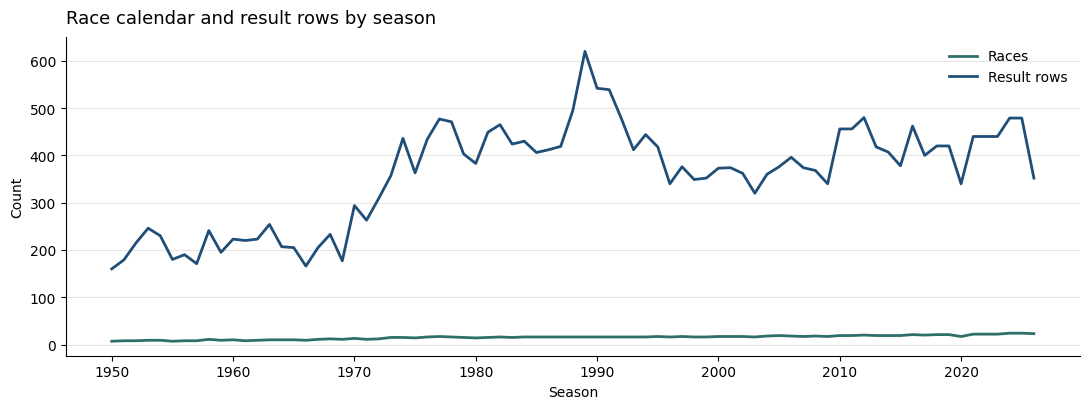

In [3]:
results_year = replace_sentinels(raw["results"])[["raceId"]].merge(
    races_raw[["raceId", "year"]], on="raceId", how="left"
)
volume = pd.DataFrame({
    "races": races_raw.groupby("year").size(),
    "result_rows": results_year.groupby("year").size(),
}).fillna(0)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(volume.index, volume["races"], color=TEAL, linewidth=2, label="Races")
ax.plot(volume.index, volume["result_rows"], color=NAVY, linewidth=2, label="Result rows")
styled(ax, "Race calendar and result rows by season", "Season", "Count")
ax.legend(frameon=False)
save(fig, "01_season_volume.png")

The calendar is not a fixed sample. The number of races and the size of the field both change by season, and the early championship includes the Indianapolis 500, which had a much larger grid than a modern Grand Prix. A single podium rate for 1950–2024 mixes those eras. The decade chart after cleaning separates them.

## 3. Sentinel values, before they are converted

Ergast writes a missing value as the two characters `\N`. Pandas does not treat that as missing, so a numeric column full of `\N` still looks populated. The first audit counts those markers on the raw strings.

One column does not fit the usual reading. In `constructor_results.status`, `\N` means the constructor was not disqualified. The only other value is `D`. Converting `\N` to “unknown” would make almost every constructor result look incomplete. That column is mapped to `disqualified`, which is true only for `D`.

,table,column,sentinel_n,rows,sentinel_share
0,constructor_results,status,13024,13041,0.998696
1,races,sprint_time,1145,1172,0.976962
2,races,sprint_date,1142,1172,0.974403
3,drivers,number,802,865,0.927168
4,races,fp3_time,1084,1172,0.924915
5,races,fp2_time,1075,1172,0.917235
6,races,fp3_date,1065,1172,0.908703
7,races,fp1_time,1057,1172,0.901877
8,races,quali_time,1057,1172,0.901877
9,races,fp2_date,1053,1172,0.898464


constructor_results.status raw values:


,rows
status,
\N,13024
D,17


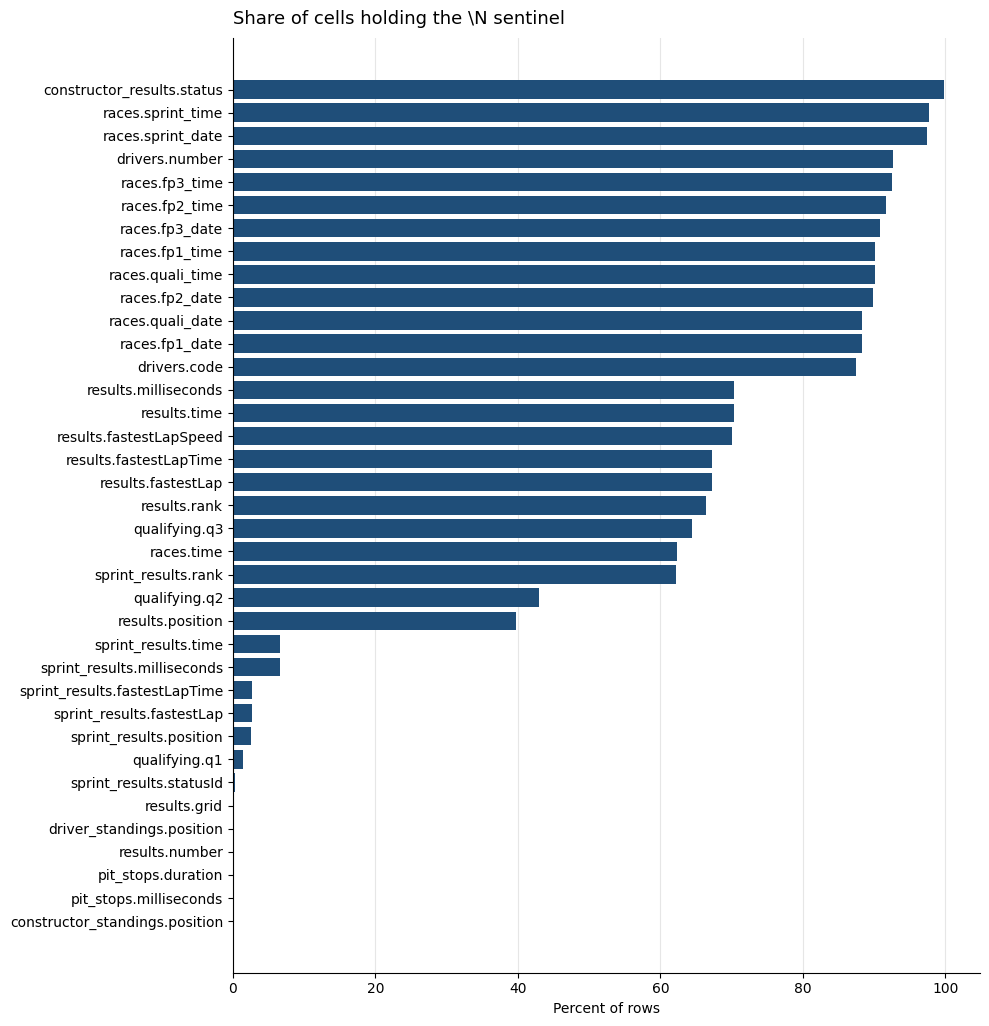

In [4]:
from src.f1_clean import summarize_sentinels

sentinels = summarize_sentinels(raw)
display(sentinels)

status_counts = raw["constructor_results"]["status"].value_counts()
print("constructor_results.status raw values:")
display(status_counts.to_frame("rows"))

plot_df = sentinels.sort_values("sentinel_share")
fig, ax = plt.subplots(figsize=(10, max(6, 0.28 * len(plot_df))))
ax.barh(
    plot_df["table"] + "." + plot_df["column"],
    plot_df["sentinel_share"] * 100,
    color=NAVY,
)
styled(
    ax,
    "Share of cells holding the \\N sentinel",
    "Percent of rows",
    "",
    grid="x",
)
save(fig, "02_sentinel_share.png")

The tall bars are structural, not scattered holes. Qualifying Q2 and Q3 are empty when a driver is eliminated in the previous session. Session dates and times on `races` are empty for most of history because the file only records them for recent seasons. `results.position` is empty when the driver was not classified; `positionOrder` is filled for every row and is the column the brief uses for the label. Driver numbers and three-letter codes are empty for older drivers because those identifiers did not exist yet. That last pattern is checked on its own below, by decade of debut.

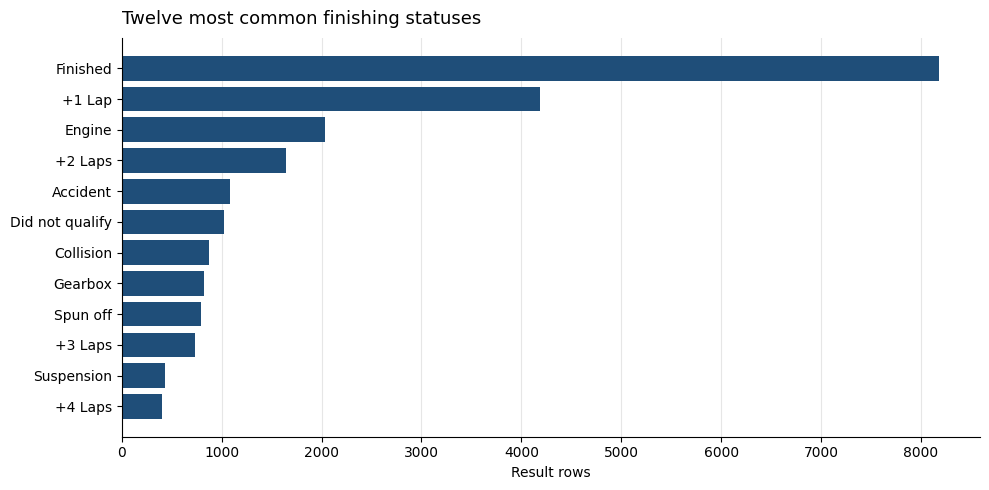

Distinct statuses used in results: 139


In [5]:
results_status = replace_sentinels(raw["results"]).merge(
    replace_sentinels(raw["status"]), on="statusId", how="left"
)
top_status = results_status["status"].value_counts().head(12).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_status.index, top_status.values, color=NAVY)
styled(ax, "Twelve most common finishing statuses", "Result rows", "", grid="x")
save(fig, "03_status_counts.png")
print(f"Distinct statuses used in results: {results_status['status'].nunique()}")

A large share of result rows are not `Finished`. For those rows the official position is empty and the status says why the car stopped. `positionOrder` still ranks them behind the classified finishers. That is a property of the label column. It is also a reminder that status, laps, and position are known only after the race, so they stay out of the feature set.

## 4. Keys before cleaning

A primary key must be unique and non-null. A foreign key may be null, and every non-null value must exist in the parent table. Grain checks ask a separate question: does one driver appear once per race?

In [6]:
from src.f1_clean import audit_keys

keys_before = audit_keys(raw)
failed_before = keys_before.loc[~keys_before["passed"]].copy()
print(f"{int(keys_before['passed'].sum())} of {len(keys_before)} checks passed before cleaning.")
display(failed_before)

39 of 42 checks passed before cleaning.


,table,check,columns,rows,null_key_rows,problem_rows,passed
9,lap_times,primary_key,"raceId, driverId, lap",884145,0,1979,False
14,results_driver_race,grain,"raceId, driverId",27590,0,91,False
41,sprint_results,foreign_key,statusId -> status.statusId,590,0,2,False


Three checks fail, and they fail for different reasons.

- The lap-time key `(raceId, driverId, lap)` is not unique. Some laps are stored twice. That is a broken key, so the cleaned lap-time table keeps one row and writes the discarded copy to an audit file. Lap times are measured during the race. Repairing the key does not make them legal features.
- `(raceId, driverId)` is not unique in `results`. Section 5 shows that these rows are real repeated entries, mostly shared drives, so they stay in `results`. The modeling table is a new table that keeps one of them.
- Two sprint rows have `\N` in `statusId`. That is a sentinel, not a status that is missing from `status`. After conversion they are null foreign keys, which is allowed. No real status id points at a missing parent.

## 5. Repeated driver-race rows

The brief asks for one row per `(raceId, driverId)`, and it says the early duplicates come from shared drives. The count by season is the check on that claim.

Repeated result rows: 176
Driver-race pairs involved: 85
Seasons involved: 1950–1978


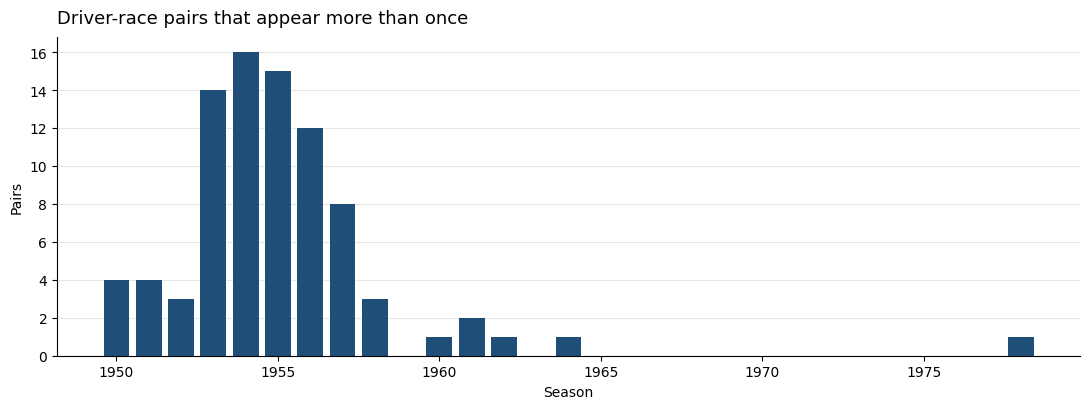

In [7]:
results_view = replace_sentinels(raw["results"]).copy()
for column in ["grid", "positionOrder", "laps", "points"]:
    results_view[column] = pd.to_numeric(results_view[column])

drivers_view = replace_sentinels(raw["drivers"]).copy()
drivers_view["driver"] = drivers_view["forename"] + " " + drivers_view["surname"]

repeated = results_view.loc[results_view.duplicated(["raceId", "driverId"], keep=False)].copy()
repeated = repeated.merge(races_raw[["raceId", "year", "name"]], on="raceId", how="left")
repeated = repeated.merge(drivers_view[["driverId", "driver"]], on="driverId", how="left")
pairs = repeated.drop_duplicates(["raceId", "driverId"])

print(f"Repeated result rows: {len(repeated)}")
print(f"Driver-race pairs involved: {len(pairs)}")
print(f"Seasons involved: {int(pairs['year'].min())}–{int(pairs['year'].max())}")

year_counts = pairs.groupby("year").size().reindex(range(1950, 1979), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(year_counts.index, year_counts.values, color=NAVY, width=0.8)
styled(ax, "Driver-race pairs that appear more than once", "Season", "Pairs")
save(fig, "04_duplicate_pairs_by_year.png")

The repeated keys are concentrated in the 1950s. The chart stops at 1978 because that is the last season with any repeated pair. Modern seasons already have one row per driver per race.

The 1951 French Grand Prix is a shared drive: the same car number is attached to two drivers, and each of those drivers also has a second row. Both rows are real. They are two stints, not a corrupted copy of one stint.

In [8]:
french_id = races_raw.loc[
    (races_raw["year"] == 1951) & (races_raw["name"] == "French Grand Prix"),
    "raceId",
].iloc[0]
french = repeated.loc[repeated["raceId"] == french_id].copy()
shared_numbers = french.groupby("number")["driverId"].nunique()
shared_numbers = shared_numbers[shared_numbers > 1].index
french_shared = french.loc[french["number"].isin(shared_numbers), [
    "driver", "number", "grid", "positionText", "positionOrder", "laps", "points",
]].sort_values(["number", "positionOrder", "driver"])
display(french_shared)

,driver,number,grid,positionText,positionOrder,laps,points
81,Juan Fangio,24,1.0,11,11,55,0.0
93,Luigi Fagioli,24,1.0,11,11,55,0.0
92,Juan Fangio,8,7.0,1,1,77,5.0
79,Luigi Fagioli,8,7.0,1,1,77,4.0


Take car 8. Two drivers are both recorded on that car, with the same grid, the same classified position, and the same lap count, while the points are split. Each of those drivers also has another row on a different car. Keeping both rows would train the model on two outcomes for one driver in one race. The modeling table has to choose one row per driver. The rule is in Section 8. Both of the rules considered there keep the classified result for each of these drivers, so the podium label is the same either way.

In [9]:
late = repeated.loc[repeated["year"] >= 1965, [
    "year", "name", "driver", "constructorId", "grid", "positionText", "positionOrder", "laps",
]].sort_values(["year", "driver", "positionOrder"])
print(f"Repeated rows after 1964: {len(late)}")
display(late)

status_view = replace_sentinels(raw["status"])
late_status = repeated.loc[repeated["year"] >= 1965, ["statusId"]].merge(status_view, on="statusId")
print("Statuses on those rows:")
display(late_status["status"].value_counts().to_frame("rows"))

Repeated rows after 1964: 2


,year,name,driver,constructorId,grid,positionText,positionOrder,laps
0,1978,Italian Grand Prix,Harald Ertl,54,0.0,F,26,0
1,1978,Italian Grand Prix,Harald Ertl,57,0.0,F,29,0


Statuses on those rows:


,rows
status,
Did not qualify,1
Did not prequalify,1


The only repeated pair after 1964 is the 1978 Italian Grand Prix. It is not a shared drive that completed laps. The same driver has two entries, both on grid 0 with zero laps, and the statuses are “Did not qualify” and “Did not prequalify”. The collapse still has to keep one row. Neither row is a podium, so the label does not depend on which zero-lap row is kept.

## 6. What “podium” means in this file

The brief defines the label as `positionOrder <= 3`. `positionOrder` is a dense rank of every car in the result, including cars that did not finish. `positionText` is the official classification, and it uses letters (`R`, `D`, `W`, `F`) when the driver was not classified. The check below asks whether those two columns tell the same podium story.

In [10]:
results_view["brief_podium"] = results_view["positionOrder"] <= 3
results_view["official_podium"] = results_view["positionText"].isin(["1", "2", "3"])
brief_only = results_view["brief_podium"] & ~results_view["official_podium"]
official_only = results_view["official_podium"] & ~results_view["brief_podium"]
print(f"Brief podium rows: {int(results_view['brief_podium'].sum())}")
print(f"Official podium rows: {int(results_view['official_podium'].sum())}")
print(f"In the brief label only: {int(brief_only.sum())}")
print(f"In the official label only: {int(official_only.sum())}")

conflict_ids = results_view.loc[brief_only, "raceId"].unique()
conflict_race = results_view.loc[results_view["raceId"].isin(conflict_ids)].copy()
conflict_race = conflict_race.merge(drivers_view[["driverId", "driver"]], on="driverId", how="left")
conflict_race = conflict_race.merge(races_raw[["raceId", "year", "name"]], on="raceId", how="left")
conflict_race = conflict_race.merge(status_view, on="statusId", how="left")
show_cols = ["year", "name", "driver", "grid", "positionText", "positionOrder", "points", "status"]
display(
    conflict_race.sort_values(["raceId", "positionOrder"])[show_cols]
    .head(8)
)

Brief podium rows: 3517
Official podium rows: 3516
In the brief label only: 1
In the official label only: 0


,year,name,driver,grid,positionText,positionOrder,points,status
0,1983,Brazilian Grand Prix,Nelson Piquet,4.0,1,1,9.0,Finished
1,1983,Brazilian Grand Prix,Niki Lauda,9.0,3,2,4.0,Finished
2,1983,Brazilian Grand Prix,Jacques Laffite,18.0,4,3,3.0,Finished
3,1983,Brazilian Grand Prix,Patrick Tambay,3.0,5,4,2.0,Finished
4,1983,Brazilian Grand Prix,Marc Surer,20.0,6,5,1.0,Finished
5,1983,Brazilian Grand Prix,Alain Prost,2.0,7,6,0.0,+1 Lap
6,1983,Brazilian Grand Prix,Derek Warwick,5.0,8,7,0.0,+1 Lap
7,1983,Brazilian Grand Prix,Chico Serra,23.0,9,8,0.0,+1 Lap


On this extract the two definitions disagree on one row, in the 1983 Brazilian Grand Prix. The official position text goes 1, then 3, then 4. There is no official 2nd place in the file. `positionOrder` has no gap, so the driver whose official text is 4 receives `positionOrder` 3. The points move with the official text: 9, then 4, then 3, skipping the step that the missing place would have scored. Those cars are classified as `Finished`. This is not a retirement that was ranked third.

The stored label follows the brief: `podium` is `positionOrder <= 3`. `official_podium` keeps the text-based version, and `podium_definition_conflict` marks the disagreement. One row is not a reason to replace the brief’s definition. It is a reason to be able to point at it.

## 7. Coverage the later feature work has to respect

Three coverage facts are properties of the extract. Cleaning does not impute them.

Scheduled races with no result rows: 7


,year,round,name,date
1165,2026,17,Singapore Grand Prix,2026-10-11
1166,2026,18,United States Grand Prix,2026-10-25
1167,2026,19,Mexico City Grand Prix,2026-11-01
1168,2026,20,Brazilian Grand Prix,2026-11-08
1169,2026,21,Las Vegas Grand Prix,2026-11-22
1170,2026,22,Qatar Grand Prix,2026-11-29
1171,2026,23,Abu Dhabi Grand Prix,2026-12-06


First season present in qualifying: 1994


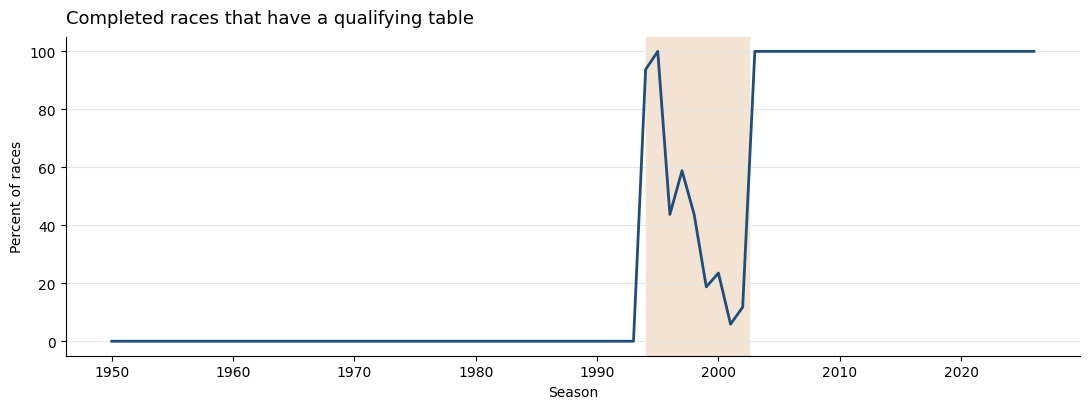

In [11]:
result_race_ids = set(results_view["raceId"])
unraced = races_raw.loc[~races_raw["raceId"].isin(result_race_ids), ["year", "round", "name", "date"]]
unraced = unraced.sort_values(["year", "round"])
print(f"Scheduled races with no result rows: {len(unraced)}")
display(unraced)

quali_ids = set(replace_sentinels(raw["qualifying"])["raceId"])
completed = races_raw.loc[races_raw["raceId"].isin(result_race_ids)].copy()
completed["has_qualifying"] = completed["raceId"].isin(quali_ids)
coverage = completed.groupby("year")["has_qualifying"].mean()
print(f"First season present in qualifying: {int(coverage[coverage > 0].index.min())}")

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(coverage.index, coverage.values * 100, color=NAVY, linewidth=2)
ax.axvspan(1994, 2002.5, color="#f3e3d3", zorder=0)
styled(ax, "Completed races that have a qualifying table", "Season", "Percent of races")
ax.set_ylim(-5, 105)
save(fig, "05_qualifying_coverage.png")

Unstarted races have a row in `races` and no rows in `results`. They never enter the driver-race table, because there is no entry to label. On this download those rows are the remaining 2026 rounds.

Qualifying coverage has three regimes, and the shaded band is the middle one.

- Before 1994 the qualifying table has no races. A missing qualifying row in this era means the source has not started yet.
- From 1994 through 2002 the table exists and many races are absent. A missing row in this window is a hole in the extract, not a driver who failed to set a time.
- From 2003 onward, every completed race in this file has qualifying rows. The unstarted 2026 races are excluded from the share, so a race that has not been held is not counted as missing qualifying.

The null grids are a separate hole. Grid 0 is a real recorded value: the driver had no grid slot. A null grid means the file omitted the number. The races below have a null grid for the whole field. Those nulls are left as null. They are not filled from qualifying, because qualifying position and the starting grid come apart when a penalty is applied, and that distinction belongs to a later question.

Rows with a null grid, by race:


,year,name,date,null_grid_rows
0,2025,Qatar Grand Prix,2025-11-30,20
1,2026,Azerbaijan Grand Prix,2026-09-26,22


Rows with grid 0: 1638


,drivers,code_missing,number_missing
decade,,,
1950,332,99.7,100.0
1960,145,100.0,100.0
1970,135,100.0,100.0
1980,79,100.0,100.0
1990,66,81.8,100.0
2000,49,26.5,77.6
2010,41,0.0,17.1
2020,18,0.0,0.0


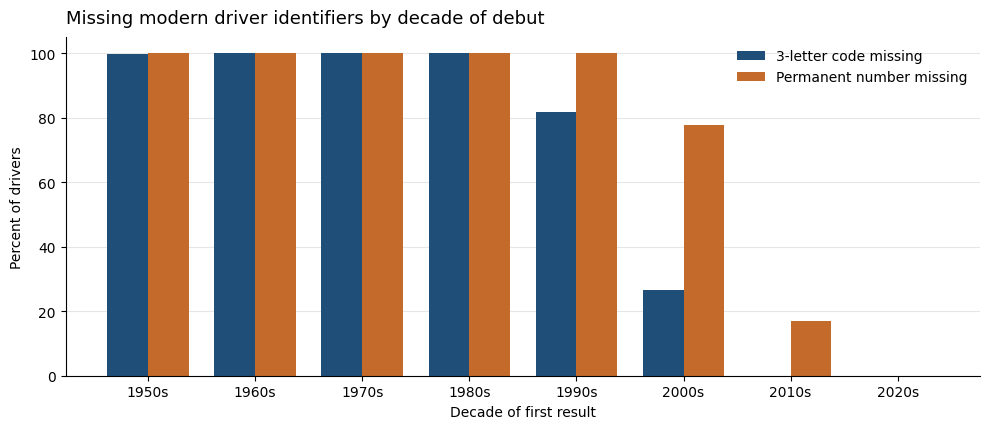

In [12]:
grid_null = results_view.loc[results_view["grid"].isna(), ["raceId"]].merge(
    races_raw[["raceId", "year", "name", "date"]], on="raceId"
)
print("Rows with a null grid, by race:")
display(grid_null.groupby(["year", "name", "date"]).size().rename("null_grid_rows").reset_index())
print(f"Rows with grid 0: {int((results_view['grid'] == 0).sum())}")

debut = results_view.merge(races_raw[["raceId", "year"]], on="raceId").groupby("driverId")["year"].min()
driver_codes = drivers_view.merge(debut.rename("debut"), left_on="driverId", right_index=True, how="inner")
driver_codes["decade"] = (driver_codes["debut"] // 10 * 10).astype(int)
driver_codes["code_missing"] = driver_codes["code"].isna()
driver_codes["number_missing"] = driver_codes["number"].isna()
code_by_decade = driver_codes.groupby("decade").agg(
    drivers=("driverId", "size"),
    code_missing=("code_missing", "mean"),
    number_missing=("number_missing", "mean"),
)
code_by_decade[["code_missing", "number_missing"]] = code_by_decade[["code_missing", "number_missing"]] * 100
display(code_by_decade.round(1))

fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(code_by_decade))
width = 0.38
ax.bar(x - width / 2, code_by_decade["code_missing"], width=width, color=NAVY, label="3-letter code missing")
ax.bar(x + width / 2, code_by_decade["number_missing"], width=width, color=CLAY, label="Permanent number missing")
styled(ax, "Missing modern driver identifiers by decade of debut", "Decade of first result", "Percent of drivers")
ax.set_xticks(x, [str(int(year)) + "s" for year in code_by_decade.index], rotation=0)
ax.set_ylim(0, 105)
ax.legend(frameon=False)
save(fig, "06_driver_identifier_missingness.png")

Permanent numbers and three-letter codes are modern identifiers. Their absence on a driver who debuted in the 1950s is the era of the record, not a failed join. Those drivers stay in the table. The fields stay null.

The same reading applies to the standings tables. A handful of rows have no numeric position and `positionText` equal to `-`, with zero points, at the opening races of recent seasons. That marker means unranked. It is left as null. Standings of the current race are post-race information anyway, so this notebook does not turn them into features.

In [13]:
standings = replace_sentinels(raw["driver_standings"]).copy()
standings["points"] = pd.to_numeric(standings["points"])
unranked = standings.loc[standings["position"].isna()].merge(
    races_raw[["raceId", "year", "name"]], on="raceId"
)
print(f"Driver-standings rows with no position: {len(unranked)}")
display(
    unranked.groupby(["year", "name", "positionText"])
    .size()
    .rename("rows")
    .reset_index()
)

Driver-standings rows with no position: 13


,year,name,positionText,rows
0,2025,Australian Grand Prix,-,6
1,2025,Chinese Grand Prix,-,1
2,2026,Australian Grand Prix,-,6


## 8. The cleaning rules

Applied to copies, in this order:

1. Replace `\N` with missing values. Row counts of the source tables stay the same.
2. Cast identifiers and counts to integers, points and coordinates to floats, and calendar dates to dates. A value that is present but cannot be cast is recorded as a coercion failure. The standard for this extract is zero failures.
3. Parse duration strings (`ss.sss`, `m:ss.sss`, `h:mm:ss.sss`) into seconds. Qualifying segments, lap times, pit durations, and fastest laps use this parser.
4. Split `results.time` into two measurements. A string with no leading `+` is the winner’s elapsed time. A string with a leading `+` is the gap to the winner. `milliseconds` is elapsed time for that car when the source has it, including cars whose `time` string is only a gap. Those three numbers are stored in separate columns.
5. Where `races.date` and `races.time` are both present, combine them into `race_start`.
6. Map `constructor_results.status` to `disqualified`.
7. Mark `results.classified` when the official position is present.
8. Repair lap times so `(raceId, driverId, lap)` is unique. Exact copies are dropped. When the two copies disagree, the faster time is kept and both copies are written to the audit file.
9. Build `driver_race` with one row per `(raceId, driverId)`. The source `results` table keeps every stint.

The collapse rule is `best_classification`: lowest `positionOrder`, then most laps, then the smallest `resultId`. The label is the driver’s finishing result, so the classified result wins over a longer retirement. `most_laps` is computed on the same pairs as a check. It is not the stored rule.

In [14]:
result = clean_tables(raw)

print("Coercion failures (empty means every present value cast successfully):")
display(result.coercion_failures)

print("Parsed strings against the millisecond columns already in the file:")
display(result.time_checks)

print(f"Disqualified constructor results: {int(result.cleaned['constructor_results']['disqualified'].sum())}")

print("Missing-value method for every column that had a blank marker:")
display(result.missing_policy)
left_blank = result.missing_policy.loc[result.missing_policy["method"] == "leave missing", "values_filled"]
assert left_blank.eq(0).all()

Coercion failures (empty means every present value cast successfully):


,table,column,failed_n


Parsed strings against the millisecond columns already in the file:


,check,rows,max_abs_seconds
0,results winner time vs milliseconds,1167,0.000000e+00
1,lap time string vs milliseconds,882166,1.000000e-03
2,pit duration string vs milliseconds,22774,2.273737e-13


Disqualified constructor results: 17
Missing-value method for every column that had a blank marker:


,table,column,blank_markers,method,values_filled,still_missing,reason
0,constructor_results,disqualified,13024,filled with False,13024,0,Each \N in status was written here as False. E...
1,constructor_results,status,13024,code as not disqualified,0,13024,\N means the constructor was not disqualified....
2,constructor_standings,position,1,leave missing,0,1,One standings row is unranked. A median rank w...
3,driver_standings,position,13,leave missing,0,13,The text is already '-': unranked. The mode wo...
4,drivers,code,757,leave missing,0,757,Three-letter codes did not exist for most of t...
5,drivers,number,802,leave missing,0,802,Permanent numbers did not exist for most of th...
6,pit_stops,duration,3,leave missing,0,3,Three stops have no duration. A median would h...
7,pit_stops,milliseconds,3,leave missing,0,3,The same three stops have no duration in milli...
8,qualifying,q1,164,leave missing,0,164,The driver set no Q1 time. A median lap time w...
9,qualifying,q2,4867,leave missing,0,4867,The driver did not reach Q2. A median would sa...


Zero coercion failures means the type conversion did not silently turn bad strings into missing numbers. The time check is the other half of that claim. The winner’s clock, the lap-time string, and the pit-stop string match the millisecond columns to the nearest millisecond. The parsed seconds are the same measurement as the integer the file already stored.

`disqualified` is true for 17 constructor results, which is the number of raw `D` values. Every former `\N` in that column is false, because that marker meant “not disqualified”.

The table above is the missing-value decision for every column that contained `\N`. Mean, median, and mode are not used. `leave missing` keeps the blank, and `values_filled` is 0 on those rows, so no average was written in. The one coded column is `constructor_results.status`: the blank marker is stored as `disqualified = False`.

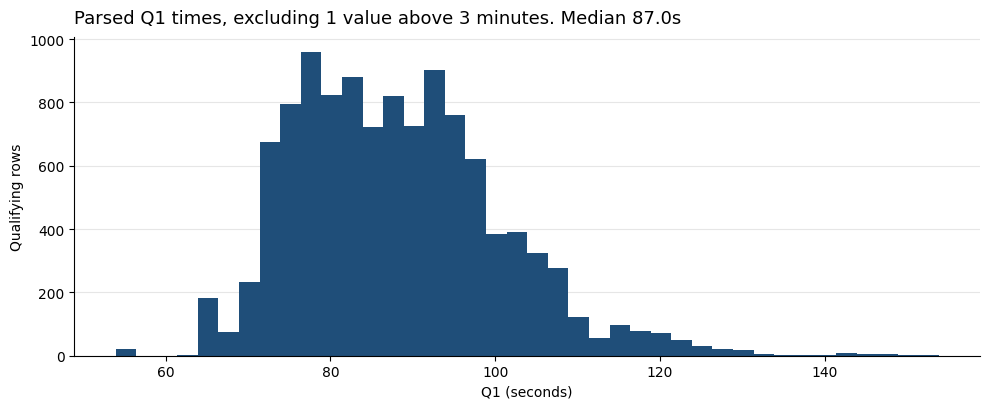

Qualifying times longer than 3 minutes, left as parsed from the source string:


,year,name,forename,surname,q1,q1_seconds
0,1995,Japanese Grand Prix,Mark,Blundell,16:42.640,1002.64


,time,winner_time_seconds,gap_seconds,elapsed_seconds
0,1:34:50.616,5690.616,NaN,5690.616
1,+5.478,NaN,5.478,5696.094
2,+8.163,NaN,8.163,5698.779
3,+17.181,NaN,17.181,5707.797
4,+18.014,NaN,18.014,5708.63
22,1:31:18.555,5478.555,NaN,5478.555


In [15]:
q1 = result.cleaned["qualifying"][["raceId", "driverId", "q1", "q1_seconds"]].dropna(subset=["q1_seconds"])
ordinary = q1.loc[q1["q1_seconds"] <= 180, "q1_seconds"]
odd = q1.loc[q1["q1_seconds"] > 180].merge(
    result.cleaned["races"][["raceId", "year", "name"]], on="raceId"
).merge(
    result.cleaned["drivers"][["driverId", "forename", "surname"]], on="driverId"
)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(ordinary, bins=40, color=NAVY)
styled(
    ax,
    f"Parsed Q1 times, excluding {len(odd)} value above 3 minutes. Median {ordinary.median():.1f}s",
    "Q1 (seconds)",
    "Qualifying rows",
)
save(fig, "07_q1_seconds.png")
print("Qualifying times longer than 3 minutes, left as parsed from the source string:")
display(odd[["year", "name", "forename", "surname", "q1", "q1_seconds"]])

sample_times = result.cleaned["results"].loc[
    result.cleaned["results"]["winner_time_seconds"].notna()
    | result.cleaned["results"]["gap_seconds"].notna(),
    ["time", "winner_time_seconds", "gap_seconds", "elapsed_seconds"],
].head(6)
display(sample_times)

A Q1 string such as `1:26.572` is now about 86.6 seconds. The mass of the histogram sits on real lap times: the median is 87 seconds. One source string does not. Mark Blundell’s 1995 Japanese Grand Prix Q1 is stored as `16:42.640`, which is 1002.6 seconds. The parser is right about what the characters say, and the value is left unchanged, because replacing it with a guessed lap time would be inventing data. It is excluded from the histogram only so the other times stay readable. The sample of `results.time` shows the split: a clock with no `+` fills `winner_time_seconds`, and a clock with `+` fills `gap_seconds`. `elapsed_seconds` comes from `milliseconds` and is populated for both kinds of row when the source has it.

In [16]:
keys_after = result.keys_after
failed_after = keys_after.loc[~keys_after["passed"]].copy()
print(f"{int(keys_after['passed'].sum())} of {len(keys_after)} checks passed after cleaning.")
display(failed_after)
print("Lap-time key repair:")
display(result.lap_conflict_summary)

42 of 43 checks passed after cleaning.


,table,check,columns,rows,null_key_rows,problem_rows,passed
14,results_driver_race,grain,"raceId, driverId",27590,0,91,False


Lap-time key repair:


,kind,groups
0,unique_already,880187
1,exact_duplicate,1710
2,one_millisecond,243
3,larger_conflict,26


The only check that still fails is the `(raceId, driverId)` grain of the source `results` table. That failure is deliberate. Shared-drive stints remain in `results` so the choice of row can be audited. The new `driver_race` table is the unique grain, and its own key check passes.

The lap-time repair is summarized above. Most repeated laps were exact copies or a one-millisecond disagreement. A smaller set differs by more than one millisecond. The cleaned table keeps the faster time. Every conflicting copy is in `data/audit/lap_time_conflicts.csv`.

## 9. Which row is kept

`best_classification` and `most_laps` were both run on every repeated pair. The question is whether the stored label, and the stored grid and constructor, depend on that choice.

In [17]:
comparison = result.rule_comparison
print(f"Repeated pairs compared: {len(comparison)}")
print(f"Same resultId: {int(comparison['same_row'].sum())}")
print(f"Same positionOrder: {int(comparison['same_position'].sum())}")
print(f"Same podium label: {int(comparison['same_podium'].sum())}")
print(f"Disagreements: {int((~comparison['same_row']).sum())}")

toy = pd.DataFrame([
    {"raceId": 1, "driverId": 7, "resultId": 10, "positionOrder": 8, "laps": 70},
    {"raceId": 1, "driverId": 7, "resultId": 11, "positionOrder": 2, "laps": 12},
])
toy_compare = pd.DataFrame({
    "rule": ["best_classification", "most_laps"],
    "kept_resultId": [
        int(collapse_entries(toy, "best_classification").iloc[0]["resultId"]),
        int(collapse_entries(toy, "most_laps").iloc[0]["resultId"]),
    ],
})
display(toy)
display(toy_compare)

Repeated pairs compared: 85
Same resultId: 85
Same positionOrder: 85
Same podium label: 85
Disagreements: 0


,raceId,driverId,resultId,positionOrder,laps
0,1,7,10,8,70
1,1,7,11,2,12


,rule,kept_resultId
0,best_classification,11
1,most_laps,10


On this extract the two rules keep the same `resultId` for all 85 repeated pairs, so they also keep the same podium label, the same grid, and the same constructor. The agreement is a property of these rows. It is not a property of the rules.

The toy pair is a short podium stint and a long retirement. `best_classification` keeps the podium. `most_laps` keeps the retirement. The label this project predicts is the podium, so the stored rule is `best_classification` even though the two rules happen to agree on the real pairs. If a later refresh of the extract contains a pair like the toy, the label will follow the classified result.

## 10. The driver-race table, and what cleaning changed

`driver_race` has one row per driver per race. `shared_entry` marks the  pairs that were collapsed. `n_constructors` is greater than 1 when the stints used different cars. For those rows, `constructorId` is the constructor on the kept stint, which is the better classified car. It is not safe to read it as “the car they qualified” without looking at the flag.

Result rows: 27590
Driver-race rows: 27499
Rows removed by the collapse: 91
Unique (raceId, driverId): True
Shared entries: 85
Shared entries with more than one constructor: 16
Podium definition conflicts: 1
Rows inside the brief's 1950–2024 window: 26668 of 27499


,before,after,median_starters
decade,,,
1950,13.60,14.1,21.0
1960,14.25,14.28,20.0
1970,11.35,11.35,26.0
1980,10.39,10.39,28.0
1990,11.44,11.44,26.0
2000,14.33,14.33,20.0
2010,13.82,13.82,22.0
2020,14.85,14.85,20.0


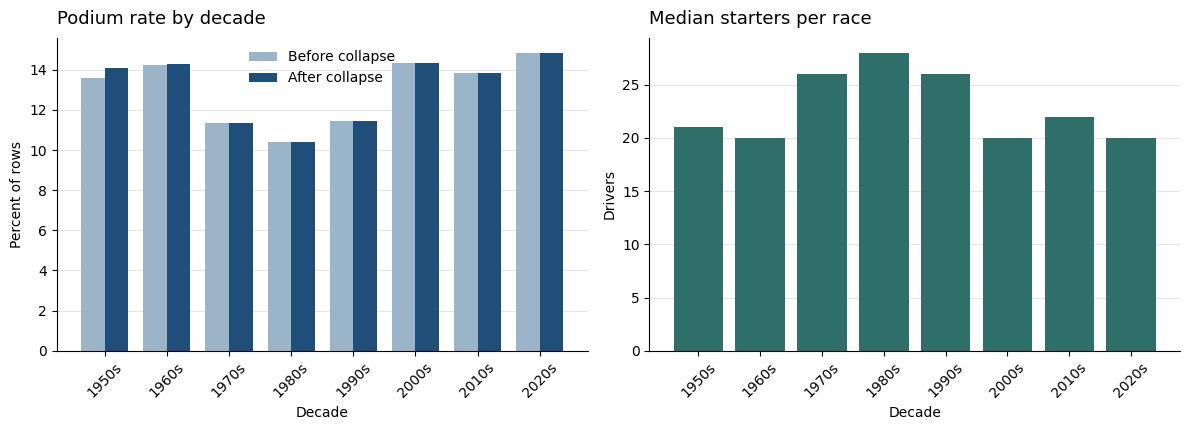

In [18]:
driver_race = result.driver_race
print(f"Result rows: {len(result.cleaned['results'])}")
print(f"Driver-race rows: {len(driver_race)}")
print(f"Rows removed by the collapse: {len(result.cleaned['results']) - len(driver_race)}")
print(f"Unique (raceId, driverId): {not driver_race.duplicated(['raceId', 'driverId']).any()}")
print(f"Shared entries: {int(driver_race['shared_entry'].sum())}")
print(f"Shared entries with more than one constructor: {int((driver_race['n_constructors'] > 1).sum())}")
print(f"Podium definition conflicts: {int(driver_race['podium_definition_conflict'].sum())}")
print(
    f"Rows inside the brief's 1950–{ASSIGNMENT_LAST_YEAR} window: "
    f"{int(driver_race['in_assignment_window'].sum())} of {len(driver_race)}"
)

before = results_view[["raceId", "positionOrder"]].merge(
    races_raw[["raceId", "year"]], on="raceId", how="left"
)
before["podium"] = before["positionOrder"] <= 3
before["decade"] = (before["year"] // 10 * 10).astype(int)
after = driver_race[["raceId", "year", "podium"]].copy()
after["decade"] = (after["year"] // 10 * 10).astype(int)

rate = pd.DataFrame({
    "before": before.groupby("decade")["podium"].mean() * 100,
    "after": after.groupby("decade")["podium"].mean() * 100,
})
field = (
    after.groupby(["decade", "raceId"]).size()
    .groupby("decade").median()
    .rename("median_starters")
)
display(rate.round(2).join(field))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
x = np.arange(len(rate))
width = 0.38
axes[0].bar(x - width / 2, rate["before"], width=width, color="#9bb4c8", label="Before collapse")
axes[0].bar(x + width / 2, rate["after"], width=width, color=NAVY, label="After collapse")
styled(axes[0], "Podium rate by decade", "Decade", "Percent of rows")
axes[0].set_xticks(x, [str(int(year)) + "s" for year in rate.index], rotation=45)
axes[0].legend(frameon=False)

axes[1].bar(x, field.values, color=TEAL)
styled(axes[1], "Median starters per race", "Decade", "Drivers")
axes[1].set_xticks(x, [str(int(year)) + "s" for year in field.index], rotation=45)
save(fig, "08_podium_rate_before_after.png")

The collapse removes 91 result rows, all of them from the repeated pairs. In the 1950s the podium rate moves from 13.6% to 14.1%, because a driver who had both a classified stint and a retirement stint is now only the classified row. From the 1970s onward the rates match at the precision in the table. Modern seasons were already one row per driver.

The rate that remains still depends on the era, and it tracks field size rather than “early versus modern”. The 1980s have the largest median field, 28 starters, and the lowest podium rate, 10.4%. The 2020s have a median field of 20 and the highest rate, 14.8%. Three podium places are a larger share of a shorter field.

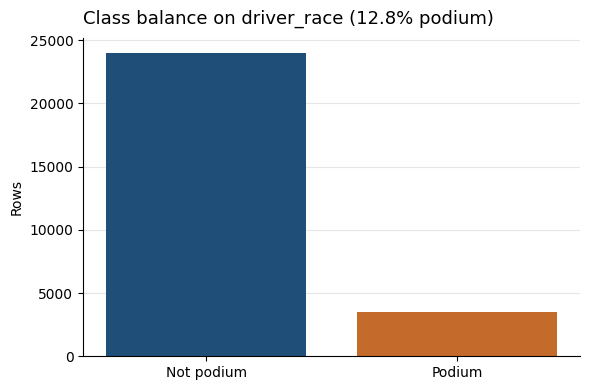

Races by how many drivers carry the podium label:


,races
podium,
3,1147
4,16
5,2


In [19]:
balance = driver_race["podium"].value_counts().rename({False: "Not podium", True: "Podium"})
balance_share = driver_race["podium"].mean()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(balance.index, balance.values, color=[NAVY, CLAY])
styled(ax, f"Class balance on driver_race ({balance_share * 100:.1f}% podium)", "", "Rows")
save(fig, "09_class_balance.png")

multi_podium = driver_race.groupby("raceId")["podium"].sum()
print("Races by how many drivers carry the podium label:")
display(multi_podium.value_counts().sort_index().rename("races").to_frame())

Podiums are 12.8% of the cleaned driver-race rows. That share is higher in shorter fields and lower in longer ones, so the overall percentage is not a constant the model can lean on. A few races have more than three drivers with the podium label. That is what a shared classified result looks like after the collapse: two drivers can both be credited with the same finishing position, and both rows are kept because they are different drivers.

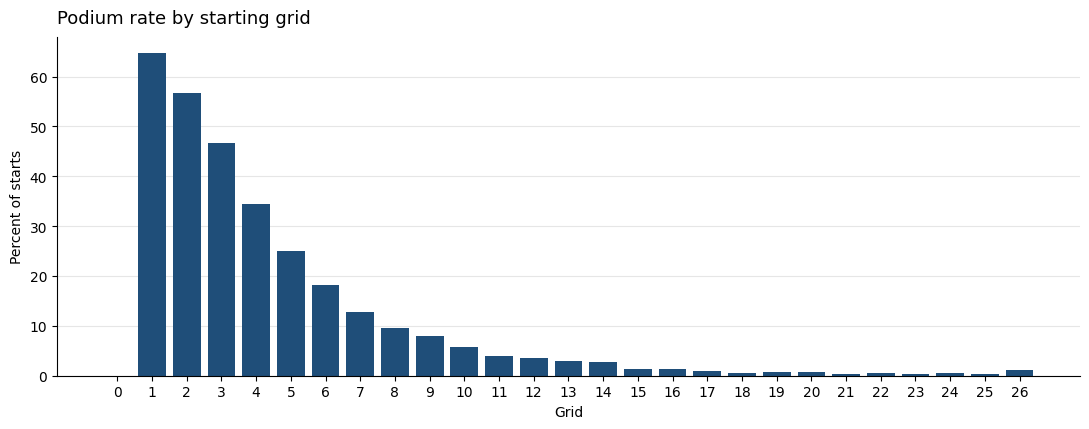

Grid 0 podium rate: 0.0% on 1635 starts
Starts on grids with fewer than 50 starts, omitted from the chart: 163
Starts with a null grid, also omitted: 42


In [20]:
grid = driver_race.dropna(subset=["grid"]).copy()
grid["grid"] = grid["grid"].astype(int)
grid_rates = grid.groupby("grid")["podium"].agg(rate="mean", starts="size")
plotted = grid_rates.loc[grid_rates["starts"] >= 50].copy()
omitted = int(grid_rates.loc[grid_rates["starts"] < 50, "starts"].sum())

fig, ax = plt.subplots(figsize=(11, 4.4))
colors = [CLAY if grid_pos == 0 else NAVY for grid_pos in plotted.index]
ax.bar(plotted.index.astype(str), plotted["rate"] * 100, color=colors)
styled(ax, "Podium rate by starting grid", "Grid", "Percent of starts")
save(fig, "10_podium_rate_by_grid.png")
grid_zero = driver_race.loc[driver_race["grid"] == 0, "podium"]
print(f"Grid 0 podium rate: {grid_zero.mean():.1%} on {len(grid_zero)} starts")
print(f"Starts on grids with fewer than 50 starts, omitted from the chart: {omitted}")
print(f"Starts with a null grid, also omitted: {int(driver_race['grid'].isna().sum())}")

Grid 0 is drawn in clay, and on this extract its bar has no height: 1,635 starts with no grid slot produced no podiums. It is not the back of the grid. It is a recorded “no grid slot”, and those entries did not finish on the podium. From grid 1, the rate falls as the starting position gets worse. Grids with fewer than 50 starts, mostly the long Indianapolis fields of the 1950s, are omitted because a rate from a handful of starts is not a stable pattern. Null grids are omitted too; they were listed with the two races whose whole field is missing a grid. This chart is the overall association only. It is not the circuit question, which has to separate qualifying position from the starting grid and to compare the seasons before and after 2014.

## 11. Handoff

Every column on `driver_race` has a role.

- `identifier` and `pre_race_context` are known when the race is scheduled, or they are on the entry that was kept. Grid, car number, and constructor are in this group, with the shared-entry caveat above.
- `post_race_label` is known only after the race. These columns exist so the label can be audited. They are not features.
- `audit` records the collapse and the two label definitions.

Current-race lap times, pit stops, fastest laps, race time, points, status, finishing position, and the standings published after the race are post-race information as well. They are cleaned in the source tables so the keys are trustworthy. They are not on the feature side of this handoff. Qualifying is pre-race where a qualifying row exists, and it is intentionally not joined yet.

In [21]:
from src.f1_clean import DRIVER_RACE_DICTIONARY, save_outputs

dictionary = pd.DataFrame(DRIVER_RACE_DICTIONARY, columns=["column", "role", "meaning"])
display(dictionary)

kept_example = result.duplicate_rows.loc[result.duplicate_rows["raceId"] == int(french_id)].copy()
name_map = (
    drivers_view.assign(driverId=pd.to_numeric(drivers_view["driverId"]))
    .set_index("driverId")["driver"]
)
kept_example["driver"] = kept_example["driverId"].map(name_map)
shared_number_ids = pd.to_numeric(pd.Index(shared_numbers))
display(
    kept_example.loc[kept_example["number"].isin(shared_number_ids), [
        "driver", "number", "grid", "positionText", "positionOrder", "laps", "kept",
    ]].sort_values(["number", "positionOrder", "driver"])
)

assert result.coercion_failures.empty
time_gap = result.time_checks.loc[~(result.time_checks["max_abs_seconds"] < 0.01)]
if time_gap.empty:
    print("Parsed times match the millisecond columns within 0.01 seconds.")
else:
    print("These source columns disagree with the millisecond values by 0.01 seconds or more. Both numbers are kept:")
    display(time_gap)
assert not driver_race.duplicated(["raceId", "driverId"]).any()
assert not result.cleaned["lap_times"].duplicated(["raceId", "driverId", "lap"]).any()
assert HASHES_AT_START == raw_hashes(PATHS["raw"])

save_outputs(result, PATHS)
print("Wrote cleaned tables, driver_race, and audit files.")
print(f"Raw files unchanged: {HASHES_AT_START == raw_hashes(PATHS['raw'])}")

,column,role,meaning
0,raceId,identifier,Race key. Already known when the race is sched...
1,driverId,identifier,Driver key.
2,resultId,identifier,resultId of the row kept by the collapse rule.
3,year,pre_race_context,Season. Known before the race.
4,round,pre_race_context,Round number. Known before the race.
5,race_date,pre_race_context,Scheduled race date.
6,circuitId,pre_race_context,Circuit. Known before the race.
7,race_name,pre_race_context,Grand Prix name.
8,constructorId,pre_race_context,Constructor on the kept row. When n_constructo...
9,car_number,pre_race_context,Car number on the kept row.


,driver,number,grid,positionText,positionOrder,laps,kept
20185,Juan Fangio,8,7,1,1,77,True
19917,Luigi Fagioli,8,7,1,1,77,True
19927,Juan Fangio,24,1,11,11,55,False
20187,Luigi Fagioli,24,1,11,11,55,False


Parsed times match the millisecond columns within 0.01 seconds.


Wrote cleaned tables, driver_race, and audit files.
Raw files unchanged: True


The `kept` flag on the 1951 French Grand Prix rows is the rule applied to the shared cars from Section 5. For each driver, the classified stint is kept and the other stint stays in `results` and in the duplicate audit, with `kept` false.

Re-run this notebook from the project folder with Run All. It reads `data/raw`, rewrites `data/cleaned`, `data/processed`, `data/audit`, and `figures`, and leaves the raw CSVs byte-for-byte as they were.

## 12. Features that exist before the race

The modeling table keeps the cleaning grain: one row per `(raceId, driverId)`. The years in the model are 2003–2024. From 2003 onward every completed race in this file has qualifying, so the cutoff is actually in the data. Earlier seasons stay in the cleaned tables and are marked `excluded` on this frame.

Each feature is built so that the current race cannot leak in.

- Grid and front row are the starting slot after penalties. A recorded grid of 0 means no grid slot. It is not stored as 0, because a linear model would read 0 as better than pole. Those rows get `no_grid_slot = 1`, `front_row = 0`, and a blank grid. A grid that was already blank stays blank, and `no_grid_slot` stays 0.
- Qualifying position is this race's qualifying result. `reached_q3` is blank for a whole race that did not run Q3, so those seasons are not coded as eliminations.
- Form uses the previous five starts. The points and the podium of the row being predicted are not in that window.
- Entering standings are the championship table after the previous round. The standings row published for this race is not used. Round 1 is blank.
- Home race matches the driver's nationality to the circuit country. A dual national matches either country. East German nationality is matched to German circuits because the file has no separate country.

Same-weekend sprint points are left out. In the current format they are known before the race, but they live in a results table for the same event. Leaving them out is the reading that cannot be accused of using the race itself.

,column,group,meaning
0,grid,grid,Starting grid after penalties. Known before th...
1,no_grid_slot,grid,1 when the source grid is 0. Those starts are ...
2,front_row,grid,"1 when the recorded grid is 1 or 2, otherwise ..."
3,quali_position,qualifying,Official qualifying position for this race. Kn...
4,reached_q3,qualifying,1 when the driver set a Q3 time. Missing for a...
5,quali_position_missing,qualifying,"1 when quali_position is missing, so an impute..."
6,driver_podium_rate_last5,form,Share of this driver's previous 5 starts that ...
7,driver_points_last5,form,Points from this driver's previous 5 starts. T...
8,constructor_podium_rate_last5,form,Mean podium share of this constructor's cars o...
9,career_starts,form,Number of race starts this driver had before t...


Rows in the modeling window: 8970
split
train         6411
test          1359
validation    1200
grid


,grid,starts,podium_rate
0,1,300,0.793333
1,2,299,0.622074
2,3,300,0.500000
3,4,300,0.313333
4,5,300,0.216667
5,6,300,0.160000
6,7,300,0.103333
7,8,300,0.053333
8,9,300,0.043333
9,10,299,0.046823


qualifying


,quali_position,starts,podium_rate
0,1,300,0.780000
1,2,300,0.623333
2,3,300,0.490000
3,4,300,0.316667
4,5,300,0.253333
5,6,300,0.166667
6,7,300,0.096667
7,8,300,0.046667
8,9,300,0.043333
9,10,300,0.040000


standings


,standing_bin,starts,podium_rate
0,1,284,0.665493
1,2-3,567,0.492063
2,4-10,1952,0.171107
3,11+,3134,0.014040


form


,form_bin,starts,podium_rate
0,0,4344,0.030157
1,0-20%,763,0.197903
2,20-40%,474,0.394515
3,40%+,758,0.565963


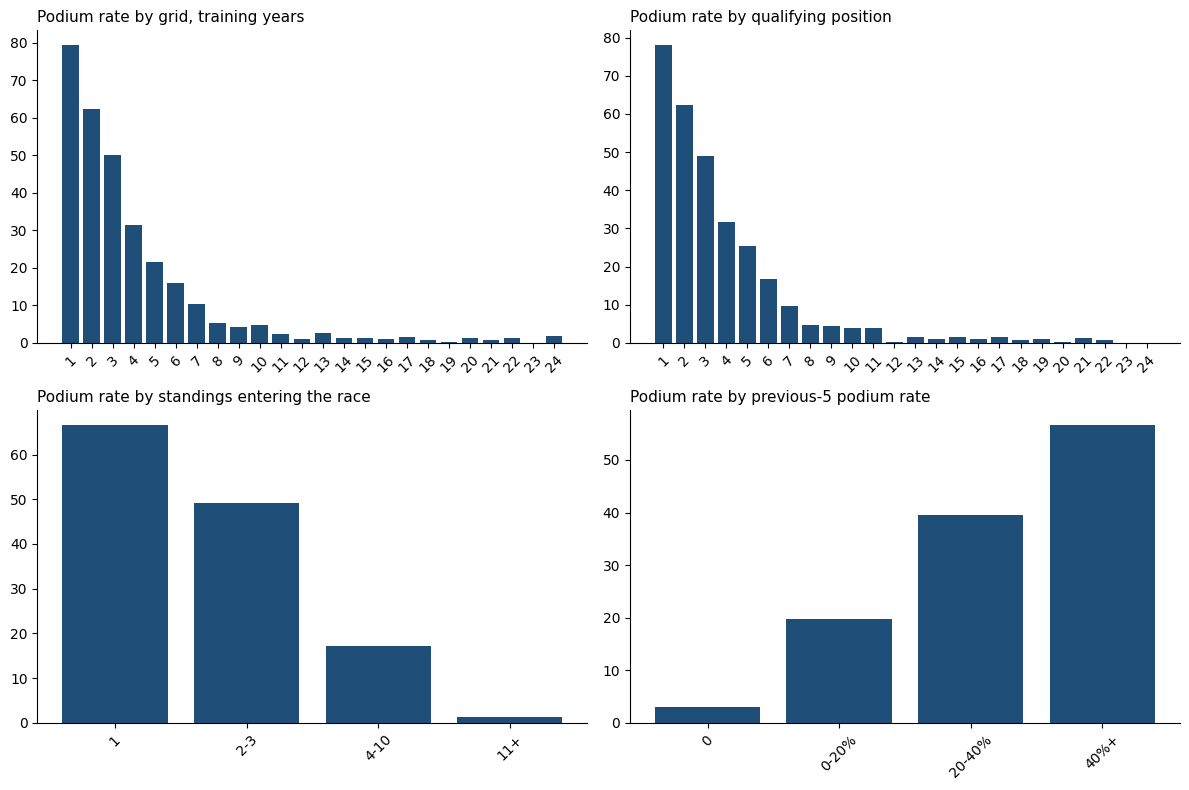

Wrote model_frame.csv


In [22]:
from src.f1_features import (
    FEATURE_COLUMNS,
    LEAKAGE_COLUMNS,
    build_model_frame,
    feature_dictionary_frame,
    feature_evidence,
    modeling_sample,
)
from src.f1_questions import plot_feature_evidence

model = build_model_frame(result.driver_race, result.cleaned)
sample = modeling_sample(model)
display(feature_dictionary_frame())
print("Rows in the modeling window:", len(sample))
print(sample["split"].value_counts().to_string())
assert not any(column in model.columns for column in LEAKAGE_COLUMNS)
assert not sample.duplicated(["raceId", "driverId"]).any()

evidence = feature_evidence(model)
for name, table in evidence.items():
    print(name)
    display(table)
save(plot_feature_evidence(evidence), "11_feature_evidence.png")
model.to_csv(PATHS["processed"] / "model_frame.csv", index=False)
feature_dictionary_frame().to_csv(PATHS["processed"] / "model_feature_dictionary.csv", index=False)
print("Wrote model_frame.csv")

The training-year plots are the reason these groups are in the model. The podium rate falls as the grid number gets worse, and it falls the same way as qualifying position gets worse. Drivers who arrive in the lead of the championship, and drivers whose previous five starts were often podiums, finish on the podium more often. Those are associations at the cutoff. They are not causes.

## 13. Which circuits convert a front-row start into a podium?

Front row means grid 1 or 2, the slot the car actually starts from. Qualifying position is kept beside it because a penalty can move a car back after qualifying. A circuit needs at least 20 front-row starts in an era. The join is the driver-race table, then `circuits`, then `qualifying`.

Using the starting grid, the highest front-row conversion before 2014 is Circuit de Nevers Magny-Cours at 80.6% (29 podiums from 36 front-row starts). From 2014 onward it is Yas Marina Circuit at 86.4% (19 from 22). Circuits need at least 20 front-row starts in an era, so a handful of races cannot top the list. Among circuits that clear that bar in both eras, Circuit de Monaco gains the most ranks (23 to 2), and Hungaroring loses the most (4 to 10). Qualifying position is not the same list. In 2003-2024, 38 drivers qualified on the front row and started further back. They podium 28.9% of the time, against 72.6% for the 818 who qualified on the front row and started there. A penalty is why those two columns come apart, so the ranking above uses the grid.


,circuit_name,country,front_row_starts,podiums,podium_rate,era,rank
0,Circuit de Nevers Magny-Cours,France,36,29,0.805556,1950-2013,1
1,Sepang International Circuit,Malaysia,30,21,0.700000,1950-2013,2
2,Suzuka Circuit,Japan,50,35,0.700000,1950-2013,2
3,Hungaroring,Hungary,56,38,0.678571,1950-2013,4
4,Autódromo do Estoril,Portugal,26,17,0.653846,1950-2013,5
5,Circuit de Barcelona-Catalunya,Spain,46,30,0.652174,1950-2013,6
6,Shanghai International Circuit,China,20,13,0.650000,1950-2013,7
7,Hockenheimring,Germany,66,40,0.606061,1950-2013,8


,circuit_name,country,front_row_starts,podiums,podium_rate,era,rank
0,Yas Marina Circuit,UAE,22,19,0.863636,2014-2024,1
1,Circuit de Monaco,Monaco,20,17,0.850000,2014-2024,2
2,Circuit de Barcelona-Catalunya,Spain,22,18,0.818182,2014-2024,3
3,Circuit de Spa-Francorchamps,Belgium,22,18,0.818182,2014-2024,3
4,Circuit of the Americas,USA,20,16,0.800000,2014-2024,5
5,Silverstone Circuit,UK,24,18,0.750000,2014-2024,6
6,Red Bull Ring,Austria,26,19,0.730769,2014-2024,7
7,Autodromo Nazionale di Monza,Italy,22,16,0.727273,2014-2024,8


,circuit_name,country,podium_rate_pre,rank_pre,front_row_starts_pre,podium_rate_post,rank_post,front_row_starts_post,ranks_gained
0,Circuit de Monaco,Monaco,0.491667,23,120,0.850000,2,20,21
1,Autodromo Nazionale di Monza,Italy,0.483871,25,124,0.727273,8,22,17
2,Circuit de Spa-Francorchamps,Belgium,0.550562,17,89,0.818182,3,22,14
3,Red Bull Ring,Austria,0.520000,20,50,0.730769,7,26,13
4,Silverstone Circuit,UK,0.563830,14,94,0.750000,6,24,8
5,Circuit de Barcelona-Catalunya,Spain,0.652174,6,46,0.818182,3,22,3
6,Hungaroring,Hungary,0.678571,4,56,0.590909,10,22,-6


,group,starts,podium_rate
0,Qualified front row and started there,818,0.726161
1,Qualified front row but started further back,38,0.289474


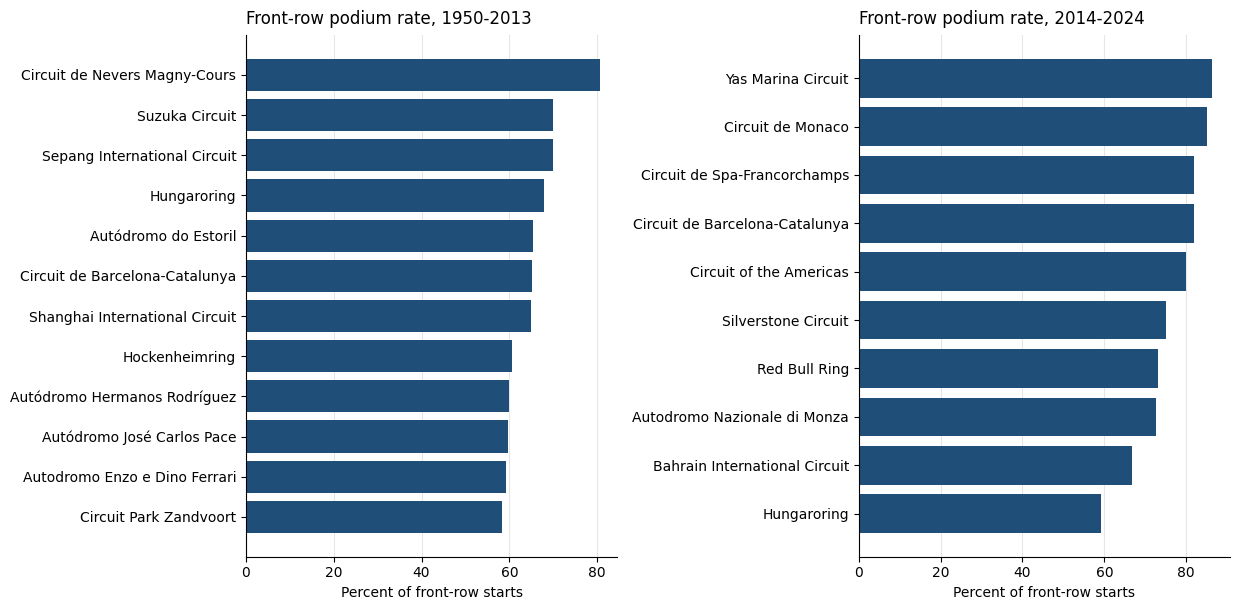

In [23]:
from src.f1_questions import (
    front_row_conversion,
    home_advantage,
    mechanical_retirements,
    narrate_front_row,
    narrate_home,
    narrate_mechanical,
    plot_front_row,
    plot_home,
    plot_mechanical,
    status_audit,
)

ranked = front_row_conversion(result.driver_race, result.cleaned["circuits"], result.cleaned["qualifying"])
print(narrate_front_row(ranked))
display(ranked["pre_2014"].head(8))
display(ranked["from_2014"].head(8))
display(ranked["rank_change"].head(8))
display(ranked["qualifying_versus_grid"])
save(plot_front_row(ranked), "12_front_row_conversion.png")

The ranking uses the grid, not the qualifying position. The table under the plot counts drivers who qualified on the front row and started further back. Their podium rate is much lower than the drivers who qualified there and started there. That gap is why a circuit ranking built from qualifying would answer a different question.

## 14. Do drivers podium more often at home once the start slot is held fixed?

The raw home rate would be misleading if home drivers also start further forward. The comparison is therefore inside a grid band: pole, rows 2–3, grid 4–10, and grid 11 or worse. Blank grids and grid 0 are excluded because there is no starting slot to control for. The join is the driver-race table, `drivers`, and `circuits`.

The comparison holds the starting position roughly fixed, so a home driver who also qualified at the front is not the whole result. grid 1: home 57.6% (92 starts), away 64.7% (1032 starts), gap -7.1 points | grid 2-3: home 53.5% (172 starts), away 51.0% (2074 starts), gap +2.5 points | grid 4-10: home 15.1% (649 starts), away 16.6% (7231 starts), gap -1.5 points | grid 11+: home 1.6% (1411 starts), away 1.7% (12372 starts), gap -0.0 points. Blank grids and grid 0 are left out, because those rows have no starting slot to control for. East German nationality is matched to German circuits, and a dual national is at home in either country. This is a difference inside a grid band, not a claim that the crowd causes the result.


,grid_band,where,starts,podium_rate
0,1,away,1032,0.647287
1,1,home,92,0.576087
2,2-3,away,2074,0.509643
3,2-3,home,172,0.534884
4,4-10,away,7231,0.165537
5,4-10,home,649,0.151002
6,11+,away,12372,0.016731
7,11+,home,1411,0.016300


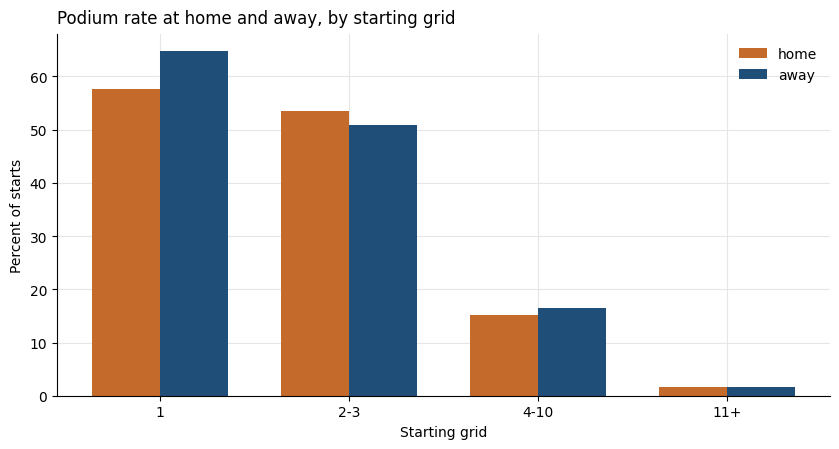

In [24]:
home = home_advantage(result.driver_race, result.cleaned["drivers"], result.cleaned["circuits"])
print(narrate_home(home))
display(home)
save(plot_home(home), "13_home_by_grid.png")

Inside a grid band the home rate is not higher in a way that survives the sample size. From pole, the home rate is lower, on only about ninety home poles. From the rest of the grid the two rates sit within a few points. `home_race` stays in the model so the ablation can measure it. The plot is not a claim that the crowd causes the finish.

## 15. Which constructors retire for mechanical reasons?

A mechanical retirement is a start whose status names a failed component. The denominator is a race start. Cars that did not start are removed. Classified finishes, crashes, driver causes, regulation decisions, and a generic `Retired` are not in the numerator. Tyres, punctures, and wings count only when the status names that part rather than a collision. The join is the driver-race table, `status`, and `constructors`. Constructors need at least 30 starts in an era, and the comparison keeps those that clear the bar in both 2014–2021 and 2022–2024.

category
mechanical        76
classified        34
not_attributed    10
crash              7
driver             7
did_not_start      4
regulation         3


A mechanical retirement is a start whose status names a failed component. Crashes, driver causes, regulation decisions, and unclassified 'Retired' rows are not counted. Cars that did not start are out of the denominator. Constructors with fewer than 30 starts in an era are left out of that era, and the comparison below keeps constructors that clear the bar in both. Highest rate in 2014-2021: McLaren at 14.5%. Highest rate in 2022-2024: Alfa Romeo at 12.5%. Largest rise: Alfa Romeo (+8.3 points). Largest fall: McLaren (-10.8 points).


,constructor,starts_2014-2021,starts_2022-2024,mechanical_retirements_2014-2021,mechanical_retirements_2022-2024,rate_2014-2021,rate_2022-2024,rate_change
0,Alfa Romeo,120.0,88.0,5.0,11.0,0.041667,0.125000,0.083333
1,Alpine F1 Team,44.0,136.0,4.0,15.0,0.090909,0.110294,0.019385
2,AlphaTauri,78.0,88.0,8.0,7.0,0.102564,0.079545,-0.023019
3,Ferrari,320.0,136.0,22.0,9.0,0.068750,0.066176,-0.002574
4,Williams,319.0,134.0,26.0,8.0,0.081505,0.059701,-0.021803
5,Aston Martin,44.0,133.0,1.0,7.0,0.022727,0.052632,0.029904
6,Haas F1 Team,241.0,135.0,23.0,7.0,0.095436,0.051852,-0.043584
7,Mercedes,320.0,136.0,14.0,6.0,0.043750,0.044118,0.000368
8,McLaren,318.0,136.0,46.0,5.0,0.144654,0.036765,-0.107889
9,Red Bull,319.0,136.0,36.0,5.0,0.112853,0.036765,-0.076088


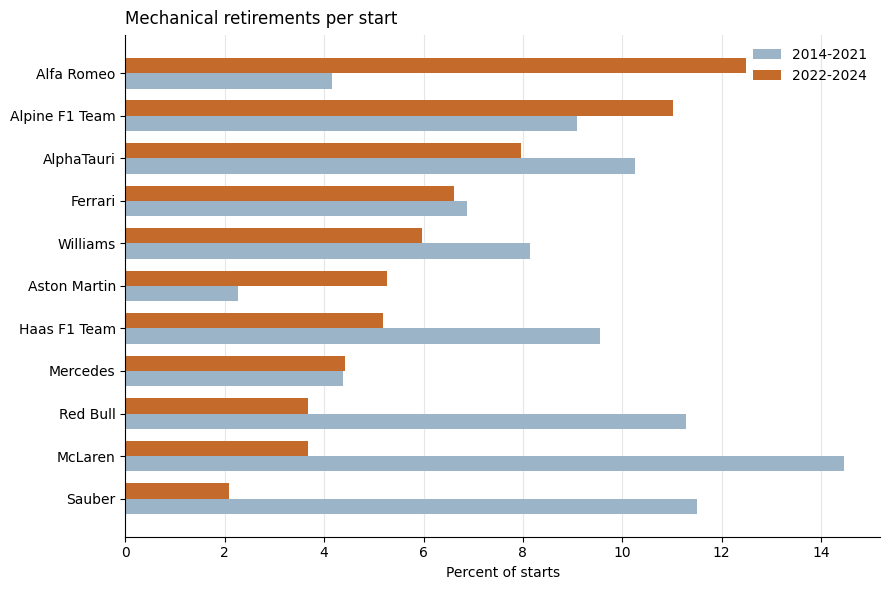

In [25]:
audit = status_audit(result.cleaned["status"])
print(audit["category"].value_counts().to_string())
mechanical = mechanical_retirements(
    result.driver_race, result.cleaned["status"], result.cleaned["constructors"]
)
print(narrate_mechanical(mechanical))
display(mechanical)
save(plot_mechanical(mechanical), "14_mechanical_retirements.png")
audit.to_csv(PATHS["audit"] / "status_categories.csv", index=False)

McLaren's high rate in 2014–2021 is the Honda years, and the rate falls once that period is over. Alfa Romeo moves the other way in 2022–2024. The status list is a judgment, and the category table is the place to defend a status that was left out. A generic `Retired` is left out because the file does not say a component failed.

## 16. Models on the same rows and the same features

The label is binary: podium or not. Exact finishing position is out of scope. Every model below sees `sample`, the 2003–2024 driver-race table from Section 12, and the same feature columns, so the scores are directly comparable.

**Split.** Chronological, fixed before any model was fit.

- Train: 2003–2018. From 2003 every completed race in this file has qualifying, so the cutoff exists in the data. A random split would put a later race in the training set and an earlier race in the test set, which is a leak in time.
- Validation: 2019–2021. Hyperparameters, the model family, and the F1 threshold are chosen here.
- Test: 2022–2024. Scored once, after every choice is frozen. These seasons are also a different regulation era. A drop from validation to test is part of the result, not a reason to peek.

**Models.** Logistic regression is the baseline: the simplest model that uses every feature. Random forest and histogram gradient boosting are the other statistical models. The neural network is a shallow feed-forward network with one or two hidden layers, trained with scikit-learn. Each family is tried with three or four settings. Every attempt is in the search table, and the comparison keeps the best validation setting of each family. A grid rule (`grid <= 3` means podium) is included as a floor that no model should lose to.

**Metrics.** Primary metric: PR-AUC. A podium is about 14% of starts, so the question is how well the model ranks the true podiums above the rest, and PR-AUC is the metric that is sensitive to the rare class. Secondary metric: F1, at a threshold chosen on validation, because the final yes-or-no call has to balance false podiums against missed podiums. Precision, recall, and ROC-AUC are also in the table. That is the full set of five scores, on train, validation, and the unseen test set.

In [26]:
import importlib.util
import subprocess

for package in ("shap", "lime"):
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package, "-q"])

from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

def to_float(series):
    as_object = series.astype("object")
    return pd.to_numeric(as_object.where(series.notna(), np.nan), errors="coerce").astype("float64")

def prepare_features(frame):
    # Grid 0 was already turned into a blank grid plus no_grid_slot = 1 in Section 12.
    return pd.DataFrame({c: to_float(frame[c]) for c in FEATURE_COLUMNS}, index=frame.index)

def make_pipeline(estimator, scale):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", clone(estimator)))
    return Pipeline(steps)

modeling = sample.sort_values(["race_date", "raceId", "driverId"]).reset_index(drop=True)
X_all, y_all = prepare_features(modeling), modeling["podium"].astype(int)
MODEL_FEATURES = list(X_all.columns)
masks = {s: modeling["split"].eq(s).to_numpy() for s in ("train", "validation", "test")}
X_train, y_train = X_all[masks["train"]], y_all[masks["train"]]
X_val, y_val = X_all[masks["validation"]], y_all[masks["validation"]]
X_test, y_test = X_all[masks["test"]], y_all[masks["test"]]

display(pd.DataFrame({
    s: {"years": f"{int(modeling.loc[m, 'year'].min())}-{int(modeling.loc[m, 'year'].max())}",
        "rows": int(m.sum()), "podium_rate_%": round(y_all[m].mean() * 100, 2)}
    for s, m in masks.items()}).T)

,years,rows,podium_rate_%
train,2003-2018,6411,14.04
validation,2019-2021,1200,15.0
test,2022-2024,1359,15.01


The podium rate is similar in the three windows, around 14–15%, so a validation or test score is not inflated by an easier class balance. The search below is the trial-and-error record: every setting that was tried, with its train and validation PR-AUC side by side so overfitting is visible.

,model,params,train_PR-AUC,val_PR-AUC,val_ROC-AUC,overfit_gap
0,Logistic regression,{'C': 0.01},0.6792,0.7235,0.9309,-0.0443
1,Logistic regression,{'C': 0.1},0.6837,0.7285,0.9311,-0.0448
2,Logistic regression,{'C': 1.0},0.6842,0.7292,0.9310,-0.0449
3,Logistic regression,{'C': 10.0},0.6844,0.7292,0.9309,-0.0448
4,Random forest,"{'max_depth': 4, 'min_samples_leaf': 20}",0.7089,0.7401,0.9379,-0.0313
5,Random forest,"{'max_depth': 8, 'min_samples_leaf': 20}",0.7455,0.7495,0.9367,-0.0039
6,Random forest,"{'max_depth': None, 'min_samples_leaf': 50}",0.7126,0.7423,0.9366,-0.0297
7,Gradient boosting,"{'learning_rate': 0.05, 'max_depth': 3, 'max_i...",0.7793,0.7210,0.9361,0.0583
8,Gradient boosting,"{'learning_rate': 0.1, 'max_leaf_nodes': 15, '...",0.8840,0.7013,0.9299,0.1826
9,Gradient boosting,"{'learning_rate': 0.03, 'max_depth': 4, 'max_i...",0.8176,0.7070,0.9331,0.1106


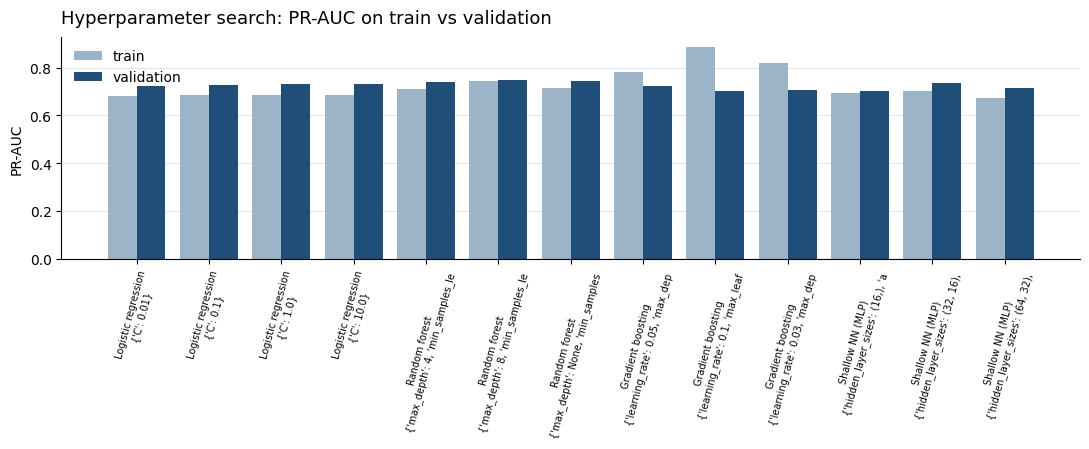

In [27]:
CANDIDATES = {
    "Logistic regression": (LogisticRegression(max_iter=3000), True,
        [{"C": 0.01}, {"C": 0.1}, {"C": 1.0}, {"C": 10.0}]),
    "Random forest": (RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE), False,
        [{"max_depth": 4, "min_samples_leaf": 20}, {"max_depth": 8, "min_samples_leaf": 20},
         {"max_depth": None, "min_samples_leaf": 50}]),
    "Gradient boosting": (HistGradientBoostingClassifier(random_state=RANDOM_STATE, early_stopping=False), False,
        [{"learning_rate": 0.05, "max_depth": 3, "max_iter": 300},
         {"learning_rate": 0.1, "max_leaf_nodes": 15, "max_iter": 150},
         {"learning_rate": 0.03, "max_depth": 4, "max_iter": 500, "l2_regularization": 1.0}]),
    "Shallow NN (MLP)": (MLPClassifier(max_iter=500, early_stopping=True, validation_fraction=0.15,
                                       n_iter_no_change=20, random_state=RANDOM_STATE), True,
        [{"hidden_layer_sizes": (16,), "alpha": 1e-3}, {"hidden_layer_sizes": (32, 16), "alpha": 1e-3},
         {"hidden_layer_sizes": (64, 32), "alpha": 1e-2}]),
}

trials, fitted = [], {}
for family, (estimator, scale, grid_params) in CANDIDATES.items():
    for params in grid_params:
        pipe = make_pipeline(estimator, scale).set_params(**{f"model__{k}": v for k, v in params.items()})
        pipe.fit(X_train, y_train)
        p_tr, p_va = pipe.predict_proba(X_train)[:, 1], pipe.predict_proba(X_val)[:, 1]
        trials.append({"model": family, "params": str(params),
                       "train_PR-AUC": average_precision_score(y_train, p_tr),
                       "val_PR-AUC": average_precision_score(y_val, p_va),
                       "val_ROC-AUC": roc_auc_score(y_val, p_va)})
        fitted[(family, str(params))] = pipe

trials = pd.DataFrame(trials)
trials["overfit_gap"] = trials["train_PR-AUC"] - trials["val_PR-AUC"]
display(trials.round(4))
trials.to_csv(PATHS["audit"] / "model_search_trials.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 4.6))
x = np.arange(len(trials))
ax.bar(x - 0.2, trials["train_PR-AUC"], 0.4, color="#9bb4c8", label="train")
ax.bar(x + 0.2, trials["val_PR-AUC"], 0.4, color=NAVY, label="validation")
ax.set_xticks(x, trials["model"] + "\n" + trials["params"].str.slice(0, 32), rotation=75, fontsize=7)
styled(ax, "Hyperparameter search: PR-AUC on train vs validation", "", "PR-AUC")
ax.legend(frameon=False)
save(fig, "15_hyperparameter_search.png")

Gradient boosting is the family that overfits: a large positive gap between train and validation. The linear model and the network have a small or negative gap, which means they are not memorising the training seasons. The best setting of each family is now frozen, the F1 threshold is chosen on validation, and the five metrics are computed on all three splits.

In [28]:
def best_f1_threshold(y_true, proba):
    precision, recall, thr = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thr[int(np.nanargmax(f1[:-1]))])

def evaluate(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, proba), "PR-AUC": average_precision_score(y_true, proba),
            "F1": f1_score(y_true, pred, zero_division=0),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0)}

best_rows = trials.loc[trials.groupby("model")["val_PR-AUC"].idxmax()]
final_pipelines = {r.model: fitted[(r.model, r.params)] for r in best_rows.itertuples()}
display(best_rows[["model", "params", "val_PR-AUC"]])

split_data = {"train": (X_train, y_train), "validation": (X_val, y_val), "test": (X_test, y_test)}
thresholds = {n: best_f1_threshold(y_val, p.predict_proba(X_val)[:, 1]) for n, p in final_pipelines.items()}
probas = {n: {s: p.predict_proba(X)[:, 1] for s, (X, _) in split_data.items()} for n, p in final_pipelines.items()}

# Naive floor: rank by grid, predict podium when grid <= 3. A blank grid is treated as the back.
probas["Grid rule (grid <= 3)"] = {s: (-X["grid"]).fillna(-X["grid"].max()).to_numpy() for s, (X, _) in split_data.items()}
thresholds["Grid rule (grid <= 3)"] = -3.0

comparison_table = pd.DataFrame([
    {"model": n, "split": s, "threshold": thresholds[n], **evaluate(y, probas[n][s], thresholds[n])}
    for n in probas for s, (_, y) in split_data.items()])
comparison_table.to_csv(PATHS["processed"] / "model_comparison.csv", index=False)

wide = comparison_table.pivot(index="model", columns="split", values=["PR-AUC", "ROC-AUC", "F1", "Precision", "Recall"])
display(wide.reindex(columns=["train", "validation", "test"], level=1).round(3))

,model,params,val_PR-AUC
7,Gradient boosting,"{'learning_rate': 0.05, 'max_depth': 3, 'max_i...",0.721002
2,Logistic regression,{'C': 1.0},0.729194
5,Random forest,"{'max_depth': 8, 'min_samples_leaf': 20}",0.749464
11,Shallow NN (MLP),"{'hidden_layer_sizes': (32, 16), 'alpha': 0.001}",0.737172


PR-AUC                   ROC-AUC                       F1                   Precision  \
split                  train validation   test   train validation   test  train validation   test     train   
model                                                                                                         
Gradient boosting      0.779      0.721  0.684   0.954      0.936  0.913  0.710      0.729  0.635     0.697   
Grid rule (grid <= 3)  0.618      0.676  0.647   0.907      0.917  0.914  0.638      0.717  0.649     0.638   
Logistic regression    0.684      0.729  0.710   0.928      0.931  0.938  0.665      0.725  0.683     0.577   
Random forest          0.746      0.749  0.715   0.947      0.937  0.938  0.697      0.733  0.683     0.628   
Shallow NN (MLP)       0.703      0.737  0.706   0.935      0.932  0.932  0.667      0.725  0.665     0.640   

                                        Recall                    
split                 validation   test  train validation   test  
model                                                             
Gradient boosting          0.719  0.658  0.722      0.739  0.613  
Grid rule (grid <= 3)      0.717  0.650  0.638      0.717  0.647  
Logistic regression        0.649  0.597  0.784      0.822  0.799  
Random forest              0.665  0.613  0.783      0.817  0.770  
Shallow NN (MLP)           0.692  0.654  0.698      0.761  0.676

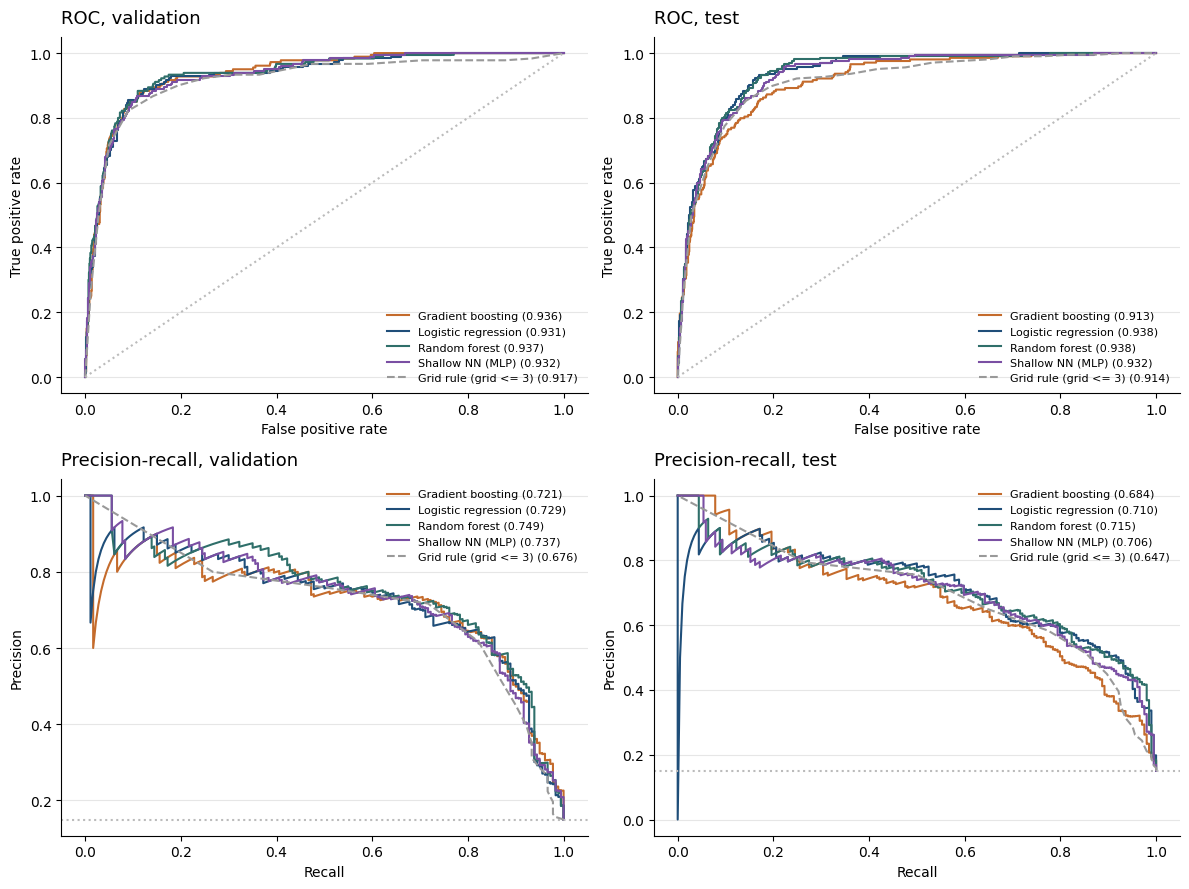

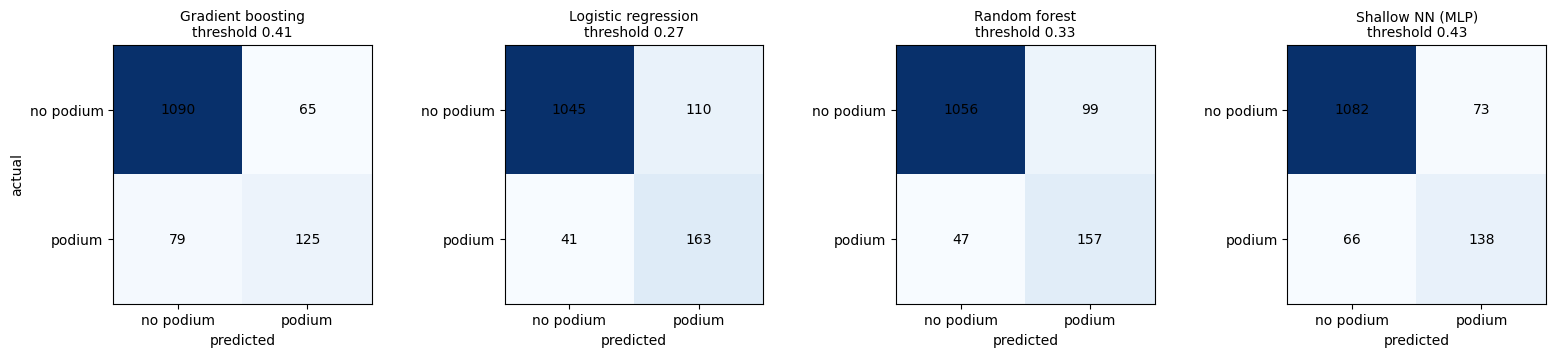

Primary metric PR-AUC, secondary metric F1. Chosen on validation PR-AUC: Random forest (validation PR-AUC 0.749, F1 0.733).
Unseen test years for Random forest: PR-AUC 0.715, ROC-AUC 0.938, F1 0.683, precision 0.613, recall 0.770.
Baseline logistic regression on test: PR-AUC 0.710, F1 0.683. Grid rule on test: PR-AUC 0.647. No-skill PR-AUC = podium rate 0.150.


In [29]:
palette = {"Grid rule (grid <= 3)": "#999999", "Logistic regression": NAVY, "Random forest": TEAL,
           "Gradient boosting": CLAY, "Shallow NN (MLP)": "#7a4fa3"}
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for col, s in enumerate(("validation", "test")):
    y = split_data[s][1]
    for n, by in probas.items():
        ls = "--" if n.startswith("Grid") else "-"
        fpr, tpr, _ = roc_curve(y, by[s]); prec, rec, _ = precision_recall_curve(y, by[s])
        axes[0, col].plot(fpr, tpr, ls, color=palette[n], label=f"{n} ({roc_auc_score(y, by[s]):.3f})")
        axes[1, col].plot(rec, prec, ls, color=palette[n], label=f"{n} ({average_precision_score(y, by[s]):.3f})")
    axes[0, col].plot([0, 1], [0, 1], ":", color="#bbbbbb")
    axes[1, col].axhline(y.mean(), ls=":", color="#bbbbbb")
    styled(axes[0, col], f"ROC, {s}", "False positive rate", "True positive rate")
    styled(axes[1, col], f"Precision-recall, {s}", "Recall", "Precision")
    axes[0, col].legend(frameon=False, fontsize=8); axes[1, col].legend(frameon=False, fontsize=8)
save(fig, "16_roc_pr_curves.png")

fig, axes = plt.subplots(1, len(final_pipelines), figsize=(4 * len(final_pipelines), 3.6))
for ax, n in zip(axes, final_pipelines):
    cm = confusion_matrix(y_test, (probas[n]["test"] >= thresholds[n]).astype(int))
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center")
    ax.set_xticks([0, 1], ["no podium", "podium"]); ax.set_yticks([0, 1], ["no podium", "podium"])
    ax.set_title(f"{n}\nthreshold {thresholds[n]:.2f}", fontsize=10); ax.set_xlabel("predicted")
axes[0].set_ylabel("actual")
save(fig, "17_confusion_matrices_test.png")

val = comparison_table.query("split == 'validation'").set_index("model").drop("Grid rule (grid <= 3)")
chosen = val["PR-AUC"].idxmax()
test = comparison_table.query("split == 'test'").set_index("model")
test_leader = test.drop("Grid rule (grid <= 3)")["PR-AUC"].idxmax()
print(f"Primary metric PR-AUC, secondary metric F1. Chosen on validation PR-AUC: {chosen} "
      f"(validation PR-AUC {val.loc[chosen, 'PR-AUC']:.3f}, F1 {val.loc[chosen, 'F1']:.3f}).")
print(f"Unseen test years for {chosen}: PR-AUC {test.loc[chosen, 'PR-AUC']:.3f}, ROC-AUC {test.loc[chosen, 'ROC-AUC']:.3f}, "
      f"F1 {test.loc[chosen, 'F1']:.3f}, precision {test.loc[chosen, 'Precision']:.3f}, recall {test.loc[chosen, 'Recall']:.3f}.")
print(f"Baseline logistic regression on test: PR-AUC {test.loc['Logistic regression', 'PR-AUC']:.3f}, F1 {test.loc['Logistic regression', 'F1']:.3f}. "
      f"Grid rule on test: PR-AUC {test.loc['Grid rule (grid <= 3)', 'PR-AUC']:.3f}. No-skill PR-AUC = podium rate {y_test.mean():.3f}.")
if test_leader != chosen:
    print(f"On the test years {test_leader} has a higher PR-AUC ({test.loc[test_leader, 'PR-AUC']:.3f}). "
          "That is reported and does not change the choice, because the test set is not used to choose.")

Every model clears the grid rule and the no-skill line, so the features beyond the grid are earning their place. The model with the highest validation PR-AUC is the one carried forward. If another family is higher on the test years, that is printed above and left alone: choosing on test would turn the test set into a second validation set, and the test score would stop being an estimate of unseen performance.

The confusion matrices use the frozen validation threshold. Missed podiums (bottom-left) and false podiums (top-right) are the two errors that F1 balances. The ROC curves sit close together because the negative class is large and easy; the precision-recall curves separate the models more, which is the reason PR-AUC is the primary metric.

## 17. Feature-group ablation

Section 12 is the reason each group was a candidate: the training-year podium rates. This section measures what each group contributes after training. One group is removed at a time, the selected model is refit with the same hyperparameters on the remaining columns, and the validation PR-AUC is compared with the full model. The test set is not used here.

In [30]:
from src.f1_features import FEATURE_GROUPS

selected_pipeline = final_pipelines[chosen]
selected_estimator = selected_pipeline.named_steps["model"]
selected_uses_scaling = "scale" in selected_pipeline.named_steps

ABLATED_GROUPS = {name: list(columns) for name, columns in FEATURE_GROUPS.items()}
assert set(MODEL_FEATURES) == set(sum(ABLATED_GROUPS.values(), [])), "Unaccounted model features!"
assert all(c in X_train.columns for c in MODEL_FEATURES)

print("Model selected in Section 16:", chosen)
print("Selected estimator and hyperparameters:", selected_estimator)
print("Uses StandardScaler:", selected_uses_scaling)
display(pd.DataFrame([
    {"group": group, "n_columns": len(columns), "columns": ", ".join(columns)}
    for group, columns in ABLATED_GROUPS.items()
]))

Model selected in Section 16: Random forest
Selected estimator and hyperparameters: RandomForestClassifier(max_depth=8, min_samples_leaf=20, n_estimators=300,
                       n_jobs=-1, random_state=42)
Uses StandardScaler: False


,group,n_columns,columns
0,grid,3,"grid, no_grid_slot, front_row"
1,qualifying,3,"quali_position, reached_q3, quali_position_mis..."
2,form,5,"driver_podium_rate_last5, driver_points_last5,..."
3,standings,4,"driver_standing_entering, constructor_standing..."
4,home,1,home_race


,removed_group,n_features,train_PR-AUC,val_PR-AUC,val_ROC-AUC,val_F1,PR-AUC_drop
0,None (all features),16,0.7455,0.7495,0.9367,0.7332,0.0000
1,grid,13,0.7316,0.7157,0.9329,0.7218,0.0338
2,qualifying,13,0.7402,0.7329,0.9361,0.7333,0.0166
3,form,11,0.7192,0.7484,0.9359,0.7427,0.0010
4,standings,12,0.7326,0.7407,0.9372,0.7360,0.0088
5,home,15,0.7394,0.7512,0.9382,0.7385,-0.0017


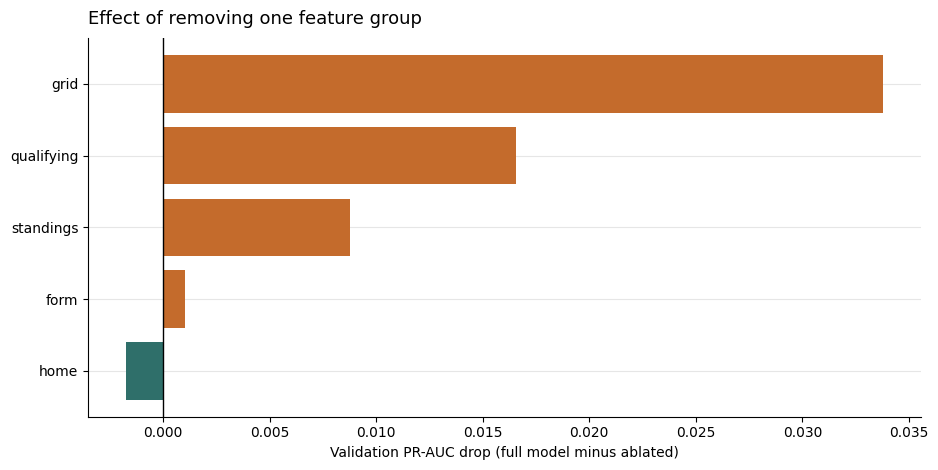

Full-feature validation PR-AUC: 0.7495
Largest loss from removing 'grid': +0.0338 PR-AUC
Smallest effect from removing 'home': -0.0017 PR-AUC


In [31]:
ablation_rows = []
base_p_train = selected_pipeline.predict_proba(X_train)[:, 1]
base_p_val = selected_pipeline.predict_proba(X_val)[:, 1]
base_train_ap = average_precision_score(y_train, base_p_train)
base_val_ap = average_precision_score(y_val, base_p_val)

ablation_rows.append({
    "removed_group": "None (all features)", "n_features": len(MODEL_FEATURES),
    "train_PR-AUC": base_train_ap, "val_PR-AUC": base_val_ap,
    "val_ROC-AUC": roc_auc_score(y_val, base_p_val),
    "val_F1": f1_score(y_val, base_p_val >= best_f1_threshold(y_val, base_p_val), zero_division=0),
    "PR-AUC_drop": 0.0,
})

for group_name, removed_columns in ABLATED_GROUPS.items():
    kept_columns = [c for c in MODEL_FEATURES if c not in removed_columns]
    assert kept_columns, "Ablation removed every available feature"
    ablated_pipeline = clone(selected_pipeline)
    ablated_pipeline.fit(X_train[kept_columns], y_train)
    p_train = ablated_pipeline.predict_proba(X_train[kept_columns])[:, 1]
    p_val = ablated_pipeline.predict_proba(X_val[kept_columns])[:, 1]
    ap = average_precision_score(y_val, p_val)
    ablation_rows.append({
        "removed_group": group_name, "n_features": len(kept_columns),
        "train_PR-AUC": average_precision_score(y_train, p_train),
        "val_PR-AUC": ap,
        "val_ROC-AUC": roc_auc_score(y_val, p_val),
        "val_F1": f1_score(y_val, p_val >= best_f1_threshold(y_val, p_val), zero_division=0),
        "PR-AUC_drop": base_val_ap - ap,
    })

ablation_results = pd.DataFrame(ablation_rows)
display(ablation_results.round(4))
ablation_results.to_csv(PATHS["audit"] / "feature_group_ablation.csv", index=False)

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ablation_plot = ablation_results.iloc[1:].sort_values("PR-AUC_drop")
bar_colors = [CLAY if drop >= 0 else TEAL for drop in ablation_plot["PR-AUC_drop"]]
ax.barh(ablation_plot["removed_group"], ablation_plot["PR-AUC_drop"], color=bar_colors)
ax.axvline(0, color="black", lw=1)
styled(ax, "Effect of removing one feature group", "Validation PR-AUC drop (full model minus ablated)", "")
save(fig, "18_feature_group_ablation.png")

biggest_drop = ablation_results.iloc[1:].sort_values("PR-AUC_drop", ascending=False).iloc[0]
smallest = ablation_results.iloc[1:].sort_values("PR-AUC_drop").iloc[0]
print(f"Full-feature validation PR-AUC: {base_val_ap:.4f}")
print(f"Largest loss from removing '{biggest_drop['removed_group']}': {biggest_drop['PR-AUC_drop']:+.4f} PR-AUC")
print(f"Smallest effect from removing '{smallest['removed_group']}': {smallest['PR-AUC_drop']:+.4f} PR-AUC")

A positive bar means the model was using that group: removing it costs validation PR-AUC. A bar near zero or negative means the group is redundant once the other groups are present, because they carry the same information (a driver who leads the standings usually also has strong recent form and a good grid slot). The ranking is predictive evidence about this model. It is not a statement that the group causes podiums.

## 18. Preprocessing-order experiments

The order of preprocessing steps can change what the model sees. Each experiment below keeps the model and its hyperparameters fixed and swaps only the order of two steps, so a difference in validation PR-AUC is caused by the order alone.

- Experiment 1: clip extreme values to the 5th–95th percentile, then impute the median, against impute first and clip after.
- Experiment 2: impute, then a rank-based quantile transform to a normal shape, against the quantile transform first.
- Experiment 3: on the baseline logistic regression, impute then standardise, against standardising the observed values first and filling blanks afterwards.

The first two experiments use the model selected in Section 16. Tree models are invariant to any monotonic transform, so if that model is a tree, Experiments 1 and 2 are expected to show no difference, and that result is itself the finding. Experiment 3 uses a linear model, where the position of the imputation changes the mean and spread that the scaler learns, so an order effect can appear.

In [32]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import QuantileTransformer

CONTINUOUS_NAMES = [
    "grid", "quali_position", "driver_podium_rate_last5", "driver_points_last5",
    "constructor_podium_rate_last5", "career_starts",
    "driver_standing_entering", "constructor_standing_entering", "season_round",
]
CONTINUOUS_INDICES = tuple(MODEL_FEATURES.index(c) for c in CONTINUOUS_NAMES)

class SelectedColumnWinsorizer(BaseEstimator, TransformerMixin):
    """Learn training-only clipping thresholds; preserve NaNs for later imputation."""
    def __init__(self, indices=(), lower=0.05, upper=0.95):
        self.indices = indices
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        data = np.asarray(X, dtype=float)
        self.low_ = np.full(data.shape[1], -np.inf)
        self.high_ = np.full(data.shape[1], np.inf)
        for i in self.indices:
            valid = data[:, i][np.isfinite(data[:, i])]
            if len(valid):
                self.low_[i], self.high_[i] = np.quantile(valid, [self.lower, self.upper])
        return self

    def transform(self, X):
        data = np.asarray(X, dtype=float).copy()
        for i in self.indices:
            data[:, i] = np.clip(data[:, i], self.low_[i], self.high_[i])
        return data

class SelectedColumnQuantileTransformer(BaseEstimator, TransformerMixin):
    """Rank-based transform for the continuous features only. Binary flags are untouched."""
    def __init__(self, indices=(), n_quantiles=100, random_state=42):
        self.indices = indices
        self.n_quantiles = n_quantiles
        self.random_state = random_state

    def fit(self, X, y=None):
        data = np.asarray(X, dtype=float)
        self.qt_ = QuantileTransformer(
            n_quantiles=min(self.n_quantiles, len(data)),
            output_distribution="normal", random_state=self.random_state,
        )
        self.qt_.fit(data[:, self.indices])
        return self

    def transform(self, X):
        data = np.asarray(X, dtype=float).copy()
        data[:, self.indices] = self.qt_.transform(data[:, self.indices])
        return data

def make_ordered_pipeline(preprocessing_steps):
    steps = list(preprocessing_steps)
    if selected_uses_scaling:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", clone(selected_estimator)))
    return Pipeline(steps)

order_variants = {
    "1A clip -> impute": make_ordered_pipeline([
        ("clip", SelectedColumnWinsorizer(CONTINUOUS_INDICES)),
        ("impute", SimpleImputer(strategy="median")),
    ]),
    "1B impute -> clip": make_ordered_pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("clip", SelectedColumnWinsorizer(CONTINUOUS_INDICES)),
    ]),
    "2A impute -> quantile": make_ordered_pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("quantile", SelectedColumnQuantileTransformer(CONTINUOUS_INDICES, random_state=RANDOM_STATE)),
    ]),
    "2B quantile -> impute": make_ordered_pipeline([
        ("quantile", SelectedColumnQuantileTransformer(CONTINUOUS_INDICES, random_state=RANDOM_STATE)),
        ("impute", SimpleImputer(strategy="median")),
    ]),
}

from src.f1_models import ScaleObservedThenImpute

linear_variants = {
    "3A impute -> scale (logistic)": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=1.0, max_iter=3000)),
    ]),
    "3B scale observed -> impute (logistic)": Pipeline([
        ("prepare", ScaleObservedThenImpute()),
        ("model", LogisticRegression(C=1.0, max_iter=3000)),
    ]),
}
print("Continuous features transformed in Experiments 1 and 2:", CONTINUOUS_NAMES)
print("Order variants:", list(order_variants) + list(linear_variants))

Continuous features transformed in Experiments 1 and 2: ['grid', 'quali_position', 'driver_podium_rate_last5', 'driver_points_last5', 'constructor_podium_rate_last5', 'career_starts', 'driver_standing_entering', 'constructor_standing_entering', 'season_round']
Order variants: ['1A clip -> impute', '1B impute -> clip', '2A impute -> quantile', '2B quantile -> impute', '3A impute -> scale (logistic)', '3B scale observed -> impute (logistic)']


,variant,experiment,train_PR-AUC,val_PR-AUC,val_ROC-AUC,val_F1,train_val_gap
0,Section 16 selection (Random forest),reference,0.7455,0.7495,0.9367,0.7332,-0.0039
1,1A clip -> impute,1,0.7379,0.7368,0.9366,0.7394,0.0011
2,1B impute -> clip,1,0.7379,0.7368,0.9366,0.7394,0.0011
3,2A impute -> quantile,2,0.7456,0.7492,0.9367,0.7332,-0.0037
4,2B quantile -> impute,2,0.7456,0.7492,0.9367,0.7332,-0.0036
5,3A impute -> scale (logistic),3,0.6842,0.7292,0.9310,0.7255,-0.0449
6,3B scale observed -> impute (logistic),3,0.6844,0.7294,0.9310,0.7255,-0.0450


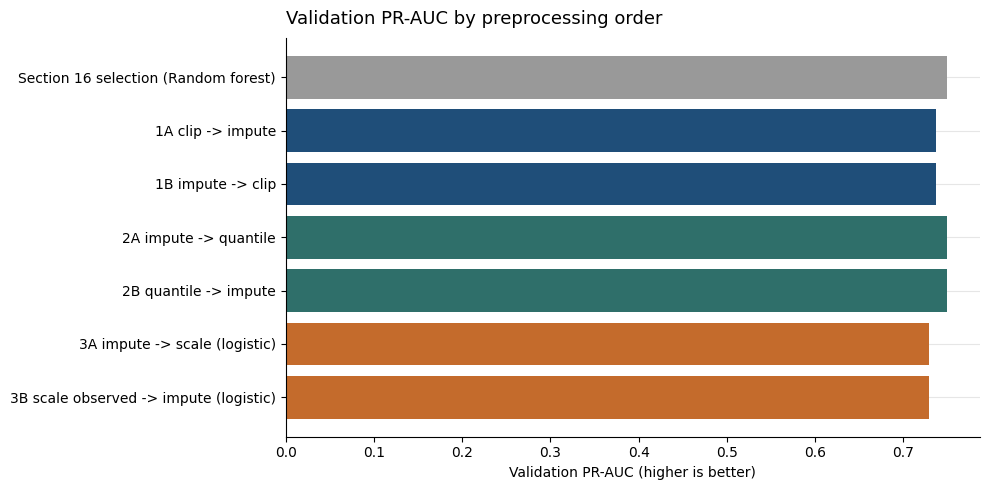

Experiment 1: clipping / imputation: 1A clip -> impute = 0.7368, 1B impute -> clip = 0.7368, difference A - B = +0.0000
Experiment 2: quantile / imputation: 2A impute -> quantile = 0.7492, 2B quantile -> impute = 0.7492, difference A - B = +0.0000
Experiment 3: scaling / imputation on logistic regression: 3A impute -> scale (logistic) = 0.7292, 3B scale observed -> impute (logistic) = 0.7294, difference A - B = -0.0002
Random forest is a tree model. Clipping, quantile transforms, and their order do not change a tree's splits, so Experiments 1 and 2 are expected to be flat. Experiment 3 is the order test that can move, because a linear model reads the scale.
The order is chosen on validation evidence. The test set is not used here.


In [33]:
order_rows = [{
    "variant": f"Section 16 selection ({chosen})", "experiment": "reference",
    "train_PR-AUC": base_train_ap, "val_PR-AUC": base_val_ap,
    "val_ROC-AUC": roc_auc_score(y_val, base_p_val),
    "val_F1": f1_score(y_val, base_p_val >= best_f1_threshold(y_val, base_p_val), zero_division=0),
}]

for name, experiment_pipeline in list(order_variants.items()) + list(linear_variants.items()):
    experiment_pipeline.fit(X_train[MODEL_FEATURES], y_train)
    p_train = experiment_pipeline.predict_proba(X_train[MODEL_FEATURES])[:, 1]
    p_val = experiment_pipeline.predict_proba(X_val[MODEL_FEATURES])[:, 1]
    thresh = best_f1_threshold(y_val, p_val)
    order_rows.append({
        "variant": name, "experiment": name[0],
        "train_PR-AUC": average_precision_score(y_train, p_train),
        "val_PR-AUC": average_precision_score(y_val, p_val),
        "val_ROC-AUC": roc_auc_score(y_val, p_val),
        "val_F1": f1_score(y_val, p_val >= thresh, zero_division=0),
    })

preprocess_results = pd.DataFrame(order_rows)
preprocess_results["train_val_gap"] = preprocess_results["train_PR-AUC"] - preprocess_results["val_PR-AUC"]
display(preprocess_results.round(4))
preprocess_results.to_csv(PATHS["audit"] / "preprocessing_order.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#999999", NAVY, NAVY, TEAL, TEAL, CLAY, CLAY]
ax.barh(preprocess_results["variant"], preprocess_results["val_PR-AUC"], color=colors[:len(preprocess_results)])
ax.invert_yaxis()
styled(ax, "Validation PR-AUC by preprocessing order", "Validation PR-AUC (higher is better)", "")
save(fig, "19_preprocessing_order.png")

by_variant = preprocess_results.set_index("variant")
for exp, first, second in [
    ("1: clipping / imputation", "1A clip -> impute", "1B impute -> clip"),
    ("2: quantile / imputation", "2A impute -> quantile", "2B quantile -> impute"),
    ("3: scaling / imputation on logistic regression", "3A impute -> scale (logistic)", "3B scale observed -> impute (logistic)"),
]:
    p_a = float(by_variant.loc[first, "val_PR-AUC"])
    p_b = float(by_variant.loc[second, "val_PR-AUC"])
    print(f"Experiment {exp}: {first} = {p_a:.4f}, {second} = {p_b:.4f}, difference A - B = {p_a - p_b:+.4f}")
is_tree = not selected_uses_scaling
if is_tree:
    print(f"{chosen} is a tree model. Clipping, quantile transforms, and their order do not change a tree's splits, "
          "so Experiments 1 and 2 are expected to be flat. Experiment 3 is the order test that can move, because a linear model reads the scale.")
print("The order is chosen on validation evidence. The test set is not used here.")

,variant,missing_after,min,median,max
0,"raw, blanks left empty",474,1.000,11.000,27.000
1,1A clip -> impute,0,2.000,11.000,22.000
2,1B impute -> clip,0,2.000,11.000,22.000
3,2A impute -> quantile,0,-5.199,-0.013,5.199
4,2B quantile -> impute,0,-5.199,-0.013,5.199
5,3A impute -> scale (logistic),0,-1.649,-0.049,2.510
6,3B scale observed -> impute (logistic),0,-1.590,-0.051,2.412


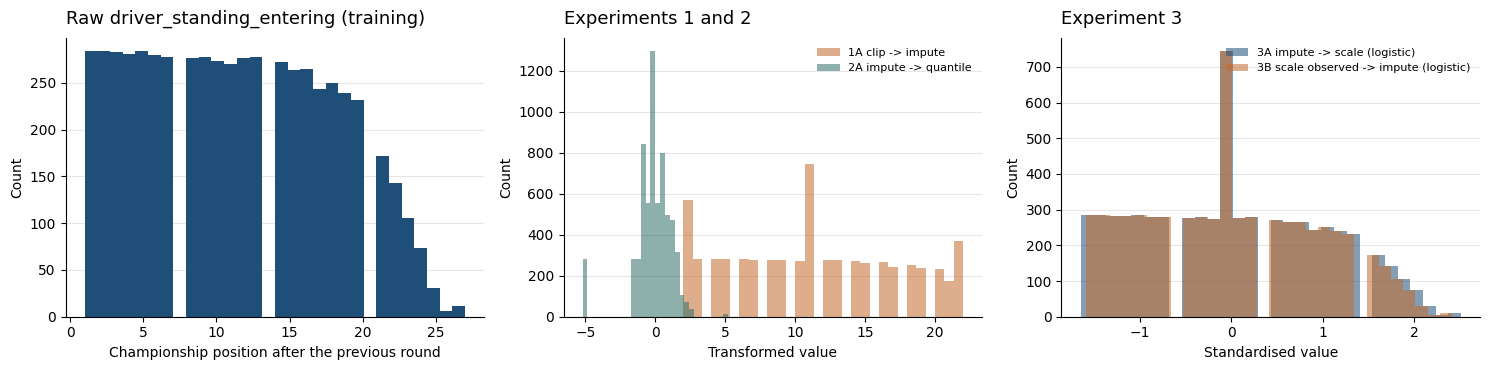

In [34]:
feature_to_show = "driver_standing_entering"
feature_idx = MODEL_FEATURES.index(feature_to_show)
raw_values = X_train[feature_to_show].to_numpy(dtype=float)
distribution_rows = [{
    "variant": "raw, blanks left empty", "missing_after": int(np.isnan(raw_values).sum()),
    "min": float(np.nanmin(raw_values)), "median": float(np.nanmedian(raw_values)), "max": float(np.nanmax(raw_values)),
}]
all_variants = {**order_variants, **linear_variants}
for name, pipe in all_variants.items():
    transformed = pipe[:-1].transform(X_train[MODEL_FEATURES])
    values = np.asarray(transformed, dtype=float)[:, feature_idx]
    distribution_rows.append({
        "variant": name, "missing_after": int(np.isnan(values).sum()),
        "min": float(np.nanmin(values)), "median": float(np.nanmedian(values)), "max": float(np.nanmax(values)),
    })
display(pd.DataFrame(distribution_rows).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(raw_values[np.isfinite(raw_values)], bins=30, color=NAVY)
styled(axes[0], f"Raw {feature_to_show} (training)", "Championship position after the previous round", "Count")
for name, color in [("1A clip -> impute", CLAY), ("2A impute -> quantile", TEAL)]:
    values = np.asarray(all_variants[name][:-1].transform(X_train[MODEL_FEATURES]), dtype=float)[:, feature_idx]
    axes[1].hist(values[np.isfinite(values)], bins=30, alpha=0.55, label=name, color=color)
styled(axes[1], "Experiments 1 and 2", "Transformed value", "Count")
axes[1].legend(frameon=False, fontsize=8)
for name, color in [("3A impute -> scale (logistic)", NAVY), ("3B scale observed -> impute (logistic)", CLAY)]:
    values = np.asarray(all_variants[name][:-1].transform(X_train[MODEL_FEATURES]), dtype=float)[:, feature_idx]
    axes[2].hist(values[np.isfinite(values)], bins=30, alpha=0.55, label=name, color=color)
styled(axes[2], "Experiment 3", "Standardised value", "Count")
axes[2].legend(frameon=False, fontsize=8)
save(fig, "20_preprocessing_distributions.png")

The distribution table is the effect of each step on the data. `driver_standing_entering` is blank at every round 1, so it shows where the imputed value lands. Clipping keeps the original units and only pulls the tails in. The quantile transform changes the shape to a bell and the range to roughly −5 to 5. In Experiment 3, imputing before scaling puts the filled blanks at exactly the median and lets them shrink the standard deviation; scaling the observed values first keeps the blanks out of the mean and spread, and then fills them with the scaled median. Whichever order has the higher validation PR-AUC is the one to keep; the printed differences above are the evidence.

## 19. Global and local explanations

Three views of the selected model, in order of scope.

- **Permutation importance** (global): shuffle one column on the validation years and record the drop in PR-AUC. A large drop means the model leans on that column. Correlated features can hide each other's importance, because shuffling one leaves the other intact.
- **SHAP** (global and local): the model-agnostic permutation explainer attributes the predicted podium probability to each feature. The bar and beeswarm plots are the global picture over a validation sample; the waterfall is one row, and its base value plus contributions reconcile to that row's predicted probability.
- **LIME** (local): fits a small linear model around the same row and reports which conditions push the podium probability up or down.

Important: none of these is a causal effect. A feature with a large weight is a feature the model relies on to make predictions. It is not proof that the feature causes podium finishes.

,feature,importance_mean,importance_std
0,grid,0.06162,0.01960
3,quali_position,0.03886,0.01587
11,driver_standing_entering,0.00904,0.01268
2,front_row,0.00828,0.00971
14,season_round,0.00574,0.00149
6,driver_podium_rate_last5,0.00554,0.01266
8,constructor_podium_rate_last5,0.00519,0.01240
12,constructor_standing_entering,0.00411,0.00627
9,career_starts,0.00344,0.00471
7,driver_points_last5,0.00344,0.01062


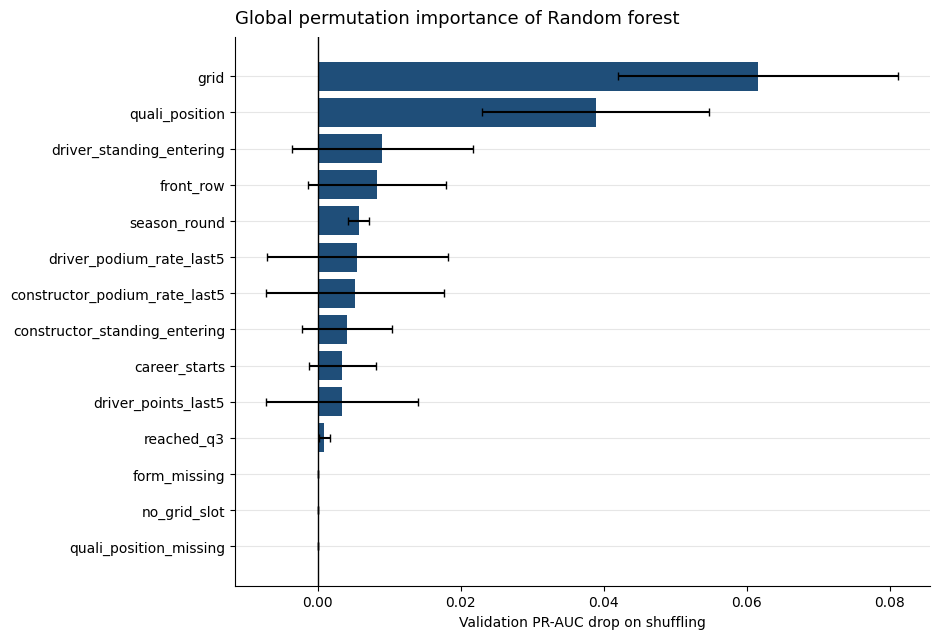

Highest mean permutation importance: grid
Importance estimates vary across shuffles (error bars). Correlated features can conceal shared importance.


In [35]:
from sklearn.inspection import permutation_importance

permuted = permutation_importance(
    selected_pipeline, X_val[MODEL_FEATURES], y_val,
    scoring="average_precision", n_repeats=5,
    random_state=RANDOM_STATE, n_jobs=1,
)
permutation_results = pd.DataFrame({
    "feature": MODEL_FEATURES,
    "importance_mean": permuted.importances_mean,
    "importance_std": permuted.importances_std,
}).sort_values("importance_mean", ascending=False)
display(permutation_results.round(5))
permutation_results.to_csv(PATHS["audit"] / "permutation_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(9.5, 6.5))
shown = permutation_results.head(14).sort_values("importance_mean")
ax.barh(shown["feature"], shown["importance_mean"],
        xerr=shown["importance_std"], color=NAVY, capsize=3)
ax.axvline(0, color="black", lw=1)
styled(ax, f"Global permutation importance of {chosen}", "Validation PR-AUC drop on shuffling", "")
save(fig, "21_permutation_importance.png")
print("Highest mean permutation importance:", permutation_results.iloc[0]["feature"])
print("Importance estimates vary across shuffles (error bars). Correlated features can conceal shared importance.")

,feature,mean_abs_shap_probability
3,quali_position,0.04703
0,grid,0.04183
6,driver_podium_rate_last5,0.02585
11,driver_standing_entering,0.02016
8,constructor_podium_rate_last5,0.01722
7,driver_points_last5,0.01569
2,front_row,0.01222
12,constructor_standing_entering,0.01093
9,career_starts,0.00260
4,reached_q3,0.00209


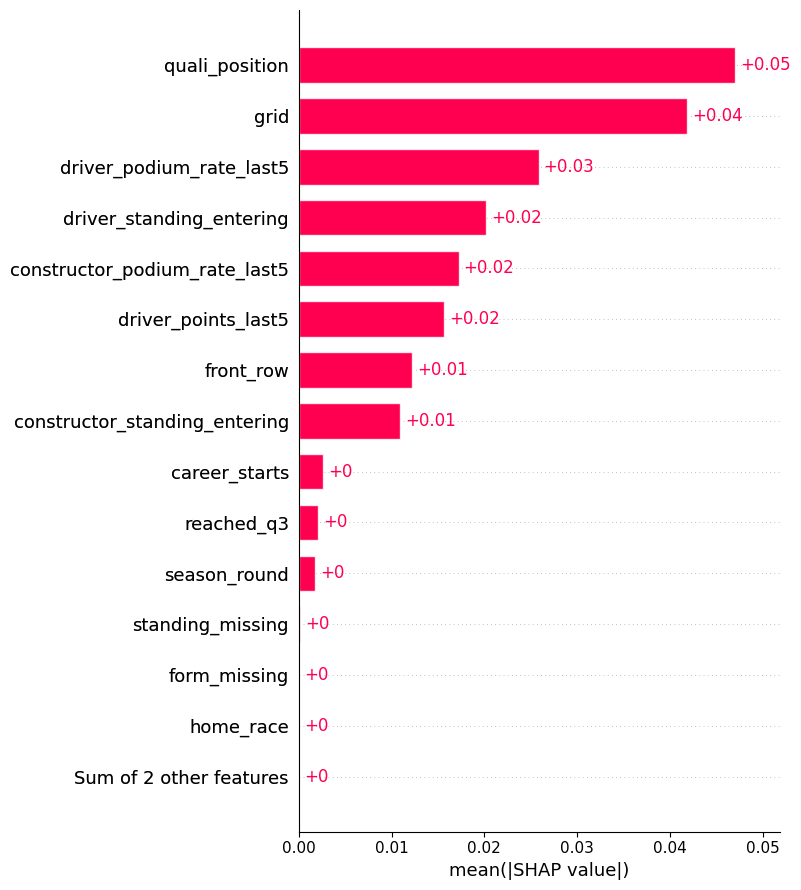

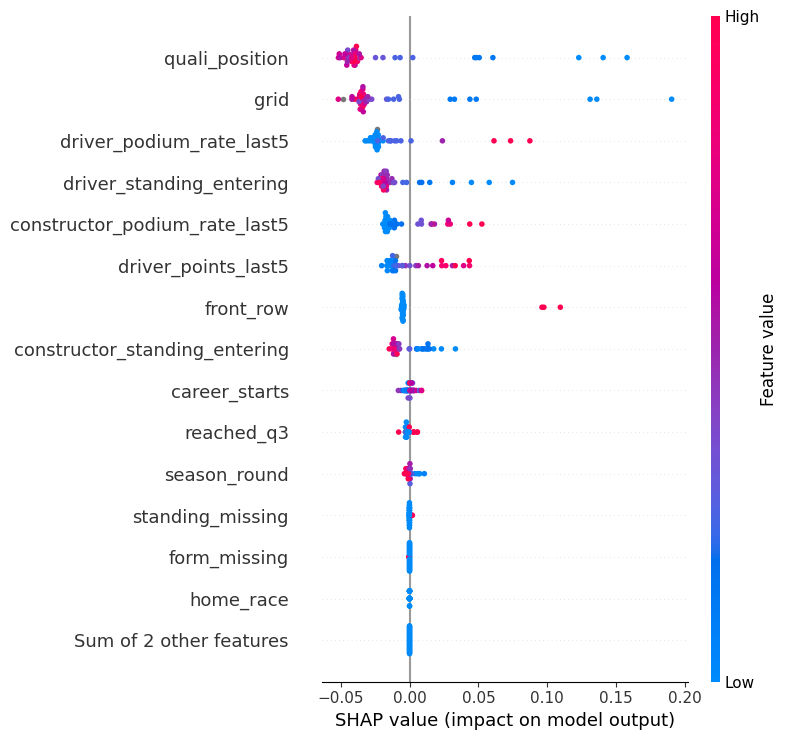

SHAP reference sample: 40 training driver-races
SHAP explained sample: 40 validation driver-races
Top mean |SHAP| feature: quali_position
Mean |SHAP| is reliance, not proof of causality.


In [36]:
import shap

rng = np.random.default_rng(RANDOM_STATE)
background_positions = np.sort(rng.choice(len(X_train), size=min(40, len(X_train)), replace=False))
explain_positions = np.sort(rng.choice(len(X_val), size=min(40, len(X_val)), replace=False))
shap_background = X_train[MODEL_FEATURES].iloc[background_positions].copy()
X_explain = X_val[MODEL_FEATURES].iloc[explain_positions].copy()

def podium_predict_proba(raw_values):
    raw_frame = pd.DataFrame(np.asarray(raw_values, dtype=float), columns=MODEL_FEATURES)
    return selected_pipeline.predict_proba(raw_frame)[:, 1]

shap_masker = shap.maskers.Independent(shap_background, max_samples=len(shap_background))
shap_explainer = shap.Explainer(podium_predict_proba, shap_masker, algorithm="permutation")
shap_values = shap_explainer(
    X_explain,
    max_evals=2 * len(MODEL_FEATURES) + 1,
    batch_size=64,
    silent=True,
)
assert shap_values.values.shape == (len(X_explain), len(MODEL_FEATURES))

shap_summary = pd.DataFrame({
    "feature": MODEL_FEATURES,
    "mean_abs_shap_probability": np.abs(shap_values.values).mean(axis=0),
}).sort_values("mean_abs_shap_probability", ascending=False)
display(shap_summary.round(5))
shap_summary.to_csv(PATHS["audit"] / "shap_global.csv", index=False)

shap.plots.bar(shap_values, max_display=15, show=False)
save(plt.gcf(), "22_shap_global_bar.png")
shap.plots.beeswarm(shap_values, max_display=15, show=False)
save(plt.gcf(), "23_shap_global_beeswarm.png")

print(f"SHAP reference sample: {len(shap_background)} training driver-races")
print(f"SHAP explained sample: {len(X_explain)} validation driver-races")
print("Top mean |SHAP| feature:", shap_summary.iloc[0]["feature"])
print("Mean |SHAP| is reliance, not proof of causality.")

Reading the beeswarm: each dot is one validation row, its colour is the feature value, and its position is how much that value moved the podium probability. Low grid numbers and low qualifying positions sit on the right (they raise the probability); high numbers sit on the left. The SHAP ranking and the permutation ranking should agree on the leading features; where they differ, the cause is usually two correlated columns sharing credit.

Driver ID: 830 | Race ID: 1060 | Year: 2021
Observed actual podium: True
Predicted podium probability: 86.08%
Baseline/background podium probability: 17.22%
Baseline + SHAP contributions: 86.08%


,feature,input_value,SHAP_probability_contribution,direction
0,grid,1.0,0.1903,raises podium probability
1,quali_position,1.0,0.1579,raises podium probability
2,front_row,1.0,0.0976,raises podium probability
3,driver_podium_rate_last5,0.8,0.0613,raises podium probability
4,driver_standing_entering,1.0,0.0579,raises podium probability
5,constructor_podium_rate_last5,0.6,0.0525,raises podium probability
6,driver_points_last5,95.0,0.0433,raises podium probability
7,constructor_standing_entering,1.0,0.0333,raises podium probability
8,season_round,9.0,-0.0022,lowers podium probability
9,career_starts,127.0,-0.0019,lowers podium probability


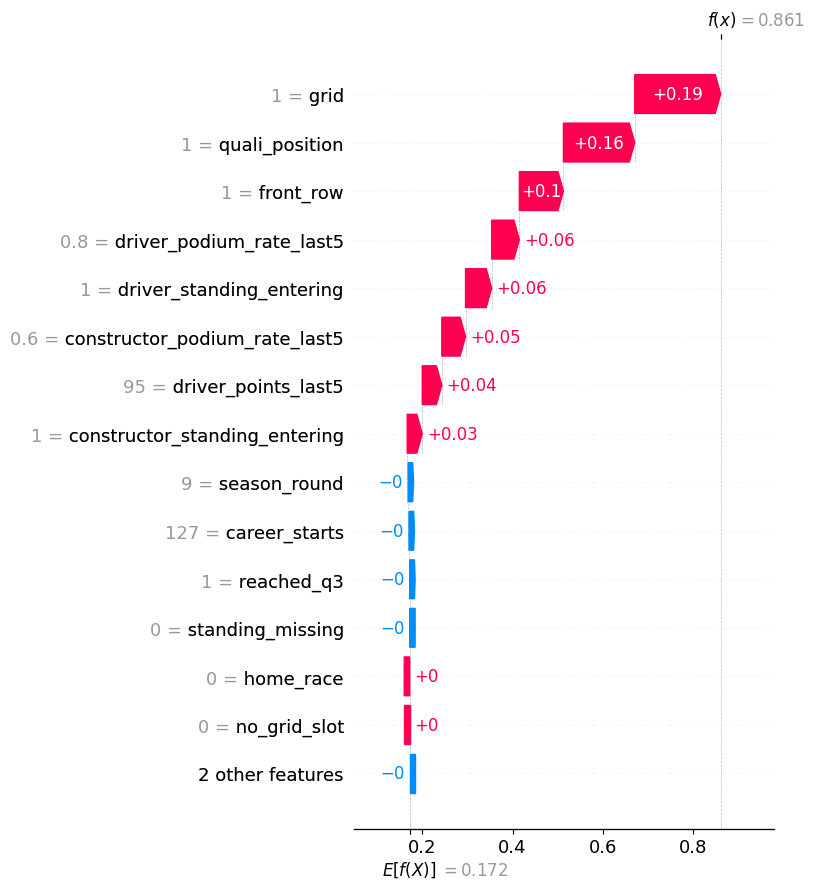

Strongest factor raising the probability: grid
Strongest factor lowering the probability: season_round
These are explanations of the model's prediction, not causes of podium finishes.


In [37]:
sample_predictions = podium_predict_proba(X_explain)
local_position = int(np.argmax(sample_predictions))
local_row = X_explain.iloc[local_position]
local_explanation = shap_values[local_position]

validation_metadata = modeling.loc[masks["validation"], ["raceId", "driverId", "year", "podium"]].reset_index(drop=True)
record = validation_metadata.iloc[int(explain_positions[local_position])]
local_probability = float(sample_predictions[local_position])
local_base = float(np.asarray(local_explanation.base_values).item())

print(f"Driver ID: {int(record['driverId'])} | Race ID: {int(record['raceId'])} | Year: {int(record['year'])}")
print(f"Observed actual podium: {bool(record['podium'])}")
print(f"Predicted podium probability: {local_probability:.2%}")
print(f"Baseline/background podium probability: {local_base:.2%}")
print(f"Baseline + SHAP contributions: {(local_base + local_explanation.values.sum()):.2%}")

local_contributions = pd.DataFrame({
    "feature": MODEL_FEATURES,
    "input_value": local_row.to_numpy(),
    "SHAP_probability_contribution": np.asarray(local_explanation.values, dtype=float),
})
local_contributions["direction"] = np.where(local_contributions["SHAP_probability_contribution"] >= 0,
                                             "raises podium probability", "lowers podium probability")
local_contributions = local_contributions.reindex(
    local_contributions["SHAP_probability_contribution"].abs().sort_values(ascending=False).index
).reset_index(drop=True)
display(local_contributions.round(4))
local_contributions.to_csv(PATHS["audit"] / "local_shap_example.csv", index=False)

shap.plots.waterfall(local_explanation, max_display=15, show=False)
save(plt.gcf(), "24_local_shap_waterfall.png")

main_positive = local_contributions.loc[local_contributions["SHAP_probability_contribution"] > 0, "feature"]
main_negative = local_contributions.loc[local_contributions["SHAP_probability_contribution"] < 0, "feature"]
print("Strongest factor raising the probability:", main_positive.iloc[0] if len(main_positive) else "none")
print("Strongest factor lowering the probability:", main_negative.iloc[0] if len(main_negative) else "none")
print("These are explanations of the model's prediction, not causes of podium finishes.")

LIME local contributions (podium class) for the same row as the SHAP waterfall:


,feature_condition,weight
0,front_row > 0.00,0.113793
1,quali_position <= 6.00,0.105242
2,grid <= 6.00,0.101385
3,driver_podium_rate_last5 > 0.20,0.064530
4,driver_standing_entering <= 6.00,0.046909
5,driver_points_last5 > 24.00,0.045924
6,constructor_podium_rate_last5 > 0.20,0.038515
7,constructor_standing_entering <= 3.00,0.027263
8,quali_position_missing <= 0.00,0.026829
9,form_missing <= 0.00,0.013620


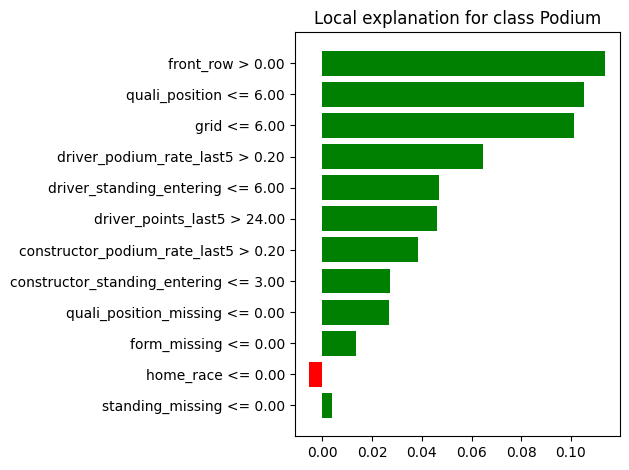

LIME estimates how the model behaves near this row. Its weights are not causal effects.


In [38]:
from lime.lime_tabular import LimeTabularExplainer

# LIME does not accept missing values; the imputer is fit on training rows only.
lime_imputer = SimpleImputer(strategy="median").fit(X_train[MODEL_FEATURES])
lime_train = lime_imputer.transform(X_train[MODEL_FEATURES])
lime_record = lime_imputer.transform(X_explain.iloc[[local_position]])[0]
lime_explainer = LimeTabularExplainer(
    training_data=lime_train,
    feature_names=MODEL_FEATURES,
    class_names=["Not podium", "Podium"],
    discretize_continuous=True,
    mode="classification", random_state=RANDOM_STATE,
)
def lime_predict_proba(array):
    return selected_pipeline.predict_proba(pd.DataFrame(array, columns=MODEL_FEATURES))
lime_explanation = lime_explainer.explain_instance(
    lime_record, lime_predict_proba,
    labels=(1,), num_features=min(12, len(MODEL_FEATURES)), num_samples=1500,
)
print("LIME local contributions (podium class) for the same row as the SHAP waterfall:")
display(pd.DataFrame(lime_explanation.as_list(label=1), columns=["feature_condition", "weight"]))
fig = lime_explanation.as_pyplot_figure(label=1)
save(fig, "25_local_lime.png")
print("LIME estimates how the model behaves near this row. Its weights are not causal effects.")

The waterfall and the LIME bars describe the same row, and they should agree on direction: the conditions that LIME weights positively are the features whose SHAP contribution is positive. Where the two differ in size, the reason is method: SHAP attributes the exact probability, LIME fits a local linear surrogate. Both say what the model used for this one driver in this one race. Neither says why the driver finished where they did.

## 20. Inference on one complete row and one partial row

`predict_podium` takes one driver-race as a dictionary of pre-race fields and returns the probability, the yes-or-no call at the frozen validation threshold, and the list of fields that were missing. Missing fields stay missing and the fitted pipeline fills them from the training medians. The second call is the same test row with qualifying position and the entering driver standing removed, and the two missingness flags set to 1. Nothing from the race result is passed in.

In [39]:
def predict_podium(record, pipeline=None, threshold=None):
    pipeline = selected_pipeline if pipeline is None else pipeline
    threshold = thresholds[chosen] if threshold is None else threshold
    row = {column: record.get(column, np.nan) for column in MODEL_FEATURES}
    features = pd.DataFrame([row], columns=MODEL_FEATURES).astype(float)
    probability = float(pipeline.predict_proba(features)[0, 1])
    return {
        "podium_probability": probability,
        "predicted_podium": bool(probability >= threshold),
        "threshold": float(threshold),
        "missing_fields": [column for column in MODEL_FEATURES if pd.isna(row[column])],
    }

test_metadata = modeling.loc[masks["test"], ["raceId", "driverId", "year", "podium"]].reset_index(drop=True)
test_features = X_test[MODEL_FEATURES].reset_index(drop=True)
complete_mask = test_features.notna().all(axis=1).to_numpy()
test_scores = selected_pipeline.predict_proba(test_features)[:, 1]
demo_index = int(np.argmax(np.where(complete_mask, test_scores, -1)))
complete_record = test_features.iloc[demo_index].to_dict()
partial_record = dict(complete_record)
for column in ("quali_position", "driver_standing_entering"):
    partial_record[column] = np.nan
partial_record["quali_position_missing"] = 1.0
partial_record["standing_missing"] = 1.0

meta = test_metadata.iloc[demo_index]
complete_result = predict_podium(complete_record)
partial_result = predict_podium(partial_record)
inference_demo = pd.DataFrame([
    {"record": "complete test row", "raceId": int(meta["raceId"]), "driverId": int(meta["driverId"]),
     "year": int(meta["year"]), "actual_podium": bool(meta["podium"]), **complete_result},
    {"record": "same row, qualifying and standing removed", "raceId": int(meta["raceId"]), "driverId": int(meta["driverId"]),
     "year": int(meta["year"]), "actual_podium": bool(meta["podium"]), **partial_result},
])
display(inference_demo)
inference_demo.to_csv(PATHS["audit"] / "inference_demo.csv", index=False)
print("Complete row:", complete_result)
print("Partial row:", partial_result)
if complete_result["predicted_podium"] != partial_result["predicted_podium"]:
    print("Removing the two fields moved the probability across the frozen threshold, so the yes-or-no call changed.")
else:
    print("The probability moved, and the yes-or-no call at the frozen threshold did not change.")

,record,raceId,driverId,year,actual_podium,podium_probability,predicted_podium,threshold,missing_fields
0,complete test row,1082,830,2022,True,0.880898,True,0.333128,[]
1,"same row, qualifying and standing removed",1082,830,2022,True,0.592673,True,0.333128,"[quali_position, driver_standing_entering]"


Complete row: {'podium_probability': 0.8808983904034706, 'predicted_podium': True, 'threshold': 0.3331284337343871, 'missing_fields': []}
Partial row: {'podium_probability': 0.592672889138557, 'predicted_podium': True, 'threshold': 0.3331284337343871, 'missing_fields': ['quali_position', 'driver_standing_entering']}
The probability moved, and the yes-or-no call at the frozen threshold did not change.
